In [1]:
import numpy as np
import pandas as pd
import itertools
import matplotlib.pyplot as plt
from matplotlib import cm
from datetime import date
import re
from tqdm import tqdm
import time
# from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr, rankdata, fisher_exact, describe, hypergeom
from scipy.spatial.distance import jaccard, euclidean, cosine, pdist, squareform
import functools
import operator
import gzip
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from scipy.cluster import hierarchy
import sys
import os
from functools import partial
from contextlib import closing
from multiprocessing import Pool
import re
import h5py
from collections import Counter
from region_comparison_combine_scores_CT20220713 import combine_scores
from operator import is_not
import upsetplot

today = date.today()

In [2]:
def kde_wrapper(data, bw=0.1):
    fig = plt.figure()
    fig.patch.set_facecolor('white')
    
    sns.kdeplot(data, bw_adjust=bw)
    print(describe(data))
    return fig

**Gene Set Info**

In [3]:
#all gene set
pickle_in = open('/home/ctrader/region_similarity/data/gene2allgeneset_dict_CT20220719.pickle', 'rb')
gene2allgeneset = pickle.load(pickle_in)
pickle_in.close()
total_genes = np.array(list(gene2allgeneset.keys()))
del gene2allgeneset

#c1 gene set 
pickle_in = open('/home/ctrader/region_similarity/data/gene2c1geneset_dict_CT20220725.pickle', 'rb')
gene2c1geneset = pickle.load(pickle_in)
pickle_in.close()

#c2 gene set 
pickle_in = open('/home/ctrader/region_similarity/data/gene2c2geneset_dict_CT20220725.pickle', 'rb')
gene2c2geneset = pickle.load(pickle_in)
pickle_in.close()

#hallmark gene set
pickle_in = open('/home/ctrader/region_similarity/data/gene2hallmarkgeneset_dict_CT20220718.pickle', 'rb')
gene2hallmarkgeneset = pickle.load(pickle_in)
pickle_in.close()

In [4]:
#reversing dictionaries
hallmarkgeneset2gene = {}
for gene in gene2hallmarkgeneset.keys():
    gene_sets = gene2hallmarkgeneset[gene]
    for gene_set in gene_sets:
        if gene_set not in hallmarkgeneset2gene:
            hallmarkgeneset2gene[gene_set] = np.array([gene])
        else:
            hallmarkgeneset2gene[gene_set] = np.append(hallmarkgeneset2gene[gene_set], np.array([gene]))
            
c1geneset2gene = {}
for gene in gene2c1geneset.keys():
    gene_sets = gene2c1geneset[gene]
    for gene_set in gene_sets:
        if gene_set not in c1geneset2gene:
            c1geneset2gene[gene_set] = np.array([gene])
        else:
            c1geneset2gene[gene_set] = np.append(c1geneset2gene[gene_set], np.array([gene]))
            
c2geneset2gene = {}
for gene in gene2c2geneset.keys():
    gene_sets = gene2c2geneset[gene]
    for gene_set in gene_sets:
        if gene_set not in c2geneset2gene:
            c2geneset2gene[gene_set] = np.array([gene])
        else:
            c2geneset2gene[gene_set] = np.append(c2geneset2gene[gene_set], np.array([gene]))

In [5]:
hallmark_gene_sets = list(hallmarkgeneset2gene.keys())
c1_gene_sets = list(c1geneset2gene.keys())
c2_gene_sets = list(c2geneset2gene.keys())

all_gene_sets = np.unique(np.append(np.append(hallmark_gene_sets, c1_gene_sets), c2_gene_sets))

In [6]:
#proteinID to gene name
pickle_in = open('/home/ctrader/region_similarity/data/gene_proteinID2genename_dict_CT20220712.pickle', 'rb')
id2gene = pickle.load(pickle_in)

#finding gene to protein ind
gene2id = {}
for key, val in zip(id2gene.keys(), id2gene.values()):
    if val not in gene2id:
        gene2id[val] = np.array([key])
    else:
        gene2id[val] = np.append(gene2id[val], np.array([key]))

**Gene2region dictionary**

In [7]:
pickle_in = open('/home/ctrader/region_similarity/data/gene2regionwithpromoterbp_25kb_dict_CT20220726.pickle', 'rb')
gene2promoterregion = pickle.load(pickle_in)
pickle_in.close()

**OOE files**

In [8]:
DHS_ooe_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220727.DHSpromoteronlyoee.hdf5'
TF_ooe_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220727.TFpromoteronlyoee.hdf5'
epilogos_ooe_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220727.epilogospromoteronlyoee.hdf5'

In [9]:
#loading order of each component
f = open('/home/ctrader/region_similarity/data/regions_25kb_CT20220708.TFmapped.bed', 'r')
TF_component_order = np.array(f.readline().strip().split('\t'))[3:]
f.close()

f = open('/home/ctrader/region_similarity/data/regions_25kb_CT20220708.DHSmapped.bed', 'r')
DHS_component_order = np.array(f.readline().strip().split('\t'))[3:]
f.close()

f = open('/home/ctrader/region_similarity/data/regions_25kb_CT20220708.epilogosmapped.bed', 'r')
epilogos_component_order = np.array(f.readline().strip().split('\t'))[3:]
f.close()

**DHS enrichment for genes**

In [10]:
gene_dhs_df = pd.read_csv('/home/ctrader/region_similarity/data/gene_ooe_all_WM20181115.txt', delimiter='\t')

In [11]:
DHS_comps_paper = np.array(['Placental / trophoblast', 'Lymphoid', 'Myeloid / erythroid', 'Cardiac', 
                            'Musculoskeletal', 'Vascular / endothelial', 'Primitive / embryonic', 
                            'Neural', 'Digestive', 'Stromal A', 'Stromal B', 'Renal / cancer', 
                            'Cancer / epithelial', 'Pulmonary devel.', 'Organ devel. / renal', 
                            'Tissue invariant'])
# DHS_comps_alpha = np.array(['Cancer / epithelial', 'Cardiac', 'Digestive', 'Lymphoid', 'Musculoskeletal', 
#                             'Myeloid / erythroid', 'Neural', 'Organ devel. / renal', 'Placental / trophoblast', 
#                             'Primitive / embryonic', 'Pulmonary devel.', 'Renal / cancer', 'Stromal A', 'Stromal B', 
#                             'Tissue invariant', 'Vascular / endothelial'])
DHS_comps_nmf = np.array(['Tissue invariant', 'Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 
                          'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 
                          'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 
                          'Myeloid / erythroid', 'Cancer / epithelial'])
# alpha2paper_order = np.array([8, 3, 5, 1, 4, 15, 9, 6, 2, 12, 13, 11, 0, 10, 7, 14])
nmf2paper_order = np.array([6, 4, 14, 8, 11, 13, 2, 7, 12, 1, 3, 5, 15, 10, 9, 0])
DHS_color = np.array(['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', 
                      '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3'])

**All STRING associations**

In [12]:
#all associations
all_df = pd.read_csv('/home/ctrader/region_similarity/data/9606.protein.links.full.v11.5.txt', sep=' ')

# id1 = all_df['protein1'].str.split('.', expand=True)[1]
# id2 = all_df['protein2'].str.split('.', expand=True)[1]
# all_df['protein1'] = id1
# all_df['protein2'] = id2

all_protein_combos = all_df[['protein1', 'protein2']].to_numpy()
all_protein_combos_sorted = np.sort(all_protein_combos, axis=1)

#dropping repeated inds
all_used_associations = set()
inds_to_drop = []
for row_ind in range(len(all_protein_combos_sorted)):
    row = all_protein_combos_sorted[row_ind]
    tup = (row[0], row[1])
    if tup in all_used_associations:
        inds_to_drop.append(row_ind)
    else:
        all_used_associations.add(tup)
inds_to_drop = np.array(inds_to_drop)
all_df = all_df.drop(inds_to_drop)


all_df.loc[:, all_df.columns[2:]] = all_df[all_df.columns[2:]].astype(int)
all_df['neighborhood'] = all_df[['neighborhood_transferred', 'neighborhood']].max(axis=1).astype(int)
all_df['coexpression'] = all_df[['coexpression_transferred', 'coexpression']].max(axis=1).astype(int)
all_df['experiments'] = all_df[['experiments_transferred', 'experiments']].max(axis=1).astype(int)
all_df['database'] = all_df[['database_transferred', 'database']].max(axis=1).astype(int)
all_df['textmining'] = all_df[['textmining_transferred', 'textmining']].max(axis=1).astype(int)
all_df = all_df[['protein1', 'protein2', 'neighborhood', 'fusion', 'cooccurence', 'homology', 'coexpression', 
                 'experiments', 'database', 'textmining', 'combined_score']]


all_df_arr = all_df.iloc[:, 2:].to_numpy()
all_df_mean = np.mean(all_df_arr, axis=0)

In [18]:
string_label_dict = {
    'coexpression' : 'Co-expressed',
    'cooccurence' : 'Co-evolved',
    'database' : 'Co-annotated',
    'experiments' : 'Interacts in vitro',
    'fusion' : 'Fused in Other Species',
    'homology' : 'Has Common Ancestory',
    'neighborhood' : 'is Nearby',
    'textmining' : 'Co-occurs in Literature'
}

**Genes sent by WM 7/21/22**

In [8]:
#genes from lists
genes_to_test1 = np.array(['CLPB', 'IFIT2', 'IFIT1', 'IRF7', 'OAS1', 'OASL', 'HERC5', 'XAF1', 'MX1', 'RSAD2', 'IFIT3', 
                           'CMPK2', 'ISG15', 'IFI6', 'IFI44', 'HELZ2', 'IFIT5', 'USP18', 'CD160', 'NRIR', 'HERC6', 
                           'NPIPA5', 'EEF1A2', 'KB-1208A12.3', 'IFI44L'])

genes_to_test2 = np.array(['CLPB', 'XAF1', 'ASS1', 'KIAA1614-AS1', 'IFI44', 'PMAIP1', 'MX1', 'IFI6', 'IFIT5', 
                           'OAS3', 'ARHGAP36', 'IFIT2', 'IFI44L', 'EPSTI1', 'DDX60', 'CMPK2', 'PPP1R14A', 
                           'RPS15AP12', 'IRF7', 'AC016907.3', 'EIF2AK2', 'ISG15', 'OASL', 'HERC5', 'MX2'])

#finding protein IDs
ids_to_test1 = np.array([])
for gene in genes_to_test1:
    if gene not in ['NRIR', 'KB-1208A12.3']:
        ids_to_test1 = np.append(ids_to_test1, gene2id[gene])
ids_to_test1_set = set(ids_to_test1)

ids_to_test2 = np.array([])
for gene in genes_to_test2:
    if gene not in ['KIAA1614-AS1', 'RPS15AP12', 'AC016907.3']:
        ids_to_test2 = np.append(ids_to_test2, gene2id[gene])
ids_to_test2_set = set(ids_to_test2)

#collecting all associations from genes of interest
string_scores_for_ids = []

filename = '/home/ctrader/region_similarity/data/9606.protein.links.full.v11.5.txt'
f = open(filename, 'r')
for line in f.readlines()[1:]:
    line = line.strip().split(' ')
    if (line[0].split('.')[1] in ids_to_test1_set) or (line[0].split('.')[1] in ids_to_test2_set):
        line[0] = line[0].split('.')[1]
        line[1] = line[1].split('.')[1]
        string_scores_for_ids.append(line)
string_scores_for_ids = np.array(string_scores_for_ids)
f.close()

#Splitting
set_1_scores = string_scores_for_ids[np.isin(string_scores_for_ids[:, 0], ids_to_test1), :]
set_2_scores = string_scores_for_ids[np.isin(string_scores_for_ids[:, 0], ids_to_test2), :]

#if ids have gene associations
set_1_scores_g = []
for row in set_1_scores:
    new_row = []
    if row[0] in id2gene:
        new_row.append(id2gene[row[0]])
    else:
        new_row.append(row[0])
        
    if row[1] in id2gene:
        new_row.append(id2gene[row[1]])
    else:
        new_row.append(row[1])
    
    for i in range(2, len(row)):
        new_row.append(row[i])
    set_1_scores_g.append(new_row)
set_1_scores_g = np.array(set_1_scores_g)

set_2_scores_g = []
for row in set_2_scores:
    new_row = []
    if row[0] in id2gene:
        new_row.append(id2gene[row[0]])
    else:
        new_row.append(row[0])
        
    if row[1] in id2gene:
        new_row.append(id2gene[row[1]])
    else:
        new_row.append(row[1])
    
    for i in range(2, len(row)):
        new_row.append(row[i])
    set_2_scores_g.append(new_row)
set_2_scores_g = np.array(set_2_scores_g)

#DataFrame
set_2_df = pd.DataFrame(set_2_scores_g, columns = ['Gene1', 'Gene2', 'neighborhood', 'neighborhood_transferred',
                                                    'fusion', 'cooccurence', 'homology', 'coexpression',
                                                    'coexpression_transferred', 'experiments', 'experiments_transferred',
                                                    'database', 'database_transferred', 'textmining', 'textmining_transferred',
                                                    'combined_score'])
set_1_df = pd.DataFrame(set_1_scores_g, columns = ['Gene1', 'Gene2', 'neighborhood', 'neighborhood_transferred',
                                                    'fusion', 'cooccurence', 'homology', 'coexpression',
                                                    'coexpression_transferred', 'experiments', 'experiments_transferred',
                                                    'database', 'database_transferred', 'textmining', 'textmining_transferred',
                                                    'combined_score'])

set_1_df.loc[:, set_1_df.columns[2:]] = set_1_df[set_1_df.columns[2:]].astype(int)
set_2_df.loc[:, set_2_df.columns[2:]] = set_2_df[set_2_df.columns[2:]].astype(int)

#saving interassociations
# set_1_df[set_1_df['Gene2'].isin(genes_to_test1)].to_csv('/home/ctrader/region_similarity/data/STRING_scores_for_genes_provided_by_WM_set1_interassociations_CT20220722.tsv', sep='\t')
# set_2_df[set_2_df['Gene2'].isin(genes_to_test2)].to_csv('/home/ctrader/region_similarity/data/STRING_scores_for_genes_provided_by_WM_set2_interassociations_CT20220722.tsv', sep='\t')

set_1_used_associations = set()
for index in np.array(set_1_df.index):
    tup = (set_1_df.loc[index]['Gene1'], set_1_df.loc[index]['Gene2'])
    tup = tuple(np.sort(tup))
    if tup in set_1_used_associations:
        set_1_df = set_1_df.drop(index)
    else:
        set_1_used_associations.add(tup)
        
set_2_used_associations = set()
for index in np.array(set_2_df.index):
    tup = (set_2_df.loc[index]['Gene1'], set_2_df.loc[index]['Gene2'])
    tup = tuple(np.sort(tup))
    if tup in set_2_used_associations:
        set_2_df = set_2_df.drop(index)
    else:
        set_2_used_associations.add(tup)

#interassociations
set_1_df_inter = set_1_df[set_1_df['Gene2'].isin(genes_to_test1)]
set_2_df_inter = set_2_df[set_2_df['Gene2'].isin(genes_to_test2)]

#just main gene of interest
set_1_df_clpb = set_1_df[(set_1_df['Gene1']=='CLPB') | (set_1_df['Gene2']=='CLPB')]
set_2_df_clpb = set_2_df[(set_2_df['Gene1']=='CLPB') | (set_2_df['Gene2']=='CLPB')]

#interassociations with just main gene of interest
set_1_df_clpb_inter = set_1_df_clpb[(set_1_df_clpb['Gene2'].isin(genes_to_test1)) & (set_1_df_clpb['Gene1'].isin(genes_to_test1))]
set_2_df_clpb_inter = set_2_df_clpb[(set_2_df_clpb['Gene2'].isin(genes_to_test2)) & (set_2_df_clpb['Gene1'].isin(genes_to_test2))]

In [35]:
set_2_df_clpb_inter

,Gene1,Gene2,neighborhood,neighborhood_transferred,fusion,cooccurence,homology,coexpression,coexpression_transferred,experiments,experiments_transferred,database,database_transferred,textmining,textmining_transferred,combined_score
2190,CMPK2,CLPB,0,153,0,0,0,0,62,0,0,0,0,0,58,186
2460,OASL,CLPB,0,0,0,0,0,0,66,0,179,0,0,0,115,262
6657,CLPB,DDX60,0,111,0,0,0,0,76,0,0,0,0,0,111,205
7006,CLPB,MX2,0,0,0,0,0,0,62,0,0,0,0,43,134,154
7088,CLPB,MX1,0,0,0,0,0,0,62,0,0,0,0,0,134,152
7602,CLPB,IFIT2,0,0,0,0,0,0,92,0,166,0,0,0,134,286
7819,CLPB,IFIT5,0,0,0,0,0,0,92,0,166,0,0,0,134,286


In [34]:
set_1_df_inter[(set_1_df_inter['Gene1']=='CD160') | (set_1_df_inter['Gene1']=='CD160')]

,Gene1,Gene2,neighborhood,neighborhood_transferred,fusion,cooccurence,homology,coexpression,coexpression_transferred,experiments,experiments_transferred,database,database_transferred,textmining,textmining_transferred,combined_score


In [12]:
set_1_df_mean = set_1_df.mean(axis=0)
set_2_df_mean = set_2_df.mean(axis=0)

set_1_df_inter_mean = set_1_df_inter.mean(axis=0)
set_2_df_inter_mean = set_2_df_inter.mean(axis=0)

all_df_mean = np.mean(all_df_arr, axis=0)

set_1_df_clpb_mean = set_1_df_clpb.mean(axis=0)
set_2_df_clpb_mean = set_2_df_clpb.mean(axis=0) #dont need, same as set_1_df_clpb_mean

set_1_df_clpb_inter_mean = set_1_df_clpb_inter.mean(axis=0)
set_2_df_clpb_inter_mean = set_2_df_clpb_inter.mean(axis=0)

/tmp/ipykernel_63903/236738478.py:1: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_1_df_mean = set_1_df.mean(axis=0)
/tmp/ipykernel_63903/236738478.py:2: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_2_df_mean = set_2_df.mean(axis=0)
/tmp/ipykernel_63903/236738478.py:4: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_1_df_inter_mean = set_1_df_inter.mean(axis=0)
/tmp/ipykernel_63903/236738478.py:5: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'num

Text(0.5, 1.0, 'Average STRING Metric Score for Select Genes')

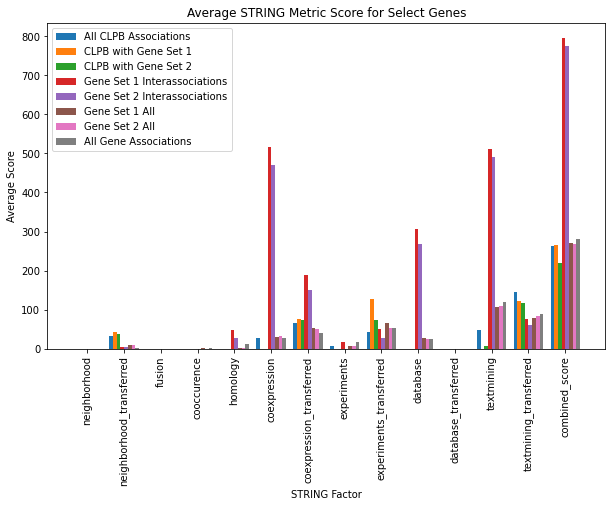

In [8]:
fig = plt.figure(figsize=(10,6))
fig.patch.set_facecolor('white')

plt.bar(np.arange(len(set_1_df_clpb_mean))-0.35, np.array(set_1_df_clpb_mean), width=0.1)
plt.bar(np.arange(len(set_1_df_clpb_inter_mean))-0.25, np.array(set_1_df_clpb_inter_mean), width=0.1)
plt.bar(np.arange(len(set_2_df_clpb_inter_mean))-0.15, np.array(set_2_df_clpb_inter_mean), width=0.1)
plt.bar(np.arange(len(set_1_df_inter_mean))-0.05, np.array(set_1_df_inter_mean), width=0.1)
plt.bar(np.arange(len(set_2_df_inter_mean))+0.05, np.array(set_2_df_inter_mean), width=0.1)
plt.bar(np.arange(len(set_1_df_mean))+0.15, np.array(set_1_df_mean), width=0.1)
plt.bar(np.arange(len(set_2_df_mean))+0.25, np.array(set_2_df_mean), width=0.1)
plt.bar(np.arange(len(all_df_mean))+0.35, all_df_mean, width=0.1)

plt.xticks(np.arange(len(all_df_mean)), np.array(set_1_df_inter_mean.index), rotation=90)
plt.legend(['All CLPB Associations', 'CLPB with Gene Set 1', 'CLPB with Gene Set 2',
            'Gene Set 1 Interassociations', 'Gene Set 2 Interassociations', 'Gene Set 1 All', 'Gene Set 2 All',
            'All Gene Associations'])

plt.xlabel('STRING Factor')
plt.ylabel('Average Score')
plt.title('Average STRING Metric Score for Select Genes')

In [56]:
def make_upset(data_for_upset, labels_for_upset, title):
    bool_for_upset = np.where(data_for_upset>0, True, False)
    indicators_for_upset = {}
    for i, l in zip(range(len(labels_for_upset)), labels_for_upset):
        indicators_for_upset[l] = bool_for_upset[:, i]

    upset_data = upsetplot.from_indicators(indicators_for_upset)
    upset_data = upset_data.groupby(list(upset_data.index.names)).count()

    #sorting upset categories
    upset_factors = np.array(upset_data.index.names)
    upset_factor_counts = np.array([])
    for i in range(len(upset_factors)):
        upset_factor_counts = np.append(upset_factor_counts, np.sum(upset_data.unstack(level=i)[True]))
    upset_factors_sorted = upset_factors[np.argsort(upset_factor_counts)]
    sorted_upset_data = upset_data.reorder_levels(upset_factors_sorted)

    fig = plt.figure(figsize=(10,10))

    upsetplot.plot(sorted_upset_data, sort_categories_by=None, min_subset_size=1, show_counts=True, sort_by='cardinality')
#     plt.yscale('log')

    plt.ylabel('Number of Regions')
    plt.title(title)
    
    plt.savefig('/home/ctrader/region_similarity/data/gene_DHS_TF_enrichments/' + title + '_upset_CT20220802.pdf', 
                bbox_inches='tight', 
                dpi=400, 
                facecolor="#FFFFFF", 
                edgecolor="#FFFFFF", 
                transparent=False)
    plt.show()

Scores for Gene Set 1 Interassociations


<Figure size 720x720 with 0 Axes>

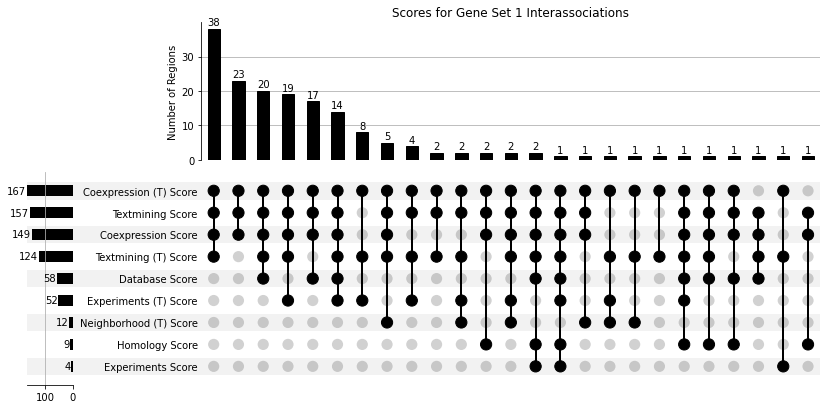

Scores for Gene Set 2 Interassociations


<Figure size 720x720 with 0 Axes>

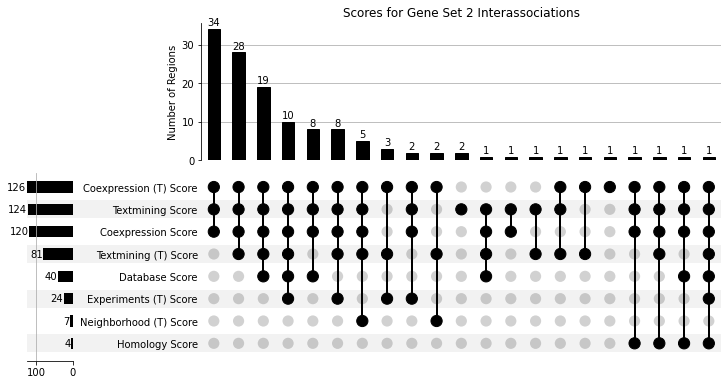

In [10]:
data_for_upset = set_1_df_inter.iloc[:, 2:-1].to_numpy()

labels_for_upset = ['Neighborhood Score', 'Neighborhood (T) Score', 'Fusion Score', 
                    'Cooccurence Score', 'Homology Score', 'Coexpression Score', 
                    'Coexpression (T) Score', 'Experiments Score', 'Experiments (T) Score', 
                    'Database Score', 'Database (T) Score', 'Textmining Score', 
                    'Textmining (T) Score']
title='Scores for Gene Set 1 Interassociations'
make_upset(data_for_upset, labels_for_upset, title)

data_for_upset = set_2_df_inter.iloc[:, 2:-1].to_numpy()
title='Scores for Gene Set 2 Interassociations'
make_upset(data_for_upset, labels_for_upset, title)

In [14]:
#gene set analysis
gene_sets_of_interest = np.array([])
for gene in genes_to_test1:
    #finding the gene sets for each gene
    if gene in gene2hallmarkgeneset:
        gene_sets_of_interest = np.append(gene_sets_of_interest, gene2hallmarkgeneset[gene])
    if gene in gene2c1geneset:
        gene_sets_of_interest = np.append(gene_sets_of_interest, gene2c1geneset[gene])
    if gene in gene2c2geneset:
        gene_sets_of_interest = np.append(gene_sets_of_interest, gene2c2geneset[gene])
        
gene_sets_of_interest = np.unique(gene_sets_of_interest)

significant_gene_sets_set1 = []
set1_pvals = []
for gene_set in gene_sets_of_interest:
    #finding genes for each gene set
    if gene_set in hallmarkgeneset2gene:
        genes_in_gene_set_of_interest = hallmarkgeneset2gene[gene_set] 
    elif gene_set in c1geneset2gene:
        genes_in_gene_set_of_interest = c1geneset2gene[gene_set] 
    else:
        genes_in_gene_set_of_interest = c2geneset2gene[gene_set]
    #fisher's exact test
    a = len(total_genes[(np.isin(total_genes, genes_to_test1)) & 
                        (np.isin(total_genes, genes_in_gene_set_of_interest))])
    b = len(total_genes[(~np.isin(total_genes, genes_to_test1)) & 
                        (np.isin(total_genes, genes_in_gene_set_of_interest))])
    c = len(total_genes[(np.isin(total_genes, genes_to_test1)) & 
                        (~np.isin(total_genes, genes_in_gene_set_of_interest))])
    d = len(total_genes[(~np.isin(total_genes, genes_to_test1)) & 
                        (~np.isin(total_genes, genes_in_gene_set_of_interest))])
    conting = np.array([[a, b], [c, d]])
    odds, pval = fisher_exact(conting)
    if pval < 0.05 / len(gene_sets_of_interest): #bonferroni correction
        significant_gene_sets_set1.append(gene_set)
        set1_pvals.append(pval)
significant_gene_sets_set1 = np.array(significant_gene_sets_set1)
set1_pvals = np.array(set1_pvals)

In [190]:
genes_to_test1_inregion = []
for gene in genes_to_test1:
    if gene in gene2promoterregion:
        genes_to_test1_inregion.append(gene)
genes_to_test1_inregion = np.array(genes_to_test1_inregion)

genes_to_test2_inregion = []
for gene in genes_to_test2:
    if gene in gene2promoterregion:
        genes_to_test2_inregion.append(gene)
genes_to_test2_inregion = np.array(genes_to_test2_inregion)

In [87]:
regions_to_see = []
genes_to_test1_inregion = []
for gene in genes_to_test1:
    if gene in gene2promoterregion:
        regions_to_see.append(gene2promoterregion[gene])
        genes_to_test1_inregion.append(gene)
genes_to_test1_inregion = np.array(genes_to_test1_inregion)
    
regions_path = '/home/ctrader/region_similarity/data/Altius_25kb_hg38_maxMean_CT20220613.sorted.c1t3.bed'
f = open(regions_path, 'r')
regions = f.readlines()
top_regions = []
for ind in regions_to_see:
    top_regions.append(regions[ind].strip().split())
f.close()
top_regions = np.array(top_regions)

In [15]:
#gene set analysis
gene_sets_of_interest = np.array([])
for gene in genes_to_test2:
    #finding the gene sets for each gene
    if gene in gene2hallmarkgeneset:
        gene_sets_of_interest = np.append(gene_sets_of_interest, gene2hallmarkgeneset[gene])
    if gene in gene2c1geneset:
        gene_sets_of_interest = np.append(gene_sets_of_interest, gene2c1geneset[gene])
    if gene in gene2c2geneset:
        gene_sets_of_interest = np.append(gene_sets_of_interest, gene2c2geneset[gene])
        
gene_sets_of_interest = np.unique(gene_sets_of_interest)

significant_gene_sets_set2 = []
set2_pvals = []
for gene_set in gene_sets_of_interest:
    #finding genes for each gene set
    if gene_set in hallmarkgeneset2gene:
        genes_in_gene_set_of_interest = hallmarkgeneset2gene[gene_set] 
    elif gene_set in c1geneset2gene:
        genes_in_gene_set_of_interest = c1geneset2gene[gene_set] 
    else:
        genes_in_gene_set_of_interest = c2geneset2gene[gene_set]
    #fisher's exact test
    a = len(total_genes[(np.isin(total_genes, genes_to_test2)) & 
                        (np.isin(total_genes, genes_in_gene_set_of_interest))])
    b = len(total_genes[(~np.isin(total_genes, genes_to_test2)) & 
                        (np.isin(total_genes, genes_in_gene_set_of_interest))])
    c = len(total_genes[(np.isin(total_genes, genes_to_test2)) & 
                        (~np.isin(total_genes, genes_in_gene_set_of_interest))])
    d = len(total_genes[(~np.isin(total_genes, genes_to_test2)) & 
                        (~np.isin(total_genes, genes_in_gene_set_of_interest))])
    conting = np.array([[a, b], [c, d]])
    odds, pval = fisher_exact(conting)
    if pval < 0.05 / len(gene_sets_of_interest): #bonferroni correction
        significant_gene_sets_set2.append(gene_set)
        set2_pvals.append(pval)
significant_gene_sets_set2 = np.array(significant_gene_sets_set2)
set2_pvals = np.array(set2_pvals)

In [36]:
# for i in list(significant_gene_sets_set1[np.argsort(set1_pvals)]):
#     print(i)

In [37]:
# significant_gene_sets_set2[np.argsort(set2_pvals)]

In [67]:
gene2promoterregion['IFIT2']

9438

In [16]:
###getting regions for each gene set
regions_set1 = np.array([], dtype=int)
for gene in genes_to_test1:
    if gene in gene2promoterregion:
        regions_set1 = np.append(regions_set1, gene2promoterregion[gene])

regions_set2 = np.array([], dtype=int)
for gene in genes_to_test2:
    if gene in gene2promoterregion:
        regions_set2 = np.append(regions_set2, gene2promoterregion[gene])

In [84]:
# DHS_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220708.DHScosine.hdf5'
# DHS_hdf5 = h5py.File(DHS_hdf5_path, 'r')
# DHS_cosine_vals_full = DHS_hdf5['top_1000_cosine_vals'][:]
# DHS_similar_regions_full = DHS_hdf5['top_1000_similar_regions'][:]
# DHS_hdf5.close()
# test = np.where(DHS_cosine_vals_full > 0, DHS_similar_regions_full, 0)
# np.unique(test).shape

(86999,)

In [35]:
epilogos_ooe_hdf5 = h5py.File(epilogos_ooe_hdf5_path, 'r')
epilogos_ooe = epilogos_ooe_hdf5['ooe_arr'][:]
epilogos_ooe_hdf5.close()

DescribeResult(nobs=390929, minmax=(-6.929135166692417, 180.8979546355116), mean=1.2866581911293344, variance=6.092561044691292, skewness=8.71842876385074, kurtosis=212.27616784394817)


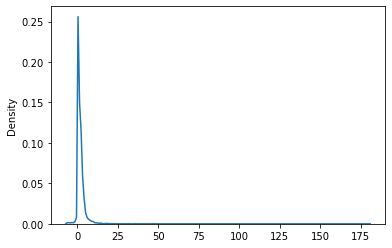

In [45]:
f = kde_wrapper(epilogos_ooe[epilogos_ooe!=0])

In [69]:
DHS_ooe[1]

array([0.87821068, 3.00831715, 0.        , 0.68985547, 1.04825478,
       1.14046454, 1.19324373, 0.69771511, 0.22099442, 0.67695455,
       0.        , 1.53799735, 1.44184277, 2.34749004, 0.45601597,
       1.67942103])

In [68]:
region_inds

array([12966,  9438,  9441, 10839, 18323, 18579, 56173, 29811, 46277,
       36306, 36306,    19,   855,  2459, 45353,  9441, 46495,  3829,
       56170, 27697, 45351,  2458])

In [75]:
# region_inds = regions_set1
# all_string_mean = all_df_mean
# set_string_mean = set_1_df_inter_mean

# DHS_ooe_hdf5 = h5py.File(DHS_ooe_hdf5_path, 'r')
# DHS_ooe = DHS_ooe_hdf5['ooe_arr'][:][region_inds]
# DHS_ooe_hdf5.close()

# TF_ooe_hdf5 = h5py.File(TF_ooe_hdf5_path, 'r')
# TF_ooe = TF_ooe_hdf5['ooe_arr'][:][region_inds]
# TF_ooe_hdf5.close()

# epilogos_ooe_hdf5 = h5py.File(epilogos_ooe_hdf5_path, 'r')
# epilogos_ooe = epilogos_ooe_hdf5['ooe_arr'][:][region_inds]
# epilogos_ooe_hdf5.close()

# #getting enrichment for all states
# DHS_ooe_mean = np.mean(DHS_ooe, axis=0)
# DHS_ooe_mean_log2 = np.log2(DHS_ooe_mean)

# TF_ooe_mean = np.mean(TF_ooe, axis=0)
# TF_ooe_mean_log2 = np.log2(TF_ooe_mean)

# epilogos_ooe_mean = np.mean(epilogos_ooe, axis=0)
# epilogos_ooe_mean = np.log2(epilogos_ooe_mean)

# string_ooe_mean = np.array(set_string_mean) / all_string_mean
# string_ooe_mean_log2 = np.log2(string_ooe_mean)

# #plotting
# fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10,8))
# fig.patch.set_facecolor('white')
# plt.subplots_adjust(wspace=0.2, hspace=0.8)

# axes = axes.ravel()

# axes[0].bar(np.arange(len(DHS_ooe_mean_log2)), DHS_ooe_mean_log2)
# axes[0].plot([-1, len(DHS_ooe_mean_log2)+1], [0, 0], c='k')

# axes[1].bar(np.arange(len(TF_ooe_mean_log2)), TF_ooe_mean_log2)
# axes[1].plot([-1, len(TF_ooe_mean_log2)+1], [0, 0], c='k')

# axes[2].bar(np.arange(len(epilogos_ooe_mean[:18]))-0.2, epilogos_ooe_mean[:18], width=0.4)
# axes[2].bar(np.arange(len(epilogos_ooe_mean[18:]))+0.2, epilogos_ooe_mean[18:], width=0.4)
# axes[2].legend(['Mean', 'Max'])
# axes[2].plot([-1, len(epilogos_ooe_mean[:18])+1], [0, 0], c='k')

# #need to handle -inf vals
# axes[3].bar(np.arange(len(string_ooe_mean_log2)), string_ooe_mean_log2)
# axes[3].plot([-1, len(string_ooe_mean_log2)+1], [0, 0], c='k')

# axes[0].set_xticks(np.arange(len(DHS_ooe_mean_log2)))
# axes[0].set_xticklabels(DHS_component_order, rotation=90)
# axes[0].set_xlim([-1, len(DHS_ooe_mean_log2)])

# axes[2].set_xticks(np.arange(len(epilogos_ooe_mean[:18])))
# axes[2].set_xticklabels(epilogos_component_order, rotation=90)
# axes[2].set_xlim([-1, len(epilogos_ooe_mean[:18])])


# axes[3].set_xticks(np.arange(len(string_ooe_mean_log2)))
# axes[3].set_xticklabels(set_string_mean.index, rotation=90)
# axes[3].set_xlim([-1, len(string_ooe_mean_log2)])

# fig.show()

In [187]:
np.isin(genes_to_test1, gene_dhs_df.index)

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True, False,  True,  True,  True,  True,  True])

In [98]:
DHS_component_order

array(['Cancer_epithelial', 'Cardiac', 'Digestive', 'Lymphoid',
       'Musculoskeletal', 'Myeloid_erythroid', 'Neural',
       'Organdevel_renal', 'Placental_trophoblast', 'Primitive_embryonic',
       'Pulmonarydevel', 'Renal_cancer', 'StromalA', 'StromalB',
       'Tissueinvariant', 'Vascular_endothelial'], dtype='<U21')

In [153]:
for i, j in zip(DHS_comps_paper, DHS_comps_alpha[alpha2paper_order]):
    print(i, j)

Placental / trophoblast Placental / trophoblast
Lymphoid Lymphoid
Myeloid / erythroid Myeloid / erythroid
Cardiac Cardiac
Musculoskeletal Musculoskeletal
Vascular / endothelial Vascular / endothelial
Primitive / embryonic Primitive / embryonic
Neural Neural
Digestive Digestive
Stromal A Stromal A
Stromal B Stromal B
Renal / cancer Renal / cancer
Cancer / epithelial Cancer / epithelial
Pulmonary devel. Pulmonary devel.
Organ devel. / renal Organ devel. / renal
Tissue invariant Tissue invariant


In [157]:
genes_to_test1_inregion.shape

(22,)

In [182]:
np.mean(np.log2(DHS_ooe), axis=0)

/tmp/ipykernel_63903/1914178473.py:1: RuntimeWarning: divide by zero encountered in log2
  np.mean(np.log2(DHS_ooe), axis=0)


array([       -inf,        -inf,        -inf,        -inf,        -inf,
              -inf,        -inf,        -inf,        -inf, -0.29226707,
              -inf,        -inf,        -inf, -0.13530429,        -inf,
              -inf])

/tmp/ipykernel_63903/1748941405.py:24: RuntimeWarning: invalid value encountered in true_divide
  string_ooe_mean = np.array(set_string_mean) / all_string_mean
/tmp/ipykernel_63903/1748941405.py:25: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)


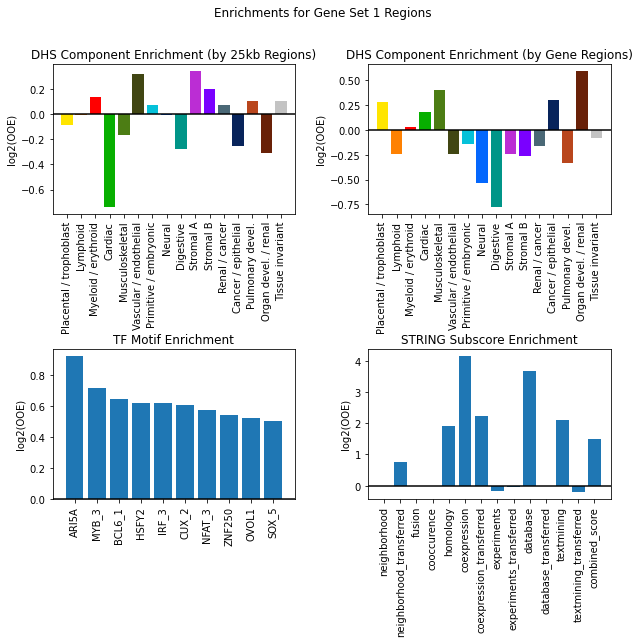

In [169]:
region_inds = regions_set1
all_string_mean = all_df_mean
set_string_mean = set_1_df_inter_mean

DHS_ooe_hdf5 = h5py.File(DHS_ooe_hdf5_path, 'r')
DHS_ooe = DHS_ooe_hdf5['ooe_arr'][:][region_inds]
DHS_ooe_hdf5.close()

DHS_ooe_mean = np.mean(DHS_ooe, axis=0)
DHS_ooe_mean_log2 = np.log2(DHS_ooe_mean)

gene_DHS_ooe_mean = np.array(gene_dhs_df.loc[genes_to_test1_inregion].mean())
gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)

TF_ooe_hdf5 = h5py.File(TF_ooe_hdf5_path, 'r')
TF_ooe = TF_ooe_hdf5['ooe_arr'][:][region_inds]
TF_ooe_hdf5.close()

TF_ooe_mean = np.mean(TF_ooe, axis=0)
TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
TF_inds = np.argsort(-TF_ooe_mean_log2)[:10]


string_ooe_mean = np.array(set_string_mean) / all_string_mean
string_ooe_mean_log2 = np.log2(string_ooe_mean)

#plotting
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10,8))
fig.patch.set_facecolor('white')
plt.subplots_adjust(wspace=0.3, hspace=0.9)

axes = axes.ravel()

axes[0].bar(np.arange(len(DHS_ooe_mean_log2[alpha2paper_order])), DHS_ooe_mean_log2[alpha2paper_order], color=DHS_color)
axes[0].plot([-1, len(DHS_ooe_mean_log2[alpha2paper_order])+1], [0, 0], c='k')

axes[1].bar(np.arange(len(gene_DHS_ooe_mean_log2)), gene_DHS_ooe_mean_log2, color=DHS_color)
axes[1].plot([-1, len(gene_DHS_ooe_mean_log2)+1], [0, 0], c='k')

axes[2].bar(np.arange(len(TF_ooe_mean_log2[TF_inds])), TF_ooe_mean_log2[TF_inds])
axes[2].plot([-1, len(TF_ooe_mean_log2[TF_inds])+1], [0, 0], c='k')

#need to handle -inf vals
axes[3].bar(np.arange(len(string_ooe_mean_log2)), string_ooe_mean_log2)
axes[3].plot([-1, len(string_ooe_mean_log2)+1], [0, 0], c='k')


axes[0].set_xticks(np.arange(len(DHS_ooe_mean_log2[alpha2paper_order])))
axes[0].set_xticklabels(DHS_comps_alpha[alpha2paper_order], rotation=90)
axes[0].set_xlim([-1, len(DHS_ooe_mean_log2[alpha2paper_order])])
axes[0].set_title('DHS Component Enrichment (by 25kb Regions)')
axes[0].set_ylabel('log2(OOE)')

axes[1].set_xticks(np.arange(len(gene_DHS_ooe_mean_log2)))
axes[1].set_xticklabels(DHS_comps_paper, rotation=90)
axes[1].set_xlim([-1, len(gene_DHS_ooe_mean_log2)])
axes[1].set_title('DHS Component Enrichment (by Gene Regions)')
axes[1].set_ylabel('log2(OOE)')

axes[2].set_xticks(np.arange(len(TF_ooe_mean_log2[TF_inds])))
axes[2].set_xticklabels(TF_component_order[TF_inds], rotation=90)
axes[2].set_xlim([-1, len(TF_ooe_mean_log2[TF_inds])])
axes[2].set_title('TF Motif Enrichment')
axes[2].set_ylabel('log2(OOE)')

axes[3].set_xticks(np.arange(len(string_ooe_mean_log2)))
axes[3].set_xticklabels(set_string_mean.index, rotation=90)
axes[3].set_xlim([-1, len(string_ooe_mean_log2)])
axes[3].set_title('STRING Subscore Enrichment')
axes[3].set_ylabel('log2(OOE)')

fig.suptitle('Enrichments for Gene Set 1 Regions')

fig.show()

/tmp/ipykernel_63903/461499381.py:20: RuntimeWarning: invalid value encountered in true_divide
  string_ooe_mean = np.array(set_string_mean) / all_string_mean
/tmp/ipykernel_63903/461499381.py:21: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)


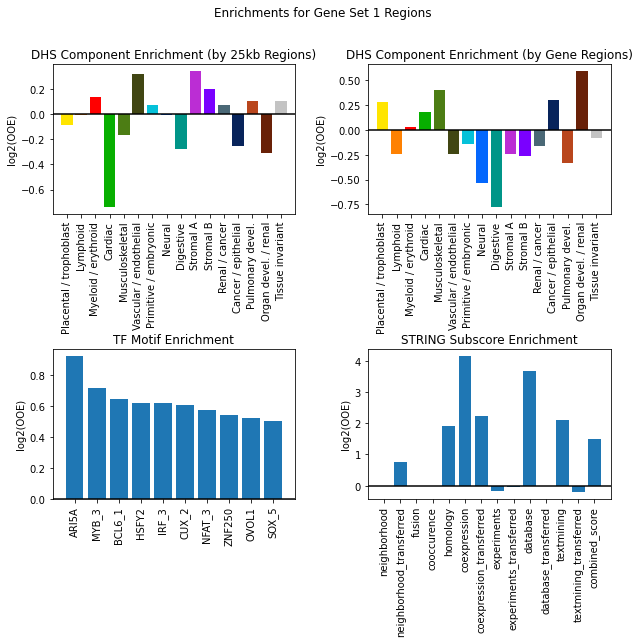

In [221]:
analyze_regions(regions_set1, all_df_mean, set_1_df_inter_mean, genes_to_test1_inregion, 'Enrichments for Gene Set 1 Regions')

In [ ]:
# #finding protein IDs
# ids_to_test1 = np.array([])
# for gene in genes_to_test1:
#     if gene not in ['NRIR', 'KB-1208A12.3']:
#         ids_to_test1 = np.append(ids_to_test1, gene2id[gene])
# ids_to_test1_set = set(ids_to_test1)

# ids_to_test2 = np.array([])
# for gene in genes_to_test2:
#     if gene not in ['KIAA1614-AS1', 'RPS15AP12', 'AC016907.3']:
#         ids_to_test2 = np.append(ids_to_test2, gene2id[gene])
# ids_to_test2_set = set(ids_to_test2)

#collecting all associations from genes of interest
# string_scores_for_ids = []

# filename = '/home/ctrader/region_similarity/data/9606.protein.links.full.v11.5.txt'
# f = open(filename, 'r')
# for line in f.readlines()[1:]:
#     line = line.strip().split(' ')
#     if (line[0].split('.')[1] in ids_to_test1_set) or (line[0].split('.')[1] in ids_to_test2_set):
#         line[0] = line[0].split('.')[1]
#         line[1] = line[1].split('.')[1]
#         string_scores_for_ids.append(line)
# string_scores_for_ids = np.array(string_scores_for_ids)
# f.close()

# #Splitting
# set_1_scores = string_scores_for_ids[np.isin(string_scores_for_ids[:, 0], ids_to_test1), :]
# set_2_scores = string_scores_for_ids[np.isin(string_scores_for_ids[:, 0], ids_to_test2), :]

# #if ids have gene associations
# set_1_scores_g = []
# for row in set_1_scores:
#     new_row = []
#     if row[0] in id2gene:
#         new_row.append(id2gene[row[0]])
#     else:
#         new_row.append(row[0])
        
#     if row[1] in id2gene:
#         new_row.append(id2gene[row[1]])
#     else:
#         new_row.append(row[1])
    
#     for i in range(2, len(row)):
#         new_row.append(row[i])
#     set_1_scores_g.append(new_row)
# set_1_scores_g = np.array(set_1_scores_g)

# set_2_scores_g = []
# for row in set_2_scores:
#     new_row = []
#     if row[0] in id2gene:
#         new_row.append(id2gene[row[0]])
#     else:
#         new_row.append(row[0])
        
#     if row[1] in id2gene:
#         new_row.append(id2gene[row[1]])
#     else:
#         new_row.append(row[1])
    
#     for i in range(2, len(row)):
#         new_row.append(row[i])
#     set_2_scores_g.append(new_row)
# set_2_scores_g = np.array(set_2_scores_g)

# #DataFrame
# set_2_df = pd.DataFrame(set_2_scores_g, columns = ['Gene1', 'Gene2', 'neighborhood', 'neighborhood_transferred',
#                                                     'fusion', 'cooccurence', 'homology', 'coexpression',
#                                                     'coexpression_transferred', 'experiments', 'experiments_transferred',
#                                                     'database', 'database_transferred', 'textmining', 'textmining_transferred',
#                                                     'combined_score'])
# set_1_df = pd.DataFrame(set_1_scores_g, columns = ['Gene1', 'Gene2', 'neighborhood', 'neighborhood_transferred',
#                                                     'fusion', 'cooccurence', 'homology', 'coexpression',
#                                                     'coexpression_transferred', 'experiments', 'experiments_transferred',
#                                                     'database', 'database_transferred', 'textmining', 'textmining_transferred',
#                                                     'combined_score'])

# set_1_df.loc[:, set_1_df.columns[2:]] = set_1_df[set_1_df.columns[2:]].astype(int)
# set_2_df.loc[:, set_2_df.columns[2:]] = set_2_df[set_2_df.columns[2:]].astype(int)

#saving interassociations
# set_1_df[set_1_df['Gene2'].isin(genes_to_test1)].to_csv('/home/ctrader/region_similarity/data/STRING_scores_for_genes_provided_by_WM_set1_interassociations_CT20220722.tsv', sep='\t')
# set_2_df[set_2_df['Gene2'].isin(genes_to_test2)].to_csv('/home/ctrader/region_similarity/data/STRING_scores_for_genes_provided_by_WM_set2_interassociations_CT20220722.tsv', sep='\t')

# set_1_used_associations = set()
# for index in np.array(set_1_df.index):
#     tup = (set_1_df.loc[index]['Gene1'], set_1_df.loc[index]['Gene2'])
#     tup = tuple(np.sort(tup))
#     if tup in set_1_used_associations:
#         set_1_df = set_1_df.drop(index)
#     else:
#         set_1_used_associations.add(tup)
        
# set_2_used_associations = set()
# for index in np.array(set_2_df.index):
#     tup = (set_2_df.loc[index]['Gene1'], set_2_df.loc[index]['Gene2'])
#     tup = tuple(np.sort(tup))
#     if tup in set_2_used_associations:
#         set_2_df = set_2_df.drop(index)
#     else:
#         set_2_used_associations.add(tup)

#interassociations
set_1_df_inter = set_1_df[set_1_df['Gene2'].isin(genes_to_test1)]
set_2_df_inter = set_2_df[set_2_df['Gene2'].isin(genes_to_test2)]

#just main gene of interest
set_1_df_clpb = set_1_df[(set_1_df['Gene1']=='CLPB') | (set_1_df['Gene2']=='CLPB')]
set_2_df_clpb = set_2_df[(set_2_df['Gene1']=='CLPB') | (set_2_df['Gene2']=='CLPB')]

#interassociations with just main gene of interest
set_1_df_clpb_inter = set_1_df_clpb[(set_1_df_clpb['Gene2'].isin(genes_to_test1)) & (set_1_df_clpb['Gene1'].isin(genes_to_test1))]
set_2_df_clpb_inter = set_2_df_clpb[(set_2_df_clpb['Gene2'].isin(genes_to_test2)) & (set_2_df_clpb['Gene1'].isin(genes_to_test2))]

In [15]:
# def analyze_regions(region_inds, all_string_mean, set_string_mean, genes_to_test, title):
    
# #     genes[np.isin(genes, np.array(gene_dhs_df.index))]
#     gene_DHS_ooe_mean = np.array(gene_dhs_df.loc[genes_to_test].mean())
#     gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)
    
#     TF_ooe_hdf5 = h5py.File(TF_ooe_hdf5_path, 'r')
#     TF_ooe = TF_ooe_hdf5['ooe_arr'][:][region_inds]
#     TF_ooe_hdf5.close()

#     TF_ooe_mean = np.mean(TF_ooe, axis=0)
#     TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
    
#     if set_string_mean.isnull().sum() != len(set_string_mean): #all null values
#         string_ooe_mean = np.array(set_string_mean) / all_string_mean
#         string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score
#     else:
#         string_ooe_mean_log2 = np.array([np.nan]*len(set_string_mean))

#     #only positively enriched and 3 maximum
#     DHS_inds = np.argsort(-gene_DHS_ooe_mean_log2)[:3]
#     DHS_inds = DHS_inds[gene_DHS_ooe_mean_log2[DHS_inds] > 0]
#     #get colors for DHS plot
#     colors_for_DHS = np.array([])
#     for ind in DHS_inds:
#         colors_for_DHS = np.append(colors_for_DHS, DHS_color[np.where(nmf2paper_order==ind)[0]])

#     TF_inds = np.argsort(-TF_ooe_mean_log2)[:3]
#     TF_inds = TF_inds[TF_ooe_mean_log2[TF_inds] > 0]

#     string_inds = np.argsort(-string_ooe_mean_log2)[:3]
#     string_inds = string_inds[string_ooe_mean_log2[string_inds] > 0]

#     string_labels = np.array([])
#     for label in np.array(set_string_mean.index)[:-1][string_inds]:
#         string_labels = np.append(string_labels, string_label_dict[label])

#     max_val_DHS = 0
#     if len(DHS_inds) > 0:
#         max_val_DHS = np.max(gene_DHS_ooe_mean_log2[DHS_inds])

#     max_val_TF = 0
#     if len(TF_inds) > 0:
#         max_val_TF = np.max(TF_ooe_mean_log2[TF_inds])

#     max_val_epi = 0
#     if len(string_inds) > 0:
#         max_val_epi = np.max(string_ooe_mean_log2[string_inds])

#     max_val = np.max([max_val_DHS, max_val_TF, max_val_epi])


#     #plotting
#     fig, axes = plt.subplots(ncols=3, figsize=(10,5))
#     fig.patch.set_facecolor('white')
#     plt.subplots_adjust(wspace=0)

#     axes = axes.ravel()

#     axes[0].bar(np.arange(len(string_ooe_mean_log2[string_inds])), string_ooe_mean_log2[string_inds])
#     axes[1].bar(np.arange(len(gene_DHS_ooe_mean_log2[DHS_inds])), gene_DHS_ooe_mean_log2[DHS_inds], 
#                 color=colors_for_DHS)
#     axes[2].bar(np.arange(len(TF_ooe_mean_log2[TF_inds])), TF_ooe_mean_log2[TF_inds])

#     axes[0].set_xticks(np.arange(len(string_ooe_mean_log2[string_inds])))
#     axes[0].set_xticklabels(string_labels, rotation=45, ha='right')
#     axes[0].set_xlim([-1, len(string_ooe_mean_log2[string_inds])])
#     axes[0].set_ylim([0, max_val+1])
#     axes[0].set_ylabel('Enrichment')
#     axes[0].set_title('Gene Relations')

#     axes[1].set_xticks(np.arange(len(gene_DHS_ooe_mean_log2[DHS_inds])))
#     axes[1].set_xticklabels(DHS_comps_nmf[DHS_inds], rotation=45, ha='right')
#     axes[1].set_xlim([-1, len(gene_DHS_ooe_mean_log2[DHS_inds])])
#     axes[1].set_ylim([0, max_val+1])
#     axes[1].set_yticks([])
#     axes[1].set_title('DHS Components')

#     axes[2].set_xticks(np.arange(len(TF_ooe_mean_log2[TF_inds])))
#     axes[2].set_xticklabels(TF_component_order[TF_inds], rotation=45, ha='right')
#     axes[2].set_xlim([-1, len(TF_ooe_mean_log2[TF_inds])])
#     axes[2].set_ylim([0, max_val+1])
#     axes[2].set_yticks([])
#     axes[2].set_title('TF Motifs')

#     fig.suptitle(title)
#     plt.pause(0.01)
#     fig.savefig('/home/ctrader/region_similarity/data/gene_enrichments_gene_set_results/' + title + '_gene_factor_enrichments_CT20220729.png')
#     return set_string_mean

In [57]:
def analyze_regions_b(region_inds, all_string_mean, set_string_mean, genes_to_test, title):
    
#     genes[np.isin(genes, np.array(gene_dhs_df.index))]
    gene_DHS_ooe_mean = np.array(gene_dhs_df.loc[genes_to_test].mean())
    gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)
    
    TF_ooe_hdf5 = h5py.File(TF_ooe_hdf5_path, 'r')
    TF_ooe = TF_ooe_hdf5['ooe_arr'][:][region_inds]
    TF_ooe_hdf5.close()

    TF_ooe_mean = np.mean(TF_ooe, axis=0)
    TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
    
    if set_string_mean.isnull().sum() != len(set_string_mean): #all null values
        string_ooe_mean = np.array(set_string_mean) / all_string_mean
        string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score
    else:
        string_ooe_mean_log2 = np.array([np.nan]*len(set_string_mean))

    #only positively enriched and 3 maximum
    DHS_inds = np.argsort(-gene_DHS_ooe_mean_log2)[:3]
    DHS_inds = DHS_inds[gene_DHS_ooe_mean_log2[DHS_inds] > 0]
    #get colors for DHS plot
    colors_for_DHS = np.array([])
    for ind in DHS_inds:
        colors_for_DHS = np.append(colors_for_DHS, DHS_color[np.where(nmf2paper_order==ind)[0]])

    TF_inds = np.argsort(-TF_ooe_mean_log2)[:3]
    TF_inds = TF_inds[TF_ooe_mean_log2[TF_inds] > 0]

    string_inds = np.argsort(-string_ooe_mean_log2)[:3]
    string_inds = string_inds[string_ooe_mean_log2[string_inds] > 0]

    string_labels = np.array([])
    for label in np.array(set_string_mean.index)[:-1][string_inds]:
        string_labels = np.append(string_labels, string_label_dict[label])

    max_val_DHS = 0
    if len(DHS_inds) > 0:
        max_val_DHS = np.max(gene_DHS_ooe_mean_log2[DHS_inds])

    max_val_TF = 0
    if len(TF_inds) > 0:
        max_val_TF = np.max(TF_ooe_mean_log2[TF_inds])

    max_val_str = 0
    if len(string_inds) > 0:
        max_val_str = np.max(string_ooe_mean_log2[string_inds])


    #plotting
    fig, axes = plt.subplots(ncols=3, figsize=(10,5))
    fig.patch.set_facecolor('white')
    plt.subplots_adjust(wspace=0.2)

    axes = axes.ravel()

    axes[0].bar(np.arange(len(string_ooe_mean_log2[string_inds])), string_ooe_mean_log2[string_inds])
    axes[1].bar(np.arange(len(gene_DHS_ooe_mean_log2[DHS_inds])), gene_DHS_ooe_mean_log2[DHS_inds], 
                color=colors_for_DHS)
    axes[2].bar(np.arange(len(TF_ooe_mean_log2[TF_inds])), TF_ooe_mean_log2[TF_inds])

    axes[0].set_xticks(np.arange(len(string_ooe_mean_log2[string_inds])))
    axes[0].set_xticklabels(string_labels, rotation=45, ha='right')
    axes[0].set_xlim([-1, len(string_ooe_mean_log2[string_inds])])
    axes[0].set_ylim([0, max_val_str*1.1])
    if len(string_inds)==0:
        axes[0].set_yticks([])
    axes[0].set_ylabel('Enrichment')
    axes[0].set_title('Gene Relations')

    axes[1].set_xticks(np.arange(len(gene_DHS_ooe_mean_log2[DHS_inds])))
    axes[1].set_xticklabels(DHS_comps_nmf[DHS_inds], rotation=45, ha='right')
    axes[1].set_xlim([-1, len(gene_DHS_ooe_mean_log2[DHS_inds])])
    axes[1].set_ylim([0, max_val_DHS*1.1])
    axes[1].set_title('DHS Components')

    axes[2].set_xticks(np.arange(len(TF_ooe_mean_log2[TF_inds])))
    axes[2].set_xticklabels(TF_component_order[TF_inds], rotation=45, ha='right')
    axes[2].set_xlim([-1, len(TF_ooe_mean_log2[TF_inds])])
    axes[2].set_ylim([0, max_val_TF*1.1])
    axes[2].set_title('TF Motifs')

    fig.suptitle(title)
    
    fig.savefig('/home/ctrader/region_similarity/data/gene_DHS_TF_enrichments/' + title + '_gene_factor_enrichments_CT20220802.png')
    plt.savefig('/home/ctrader/region_similarity/data/gene_DHS_TF_enrichments/' + title + '_gene_factor_enrichments_CT20220802.pdf', 
                bbox_inches='tight', 
                dpi=400, 
                facecolor="#FFFFFF", 
                edgecolor="#FFFFFF", 
                transparent=False)
    plt.pause(0.01)
    return set_string_mean

In [58]:
def set_of_genes_analysis(gene_list, title):
    #filter oout genes that don't have gene ids 
    gene_list_filtered = gene_list[np.isin(gene_list, np.array(list(gene2id.keys())))]
    #filter out genes without a region
    gene_list_filtered = gene_list_filtered[np.isin(gene_list_filtered, 
                                                    np.array(list(gene2promoterregion.keys())))]
    #filter out genes not in gene dhs df
    gene_list_filtered = gene_list_filtered[np.isin(gene_list_filtered, np.array(gene_dhs_df.index))]
    
    ids_to_test = np.array([])
    for gene in gene_list_filtered:
        ids_to_test = np.append(ids_to_test, gene2id[gene])
    ids_to_test_set = set(ids_to_test)
    
    #collecting all associations from genes of interest
    string_scores_for_ids = []
    filename = '/home/ctrader/region_similarity/data/9606.protein.links.full.v11.5.txt'
    f = open(filename, 'r')
    for line in f.readlines()[1:]:
        line = line.strip().split(' ')
        if line[0].split('.')[1] in ids_to_test_set:
            line[0] = line[0].split('.')[1]
            line[1] = line[1].split('.')[1]
            string_scores_for_ids.append(line)
    string_scores_for_ids = np.array(string_scores_for_ids)
    f.close()
    
    
    #if ids have gene associations
    scores_g = []
    for row in string_scores_for_ids:
        new_row = []
        if row[0] in id2gene:
            new_row.append(id2gene[row[0]])
        else:
            new_row.append(row[0])

        if row[1] in id2gene:
            new_row.append(id2gene[row[1]])
        else:
            new_row.append(row[1])

        for i in range(2, len(row)):
            new_row.append(row[i])
        scores_g.append(new_row)
    scores_g = np.array(scores_g)
    
    if len(scores_g) > 0:
        #Dataframe
        set_df = pd.DataFrame(scores_g, columns = ['Gene1', 'Gene2', 'neighborhood', 'neighborhood_transferred',
                                                   'fusion', 'cooccurence', 'homology', 'coexpression',
                                                   'coexpression_transferred', 'experiments', 'experiments_transferred',
                                                   'database', 'database_transferred', 'textmining', 'textmining_transferred',
                                                   'combined_score'])

        set_df.loc[:, set_df.columns[2:]] = set_df[set_df.columns[2:]].astype(int)

        #combine human and transferred scores
        set_df['neighborhood'] = set_df[['neighborhood_transferred', 'neighborhood']].max(axis=1).astype(int)
        set_df['coexpression'] = set_df[['coexpression_transferred', 'coexpression']].max(axis=1).astype(int)
        set_df['experiments'] = set_df[['experiments_transferred', 'experiments']].max(axis=1).astype(int)
        set_df['database'] = set_df[['database_transferred', 'database']].max(axis=1).astype(int)
        set_df['textmining'] = set_df[['textmining_transferred', 'textmining']].max(axis=1).astype(int)
        set_df = set_df[['Gene1', 'Gene2', 'neighborhood', 'fusion', 'cooccurence', 'homology', 'coexpression', 
                         'experiments', 'database', 'textmining', 'combined_score']]


        set_used_associations = set()
        for index in np.array(set_df.index):
            tup = (set_df.loc[index]['Gene1'], set_df.loc[index]['Gene2'])
            tup = tuple(np.sort(tup))
            if tup in set_used_associations:
                set_df = set_df.drop(index)
            else:
                set_used_associations.add(tup)

        set_df_inter = set_df[set_df['Gene2'].isin(gene_list_filtered)]
        
        if len(set_df_inter) > 0:
            data_for_upset = set_df_inter.iloc[:, 2:-1].to_numpy()
            labels_for_upset = ['is Nearby', 'Fused in Other Species', 'Co-evolved', 'Has Common Ancestory', 
                                'Co-expressed', 'Interacts in vitro', 'Co-annotated', 'Co-occurs in Literature']
            make_upset(data_for_upset, labels_for_upset, title)

        set_df_inter_mean = set_df_inter.mean(axis=0)
    else:
        set_df_inter_mean = pd.Series(np.array([np.nan]*11))
    
    regions_set = np.array([], dtype=int)
#     genes_to_test_inregion = np.array([])
    for gene in gene_list_filtered:
#         if ((gene in gene2promoterregion) & (gene in gene_dhs_df.index)):
#         genes_to_test_inregion = np.append(genes_to_test_inregion, gene)

        regions_set = np.append(regions_set, gene2promoterregion[gene])
            
    #plotting - new format
    set_string_mean = analyze_regions_b(regions_set, all_df_mean, set_df_inter_mean, gene_list_filtered, title)
    
    #gene set analysis
    gene_sets_of_interest = np.array([])
    for gene in gene_list: #not using filtered
        #finding the gene sets for each gene
        if gene in gene2hallmarkgeneset:
            gene_sets_of_interest = np.append(gene_sets_of_interest, gene2hallmarkgeneset[gene])
        if gene in gene2c1geneset:
            gene_sets_of_interest = np.append(gene_sets_of_interest, gene2c1geneset[gene])
        if gene in gene2c2geneset:
            gene_sets_of_interest = np.append(gene_sets_of_interest, gene2c2geneset[gene])
    gene_sets_of_interest = np.unique(gene_sets_of_interest)

    significant_gene_sets = []
    pvals = []
    for gene_set in gene_sets_of_interest:
        #finding genes for each gene set
        if gene_set in hallmarkgeneset2gene:
            genes_in_gene_set_of_interest = hallmarkgeneset2gene[gene_set] 
        elif gene_set in c1geneset2gene:
            genes_in_gene_set_of_interest = c1geneset2gene[gene_set] 
        else:
            genes_in_gene_set_of_interest = c2geneset2gene[gene_set]
        #fisher's exact test
        a = len(total_genes[(np.isin(total_genes, gene_list)) & 
                            (np.isin(total_genes, genes_in_gene_set_of_interest))])
        b = len(total_genes[(~np.isin(total_genes, gene_list)) & 
                            (np.isin(total_genes, genes_in_gene_set_of_interest))])
        c = len(total_genes[(np.isin(total_genes, gene_list)) & 
                            (~np.isin(total_genes, genes_in_gene_set_of_interest))])
        d = len(total_genes[(~np.isin(total_genes, gene_list)) & 
                            (~np.isin(total_genes, genes_in_gene_set_of_interest))])
        conting = np.array([[a, b], [c, d]])
        odds, pval = fisher_exact(conting, alternative='greater')
        if pval < 0.05 / len(all_gene_sets): #bonferroni correction
            significant_gene_sets.append(gene_set)
            pvals.append(pval)
    significant_gene_sets = np.array(significant_gene_sets)
    pvals = np.array(pvals)
    
    significant_gene_sets_ordered = significant_gene_sets[np.argsort(pvals)]
    pval_ordered = pvals[np.argsort(pvals)]
    
    return significant_gene_sets_ordered, pval_ordered, set_string_mean

In [17]:
len(all_gene_sets)

6715

In [22]:
genes_to_test1 = np.array(['CLPB', 'IFIT2', 'IFIT1', 'IRF7', 'OAS1', 'OASL', 'HERC5', 'XAF1', 'MX1', 'RSAD2', 'IFIT3', 
                           'CMPK2', 'ISG15', 'IFI6', 'IFI44', 'HELZ2', 'IFIT5', 'USP18', 'CD160', 'NRIR', 'HERC6', 
                           'NPIPA5', 'EEF1A2', 'KB-1208A12.3', 'IFI44L'])

genes_to_test2 = np.array(['CLPB', 'XAF1', 'ASS1', 'KIAA1614-AS1', 'IFI44', 'PMAIP1', 'MX1', 'IFI6', 'IFIT5', 
                           'OAS3', 'ARHGAP36', 'IFIT2', 'IFI44L', 'EPSTI1', 'DDX60', 'CMPK2', 'PPP1R14A', 
                           'RPS15AP12', 'IRF7', 'AC016907.3', 'EIF2AK2', 'ISG15', 'OASL', 'HERC5', 'MX2'])

gene_set_12_intersection = np.array(list(set.intersection(set(genes_to_test1), set(genes_to_test2))))

In [28]:
test = np.array(['MX1', 'IFIT1', 'IFIT2'])

/tmp/ipykernel_19722/885357516.py:79: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_19722/22056434.py:12: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_19722/22056434.py:16: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


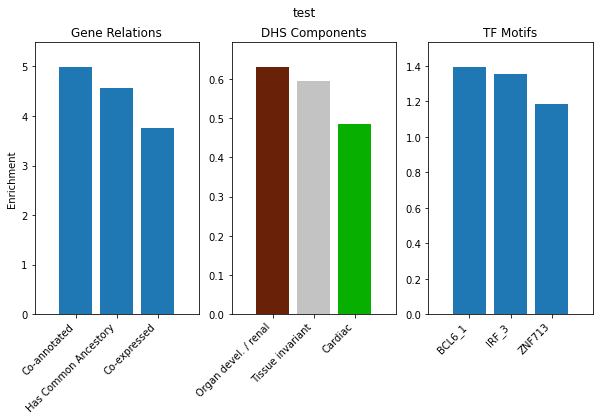

In [ ]:
significant_gene_sets, pvals = set_of_genes_analysis(test, 'test')

In [16]:
f = open('/home/meuleman/projects/MegaMap/WM20220727_extract_MegaMap_target_genes_for_Cameron/table_targets_forCameron_WM20220727.txt', 'r')
exper_plus_genes = []
exper_only = np.array([])
for line in f.readlines():
    line = re.split(',|\t', line.strip())
    exper_plus_genes.append(line)
    exper_only = np.append(exper_only, line[0])

In [252]:
exper_only

array(['ACACA_KRAB_2_Alt-seq-v1', 'ACADSB_KRAB_5_Alt-seq-v1',
       'AK9_KRAB_2_Alt-seq-v0', 'AK9_KRAB_2_mRNA', 'AK9_KRAB_5_mRNA',
       'ALDH18A1_KRAB_2_Alt-seq-v1', 'ALDH18A1_KRAB_2_mRNA',
       'ALDH18A1_KRAB_5_Alt-seq-v1', 'ATR_KRAB_5_mRNA',
       'BATF_KRAB_5_Alt-seq-v1', 'BATF_KRAB_8_Alt-seq-v1',
       'BRCA1_KRAB_2_mRNA', 'BRCA1_KRAB_5_mRNA', 'BRCA2_KRAB_2_mRNA',
       'BRCA2_KRAB_5_mRNA', 'CD6_KRAB_5_Alt-seq-v1',
       'CDK2_VP64_2_Alt-seq-v1', 'CHD4_KRAB_2_Alt-seq-v1',
       'CHD4_KRAB_5_Alt-seq-v1', 'CHMP6_KRAB_5_Alt-seq-v1',
       'CLCN6_KRAB_2_mRNA', 'CLCN6_KRAB_5_Alt-seq-v1',
       'CLPB_KRAB_5_Alt-seq-v1', 'CLPB_KRAB_8_Alt-seq-v1',
       'CMIP_KRAB_2_Alt-seq-v1', 'CSAD_KRAB_2_Alt-seq-v1',
       'CTSL_KRAB_2_Alt-seq-v1', 'DCLRE1B_KRAB_2_Alt-seq-v0',
       'DCLRE1B_KRAB_2_Alt-seq-v1', 'DDOST_KRAB_2_Alt-seq-v1',
       'DEF6_VP64_2_Alt-seq-v2', 'E4F1_KRAB_2_Alt-seq-v1',
       'E4F1_KRAB_8_Alt-seq-v1', 'EVL_KRAB_2_Alt-seq-v1',
       'EXOC4_KRAB_8_Alt-seq-v1', '

/tmp/ipykernel_67412/3642102777.py:77: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_67412/1276679635.py:15: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


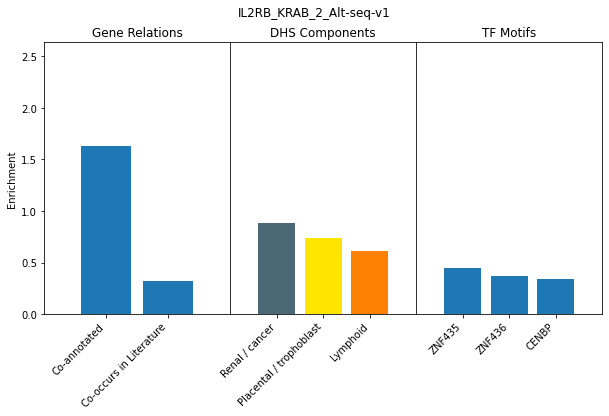

In [273]:
experiment = 'IL2RB_KRAB_2_Alt-seq-v1'
genes = np.array(exper_plus_genes[np.where(exper_only==experiment)[0][0]][1:])
significant_gene_sets_IL2RB, pvals_IL2RB = set_of_genes_analysis(genes, experiment)

In [323]:
f = open('/home/ctrader/region_similarity/data/gene_enrichments_gene_set_results/significant_gene_sets.IL2RB_KRAB_2_Alt-seq-v1_CT20220728.txt', 'w')
for gene_set, pval in zip(significant_gene_sets_IL2RB, pvals_IL2RB):
    f.write(gene_set + '\t' + str(pval) + '\n')
f.close()

/tmp/ipykernel_67412/3642102777.py:77: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_67412/1276679635.py:15: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


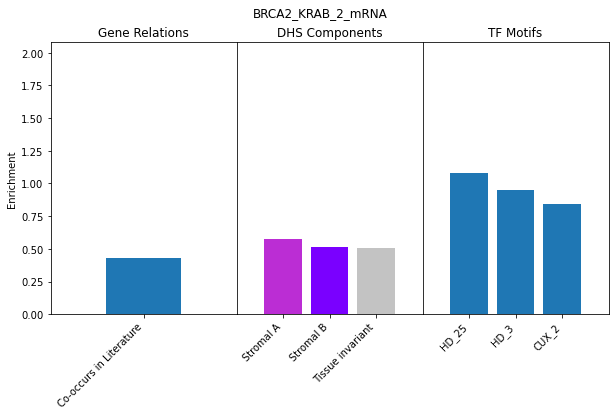

In [275]:
experiment = 'BRCA2_KRAB_2_mRNA'
genes = np.array(exper_plus_genes[np.where(exper_only==experiment)[0][0]][1:])
significant_gene_sets_BRCA2_KRAB_2_mRNA, pvals_BRCA2_KRAB_2_mRNA = set_of_genes_analysis(genes, experiment)

In [322]:
f = open('/home/ctrader/region_similarity/data/gene_enrichments_gene_set_results/significant_gene_sets.BRCA2_KRAB_2_mRNA_CT20220728.txt', 'w')
for gene_set, pval in zip(significant_gene_sets_BRCA2_KRAB_2_mRNA, pvals_BRCA2_KRAB_2_mRNA):
    f.write(gene_set + '\t' + str(pval) + '\n')
f.close()

/tmp/ipykernel_67412/3642102777.py:77: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_67412/1276679635.py:15: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


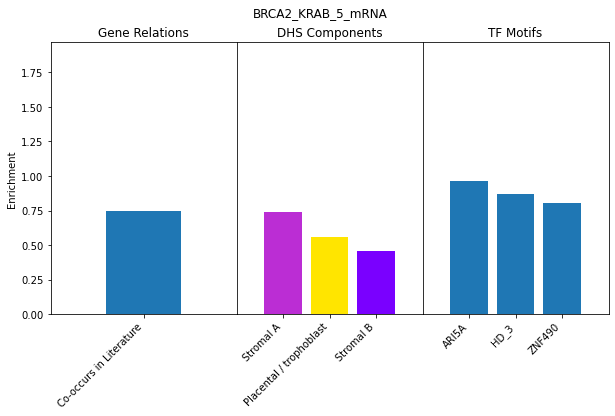

In [276]:
experiment = 'BRCA2_KRAB_5_mRNA'
genes = np.array(exper_plus_genes[np.where(exper_only==experiment)[0][0]][1:])
significant_gene_sets_BRCA2_KRAB_5_mRNA, pvals_BRCA2_KRAB_5_mRNA = set_of_genes_analysis(genes, experiment)

In [321]:
f = open('/home/ctrader/region_similarity/data/gene_enrichments_gene_set_results/significant_gene_sets.BRCA2_KRAB_5_mRNA_CT20220728.txt', 'w')
for gene_set, pval in zip(significant_gene_sets_BRCA2_KRAB_5_mRNA, pvals_BRCA2_KRAB_5_mRNA):
    f.write(gene_set + '\t' + str(pval) + '\n')
f.close()

/tmp/ipykernel_67412/3642102777.py:77: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_67412/1276679635.py:15: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


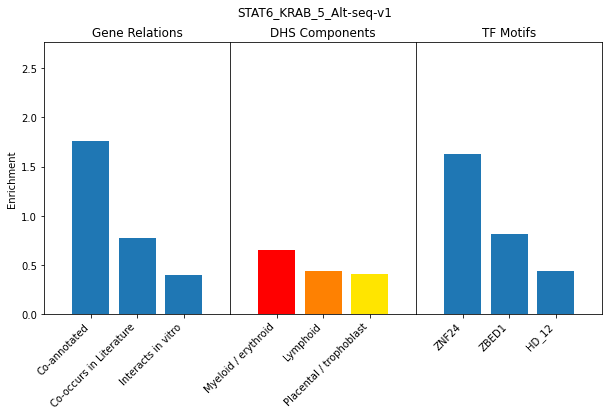

In [277]:
experiment = 'STAT6_KRAB_5_Alt-seq-v1'
genes = np.array(exper_plus_genes[np.where(exper_only==experiment)[0][0]][1:])
significant_gene_sets_STAT6_KRAB_5, pvals_STAT6_KRAB_5 = set_of_genes_analysis(genes, experiment)

In [320]:
f = open('/home/ctrader/region_similarity/data/gene_enrichments_gene_set_results/significant_gene_sets.STAT6_KRAB_5_Alt-seq-v1_CT20220728.txt', 'w')
for gene_set, pval in zip(significant_gene_sets_STAT6_KRAB_5, pvals_STAT6_KRAB_5):
    f.write(gene_set + '\t' + str(pval) + '\n')
f.close()

/tmp/ipykernel_67412/3642102777.py:77: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_67412/1276679635.py:15: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


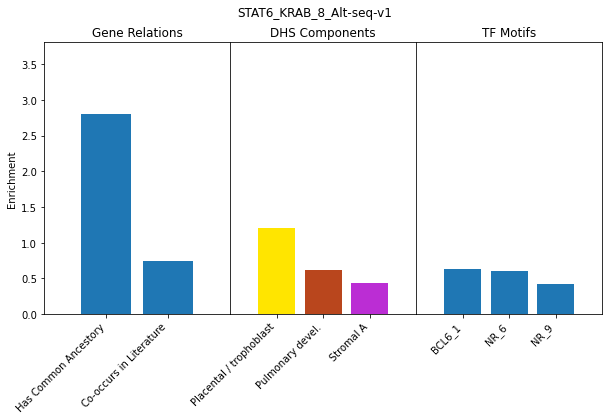

In [278]:
experiment = 'STAT6_KRAB_8_Alt-seq-v1'
genes = np.array(exper_plus_genes[np.where(exper_only==experiment)[0][0]][1:])
significant_gene_sets_STAT6_KRAB_8, pvals_STAT6_KRAB_8 = set_of_genes_analysis(genes, experiment)

In [319]:
f = open('/home/ctrader/region_similarity/data/gene_enrichments_gene_set_results/significant_gene_sets.STAT6_KRAB_8_Alt-seq-v1_CT20220728.txt', 'w')
for gene_set, pval in zip(significant_gene_sets_STAT6_KRAB_8, pvals_STAT6_KRAB_8):
    f.write(gene_set + '\t' + str(pval) + '\n')
f.close()

In [292]:
# experiment = 'STAT6_VP64_2_Alt-seq-v1'
# genes = np.array(exper_plus_genes[np.where(exper_only==experiment)[0][0]][1:])
# significant_gene_sets_STAT6_VP64_2, pvals_STAT6_VP64_2 = set_of_genes_analysis(genes, experiment)

/tmp/ipykernel_67412/250706996.py:79: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_67412/1276679635.py:15: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


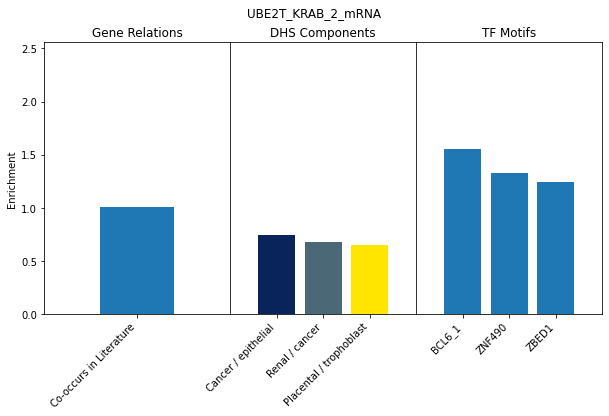

In [293]:
experiment = 'UBE2T_KRAB_2_mRNA'
genes = np.array(exper_plus_genes[np.where(exper_only==experiment)[0][0]][1:])
significant_gene_sets_UBE2T_KRAB_2_mRNA, pvals_UBE2T_KRAB_2_mRNA = set_of_genes_analysis(genes, experiment)

In [318]:
f = open('/home/ctrader/region_similarity/data/gene_enrichments_gene_set_results/significant_gene_sets.UBE2T_KRAB_2_mRNA_CT20220728.txt', 'w')
for gene_set, pval in zip(significant_gene_sets_UBE2T_KRAB_2_mRNA, pvals_UBE2T_KRAB_2_mRNA):
    f.write(gene_set + '\t' + str(pval) + '\n')
f.close()

/tmp/ipykernel_67412/250706996.py:79: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_67412/834248113.py:5: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)
/tmp/ipykernel_67412/834248113.py:12: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_67412/834248113.py:15: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


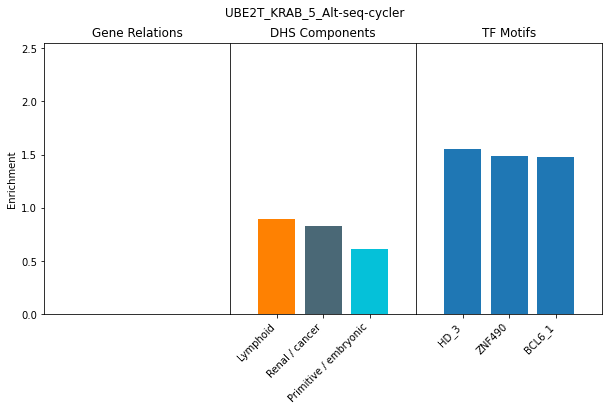

In [312]:
experiment = 'UBE2T_KRAB_5_Alt-seq-cycler'
genes = np.array(exper_plus_genes[np.where(exper_only==experiment)[0][0]][1:])
significant_gene_sets_UBE2T_KRAB_5_Alt_seq_cycler, pvals_UBE2T_KRAB_5_Alt_seq_cycler = set_of_genes_analysis(genes, experiment)

In [317]:
f = open('/home/ctrader/region_similarity/data/gene_enrichments_gene_set_results/significant_gene_sets.UBE2T_KRAB_5_Alt-seq-cycler_CT20220728.txt', 'w')
for gene_set, pval in zip(significant_gene_sets_UBE2T_KRAB_5_Alt_seq_cycler, pvals_UBE2T_KRAB_5_Alt_seq_cycler):
    f.write(gene_set + '\t' + str(pval) + '\n')
f.close()

/tmp/ipykernel_67412/250706996.py:79: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_67412/834248113.py:12: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_67412/834248113.py:15: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


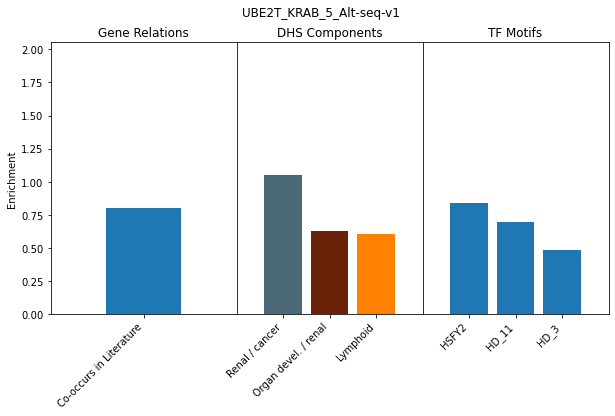

In [313]:
experiment = 'UBE2T_KRAB_5_Alt-seq-v1'
genes = np.array(exper_plus_genes[np.where(exper_only==experiment)[0][0]][1:])
significant_gene_sets_UBE2T_KRAB_5_Alt_seq_v1, pvals_UBE2T_KRAB_5_Alt_seq_v1 = set_of_genes_analysis(genes, experiment)

In [316]:
f = open('/home/ctrader/region_similarity/data/gene_enrichments_gene_set_results/significant_gene_sets.UBE2T_KRAB_5_Alt-seq-v1_CT20220728.txt', 'w')
for gene_set, pval in zip(significant_gene_sets_UBE2T_KRAB_5_Alt_seq_v1, pvals_UBE2T_KRAB_5_Alt_seq_v1):
    f.write(gene_set + '\t' + str(pval) + '\n')
f.close()

ACACA_KRAB_2_Alt-seq-v1


/tmp/ipykernel_68436/4280375358.py:12: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)


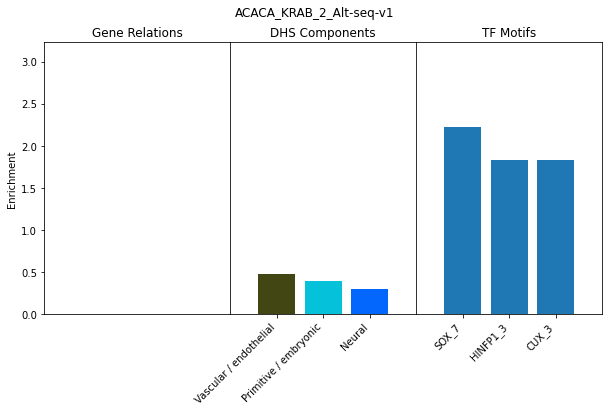

ACADSB_KRAB_5_Alt-seq-v1


/tmp/ipykernel_68436/1528825393.py:79: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_68436/4280375358.py:5: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)
/tmp/ipykernel_68436/4280375358.py:16: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


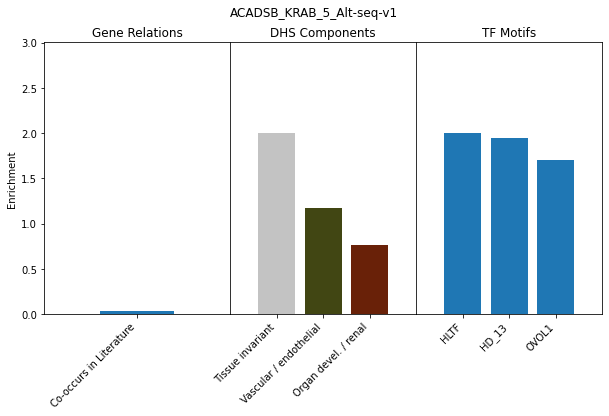

AK9_KRAB_2_Alt-seq-v0


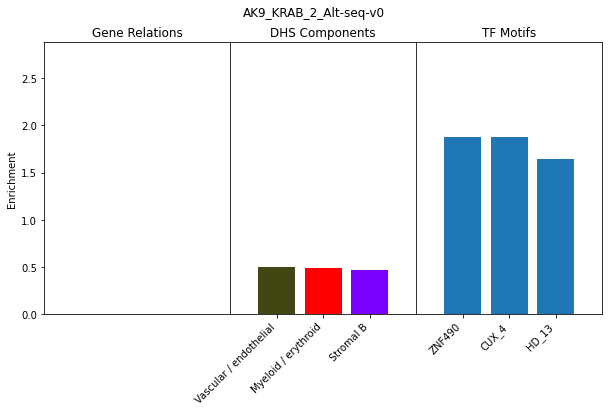

AK9_KRAB_2_mRNA


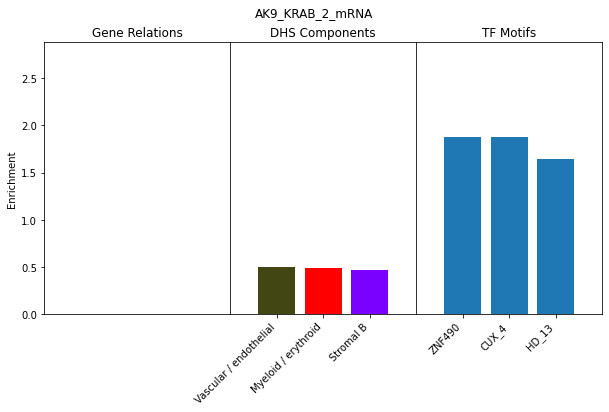

AK9_KRAB_5_mRNA


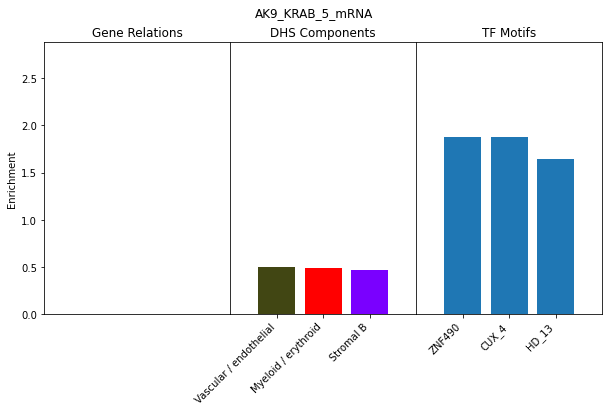

ALDH18A1_KRAB_2_Alt-seq-v1


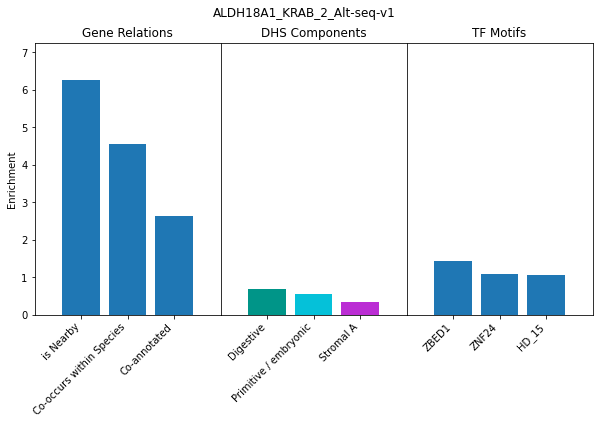

ALDH18A1_KRAB_2_mRNA


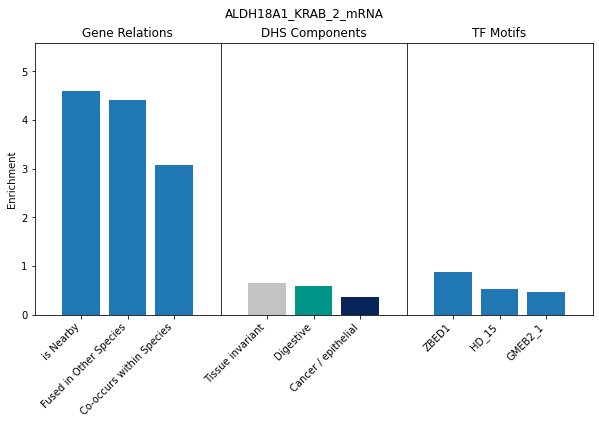

ALDH18A1_KRAB_5_Alt-seq-v1


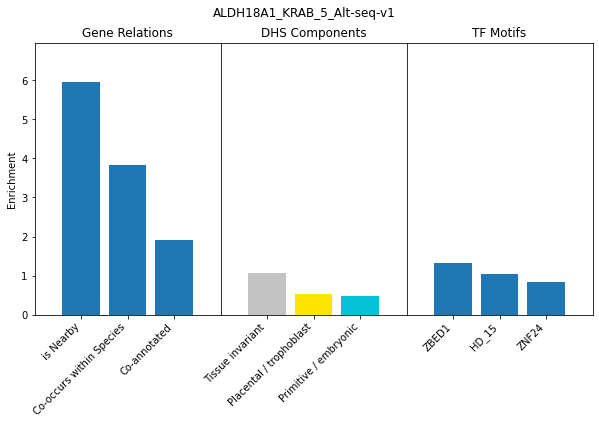

ATR_KRAB_5_mRNA


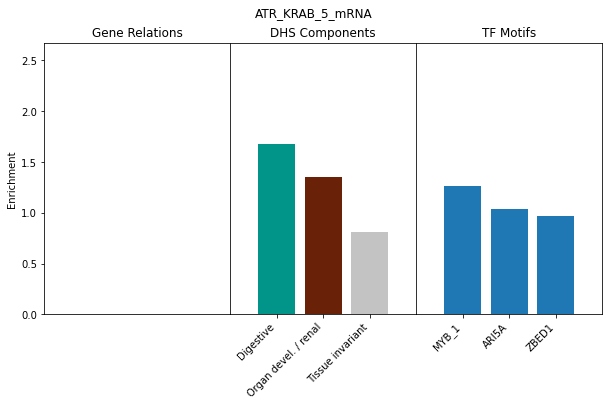

BATF_KRAB_5_Alt-seq-v1


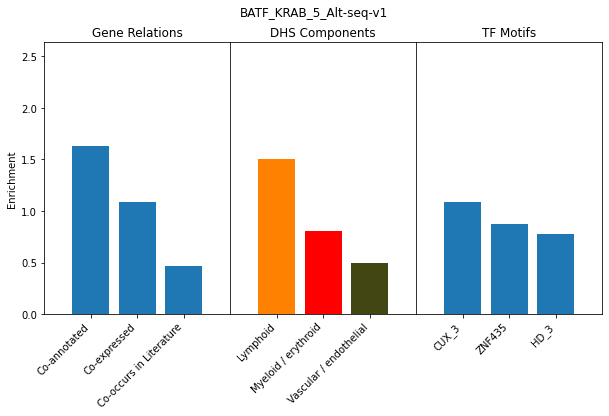

BATF_KRAB_8_Alt-seq-v1


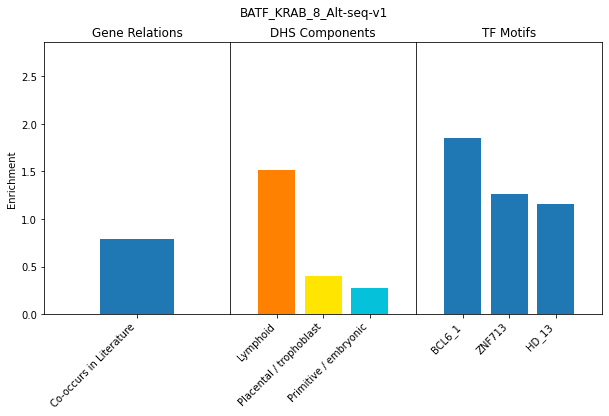

BRCA1_KRAB_2_mRNA


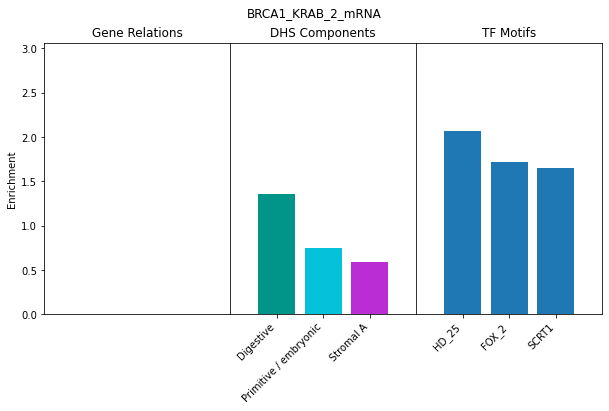

BRCA1_KRAB_5_mRNA


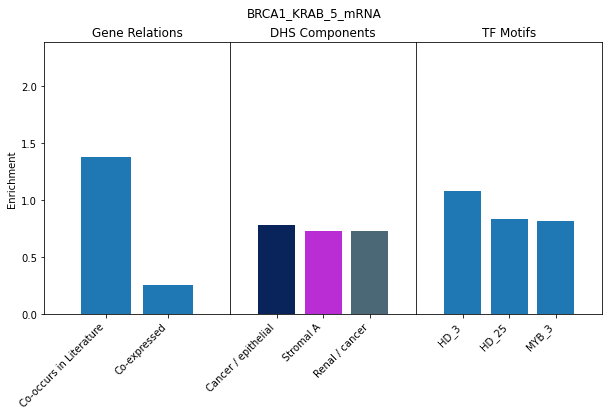

BRCA2_KRAB_2_mRNA


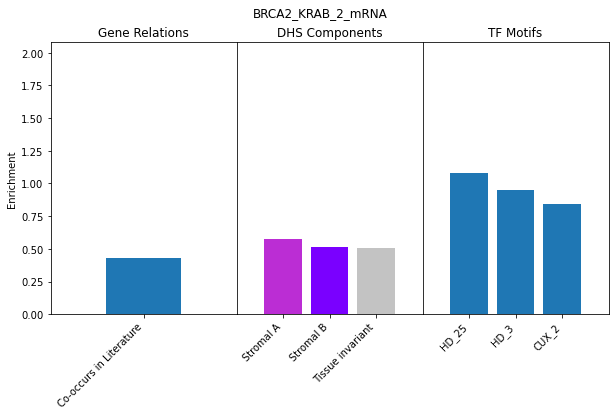

BRCA2_KRAB_5_mRNA


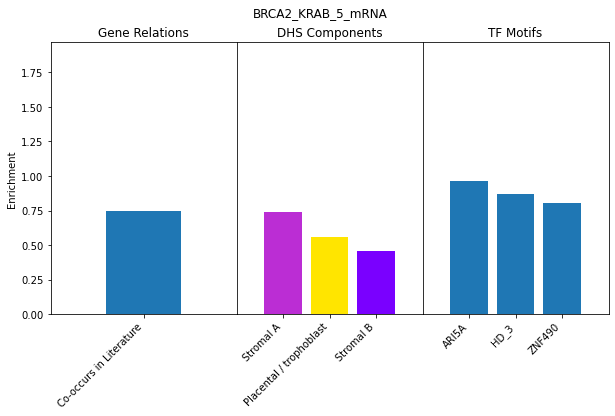

CD6_KRAB_5_Alt-seq-v1


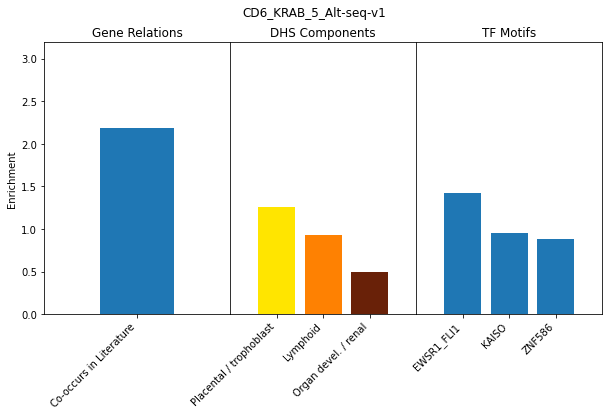

CDK2_VP64_2_Alt-seq-v1


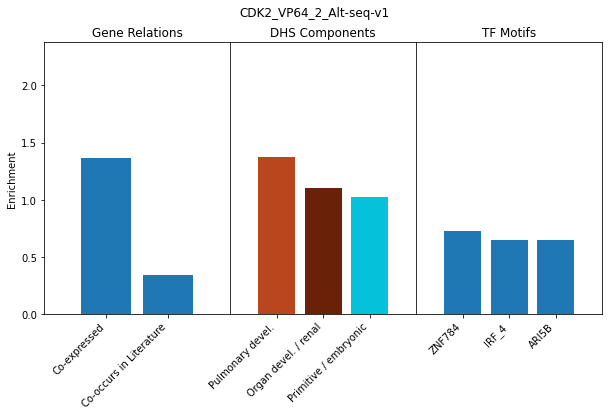

CHD4_KRAB_2_Alt-seq-v1


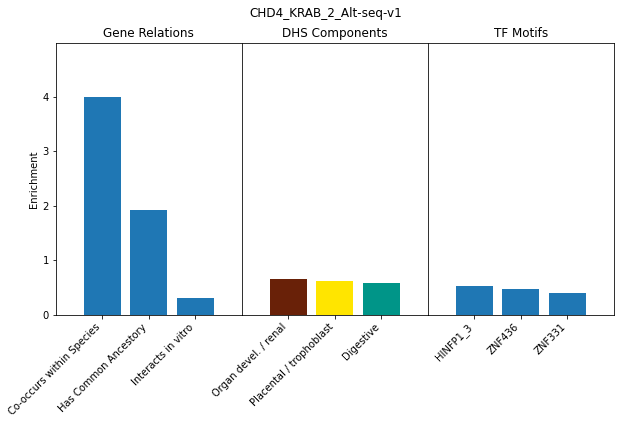

CHD4_KRAB_5_Alt-seq-v1


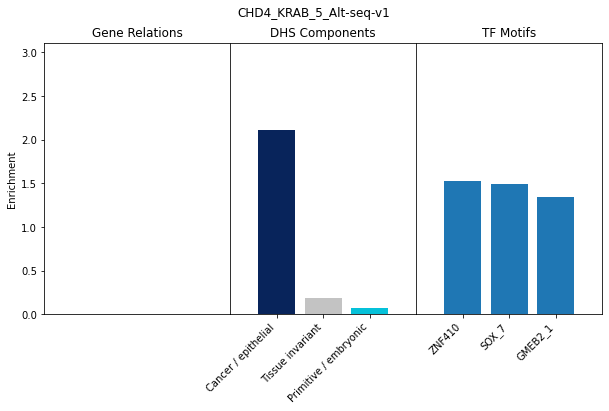

CHMP6_KRAB_5_Alt-seq-v1


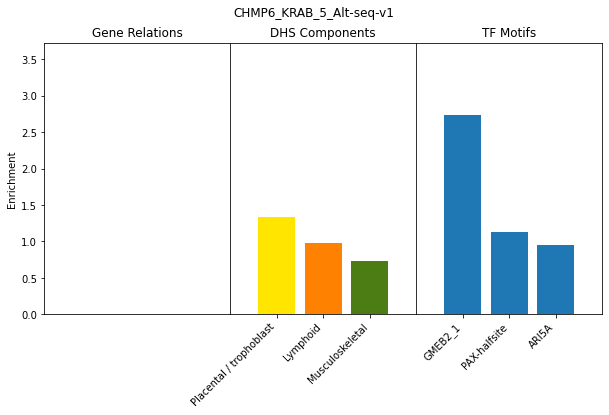

CLCN6_KRAB_2_mRNA


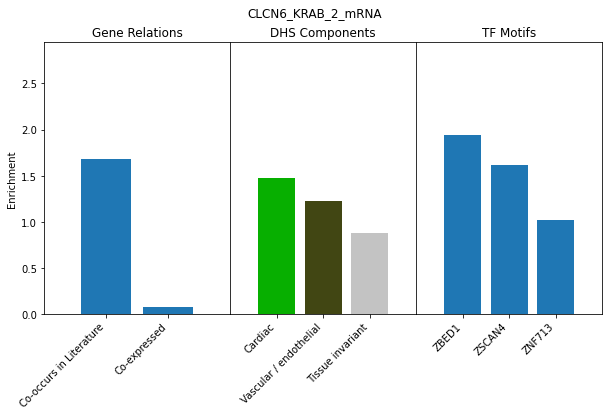

CLCN6_KRAB_5_Alt-seq-v1


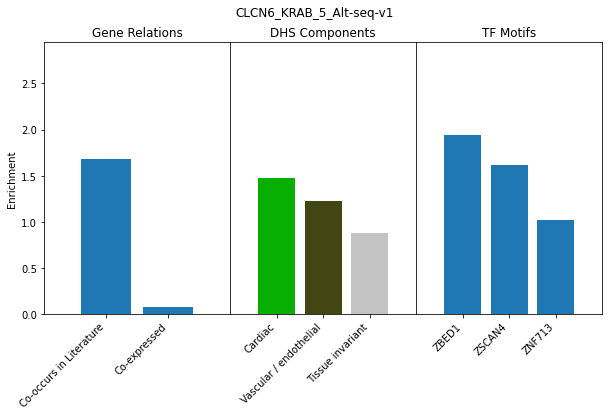

CLPB_KRAB_5_Alt-seq-v1


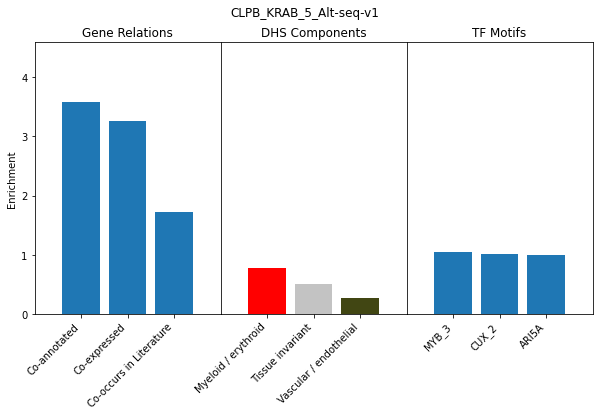

CLPB_KRAB_8_Alt-seq-v1


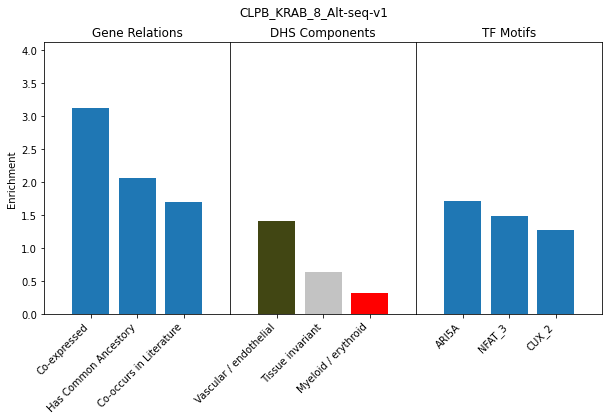

CMIP_KRAB_2_Alt-seq-v1


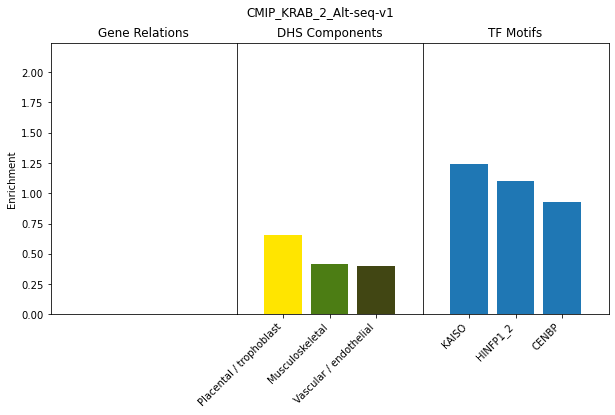

CSAD_KRAB_2_Alt-seq-v1


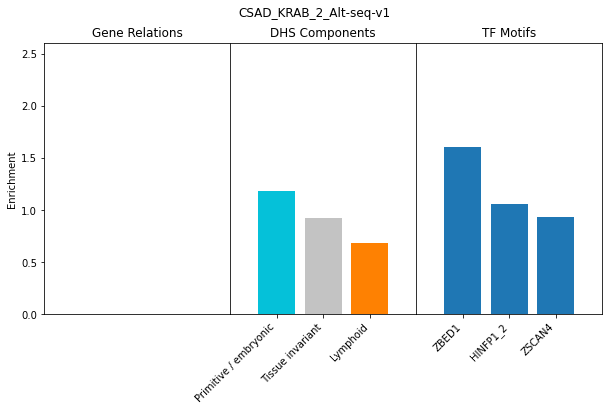

CTSL_KRAB_2_Alt-seq-v1


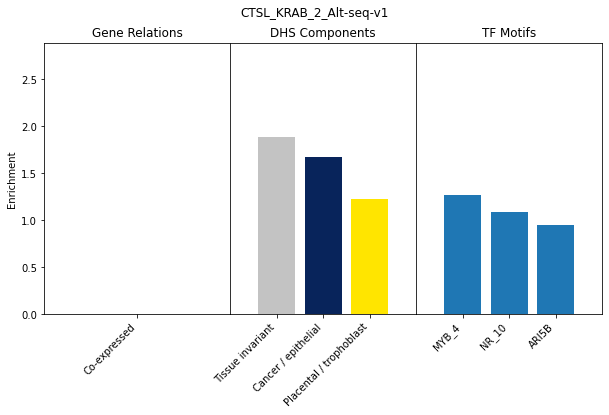

DCLRE1B_KRAB_2_Alt-seq-v0


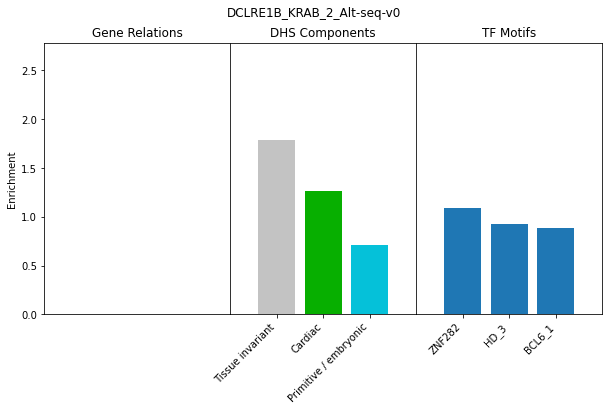

DCLRE1B_KRAB_2_Alt-seq-v1


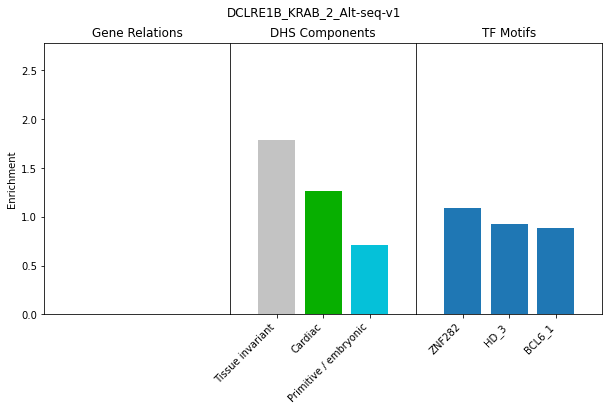

DDOST_KRAB_2_Alt-seq-v1


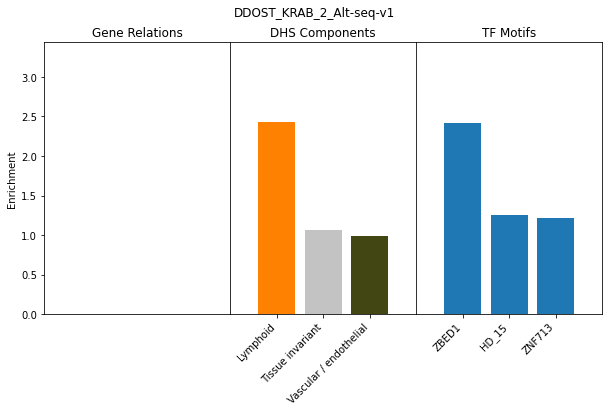

DEF6_VP64_2_Alt-seq-v2


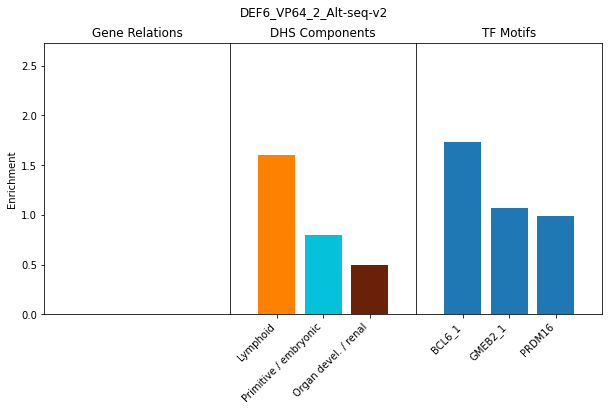

E4F1_KRAB_2_Alt-seq-v1


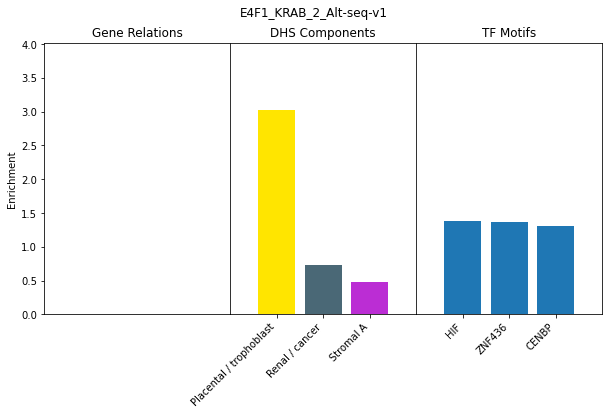

E4F1_KRAB_8_Alt-seq-v1


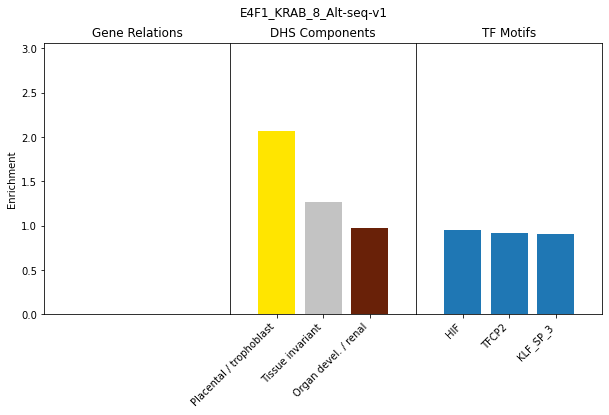

EVL_KRAB_2_Alt-seq-v1


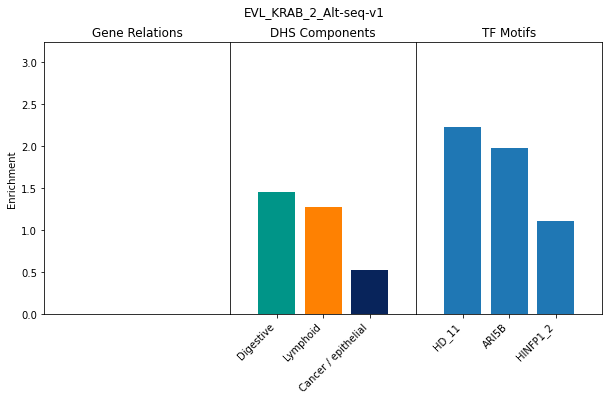

EXOC4_KRAB_8_Alt-seq-v1


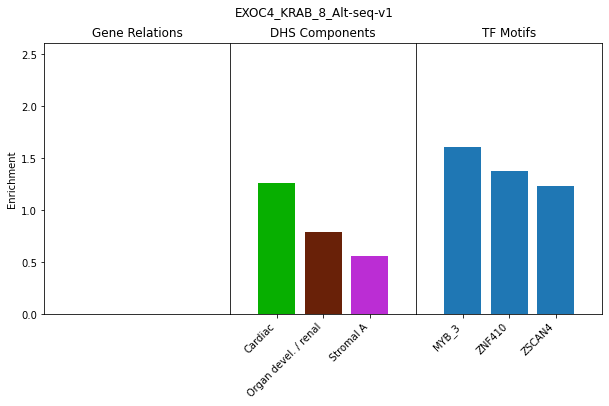

FAS_KRAB_2_Alt-seq-v0


ValueError: Empty data passed with indices specified.

In [38]:
for row in exper_plus_genes:
    experiment = row[0]
    print(experiment)
    genes = np.array(row[1:])
    significant_gene_sets, pvals, set_string_mean = set_of_genes_analysis(genes, experiment)
    f = open('/home/ctrader/region_similarity/data/gene_enrichments_gene_set_results/significant_gene_sets.'+experiment+'_CT20220729.txt', 'w')
    for gene_set, pval in zip(significant_gene_sets, pvals):
        f.write(gene_set + '\t' + str(pval) + '\n')
    f.close()

FAS_KRAB_2_Alt-seq-v0


/tmp/ipykernel_68436/4280375358.py:5: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)
/tmp/ipykernel_68436/4280375358.py:12: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)


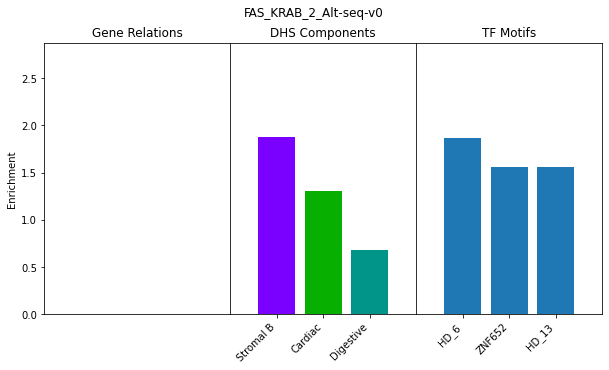

FAS_KRAB_2_mRNA


/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/numpy/core/fromnumeric.py:3440: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/numpy/core/_methods.py:181: RuntimeWarning: invalid value encountered in true_divide
  ret = um.true_divide(


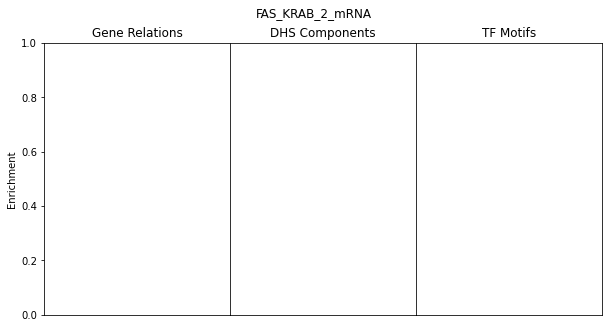

FAS_KRAB_5_mRNA


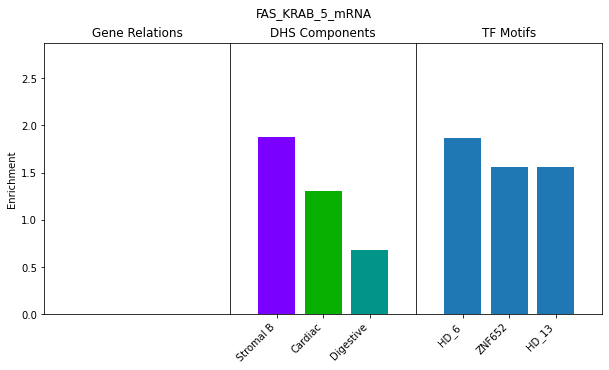

FERMT3_KRAB_5_Alt-seq-v1


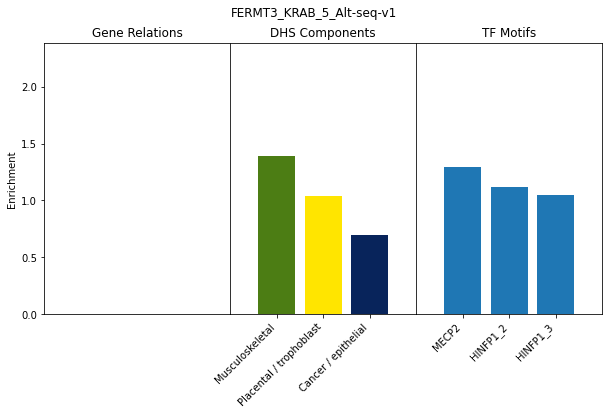

GBP4_KRAB_2_Alt-seq-v1


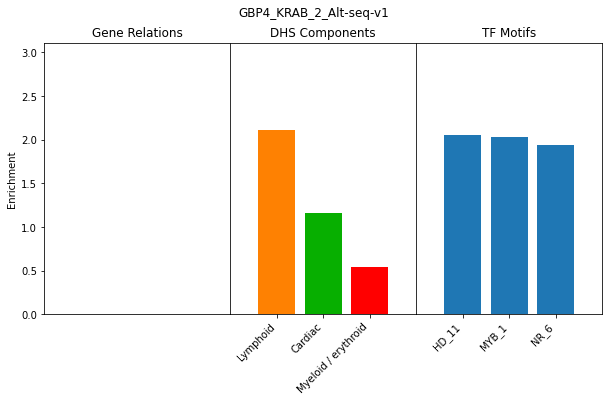

GBP4_KRAB_5_Alt-seq-v1


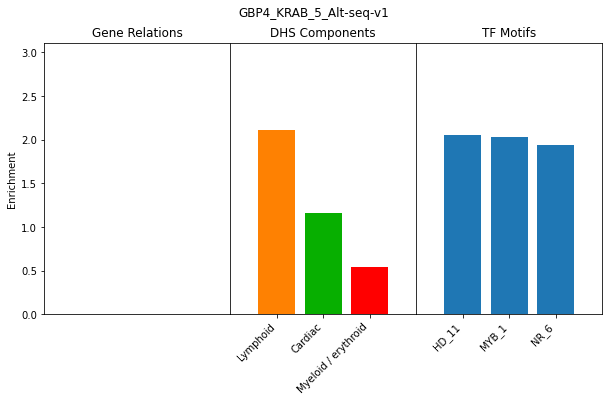

GBP4_KRAB_8_Alt-seq-v1


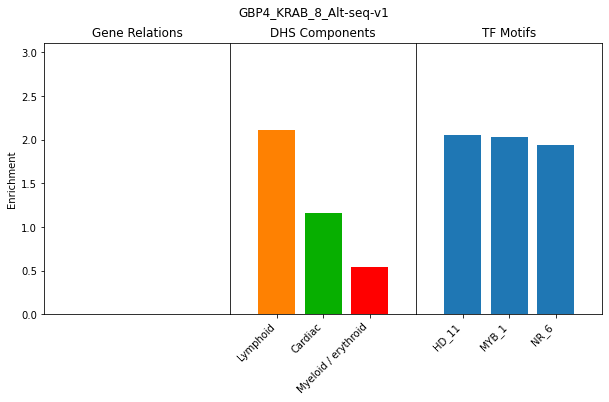

GFM1_KRAB_2_Alt-seq-v1


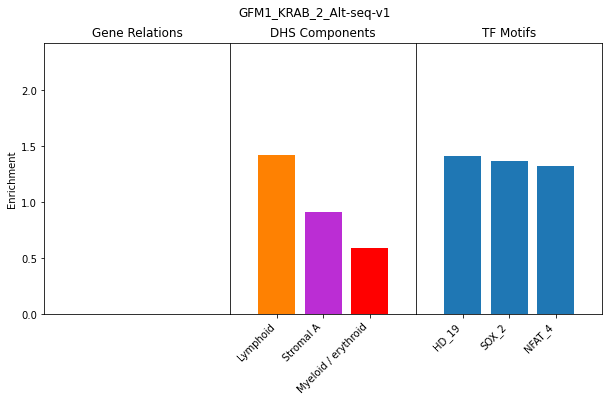

GPR65_KRAB_5_Alt-seq-v1


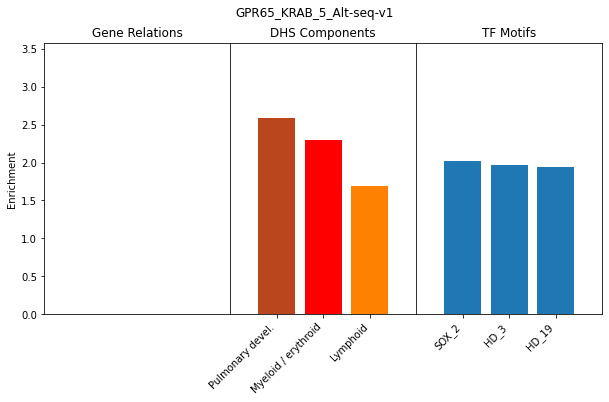

GSTM2_KRAB_2_Alt-seq-v1


/tmp/ipykernel_68436/2814902920.py:79: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_68436/4280375358.py:16: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


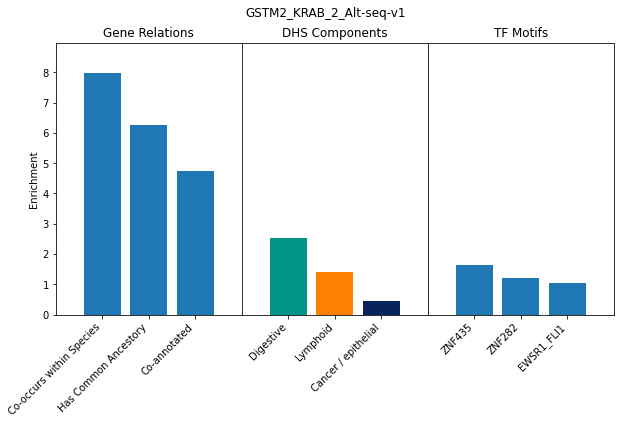

GSTM2_KRAB_5_Alt-seq-v1


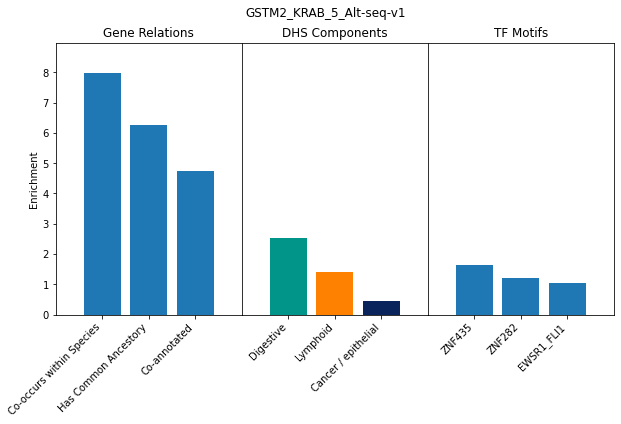

GTF2B_VP64_2_Alt-seq-v1


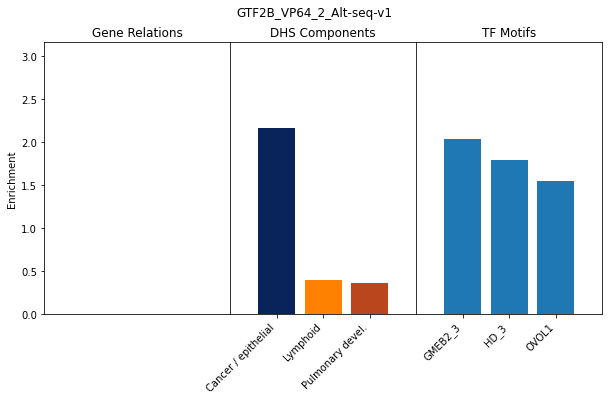

HDAC1_KRAB_2_Alt-seq-v1


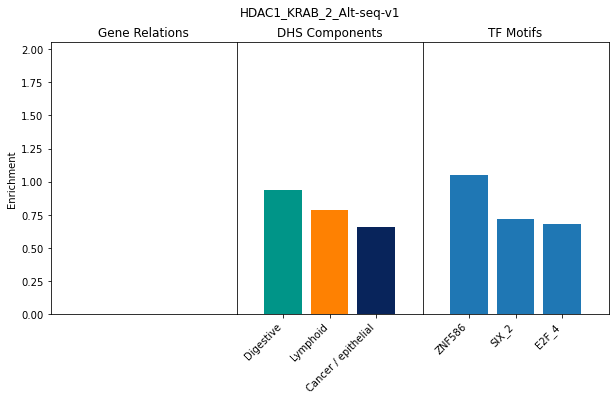

HDAC1_KRAB_5_Alt-seq-v1


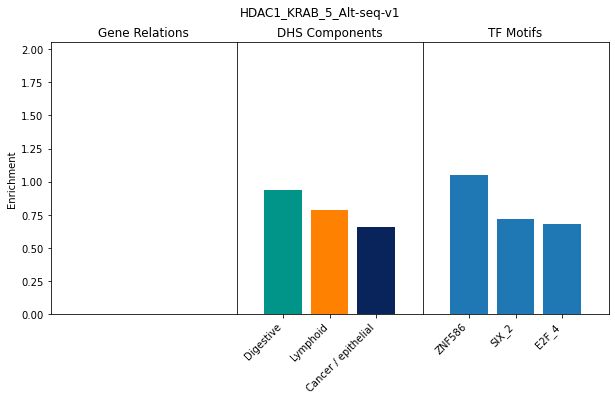

HIF1AN_KRAB_2_Alt-seq-v1


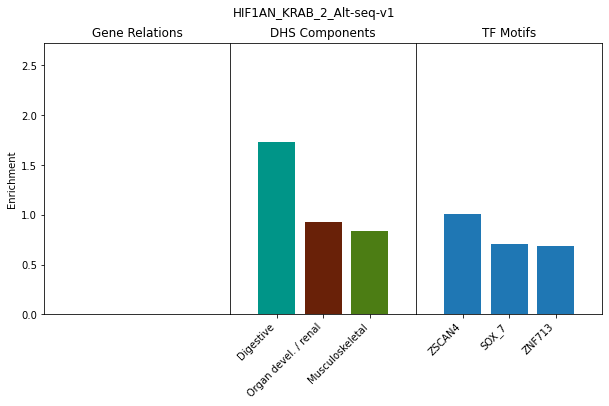

HLA-DQB1_KRAB_2_Alt-seq-v1


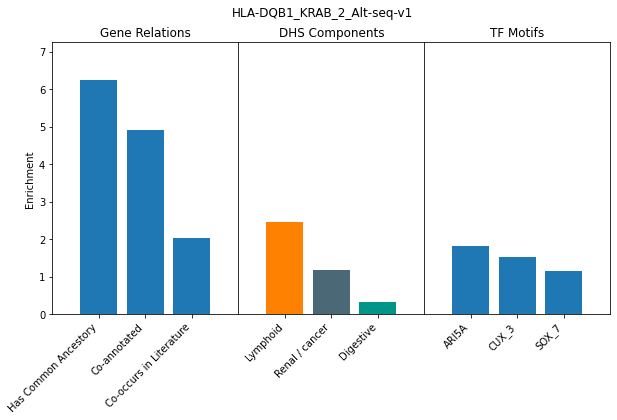

IL2RA_KRAB_5_Alt-seq-v1


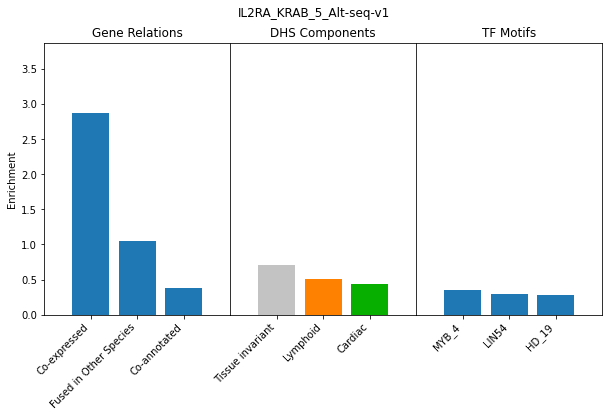

IL2RB_KRAB_2_Alt-seq-v1


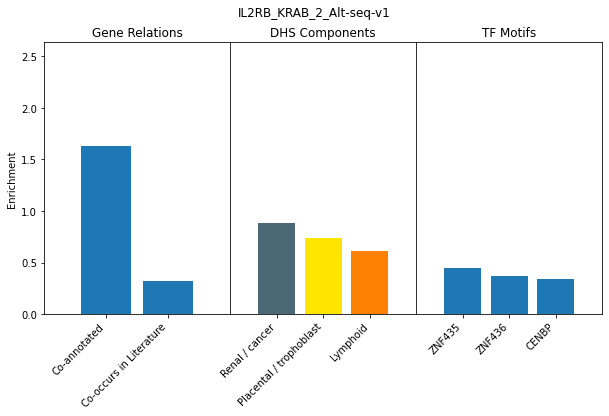

ITGB7_VP64_2_Alt-seq-v1


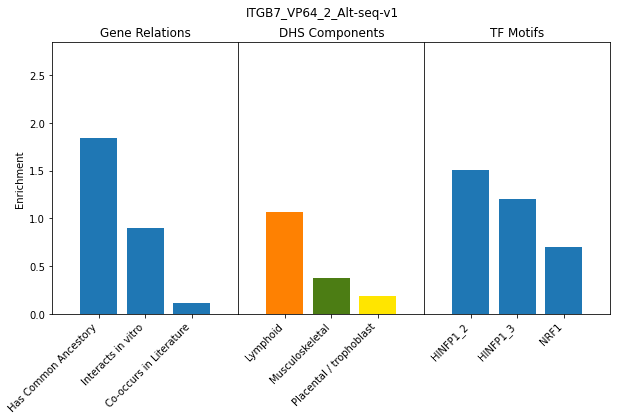

KRAS_VP64_8_Alt-seq-v1


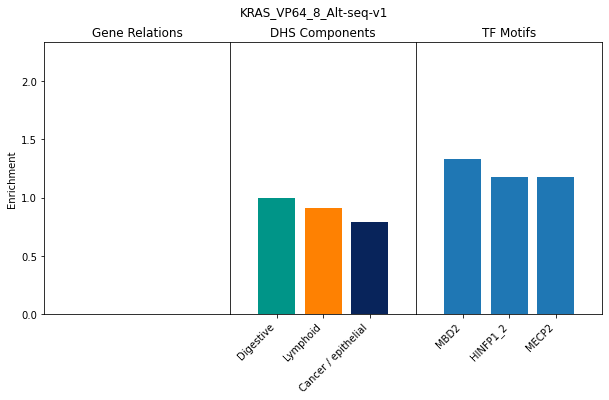

LHX4_VP64_5_Alt-seq-v1


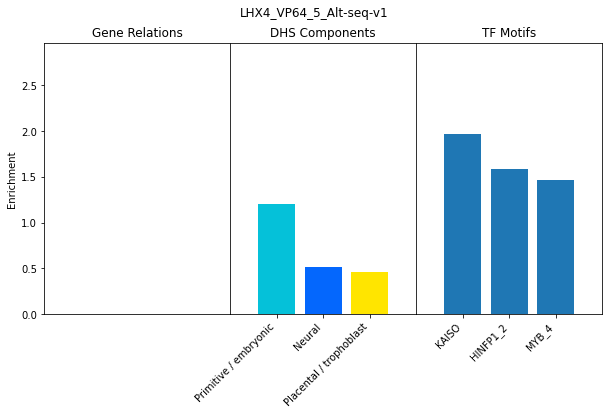

LMTK2_VP64_2_Alt-seq-v1


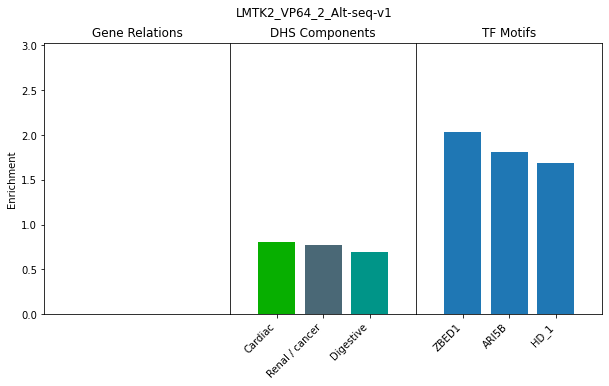

MAPK3_KRAB_2_Alt-seq-v1


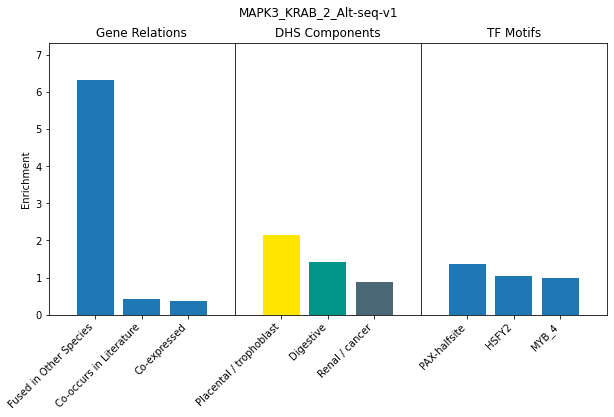

MAPK3_KRAB_2_mRNA


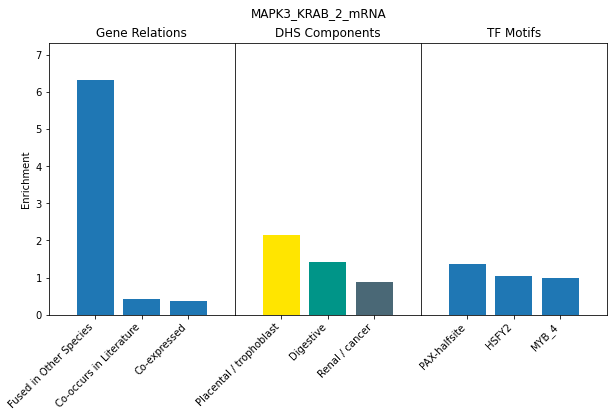

MAPK3_KRAB_5_Alt-seq-v1


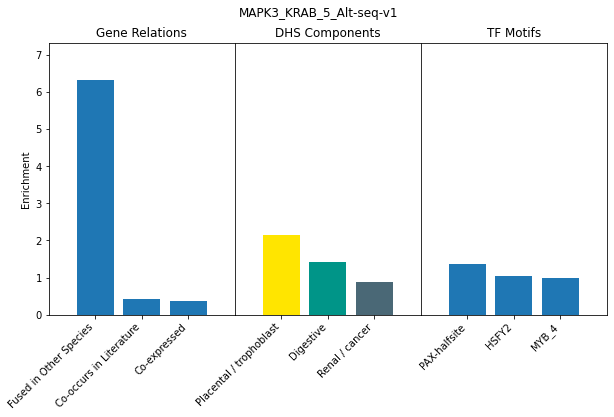

PTPN22_VP64_2_Alt-seq-v1


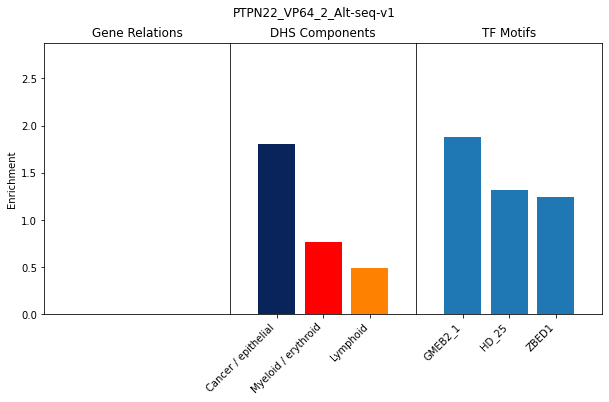

RCL1_VP64_2_Alt-seq-v1


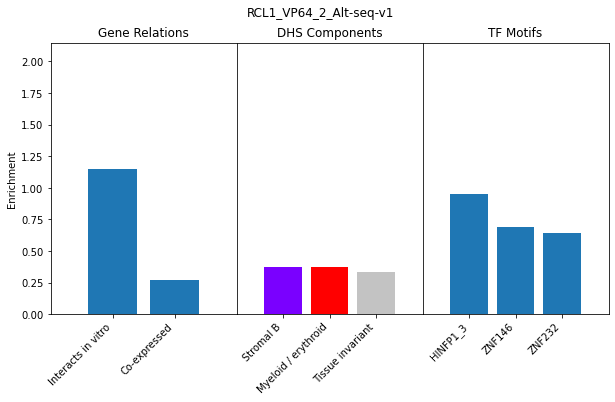

RORC_KRAB_5_Alt-seq-v1


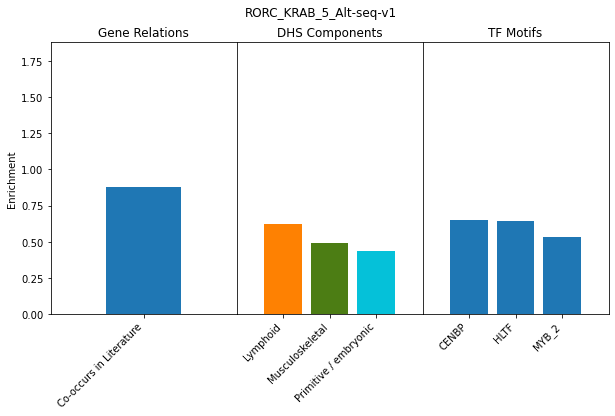

SETDB1_KRAB_2_Alt-seq-v1


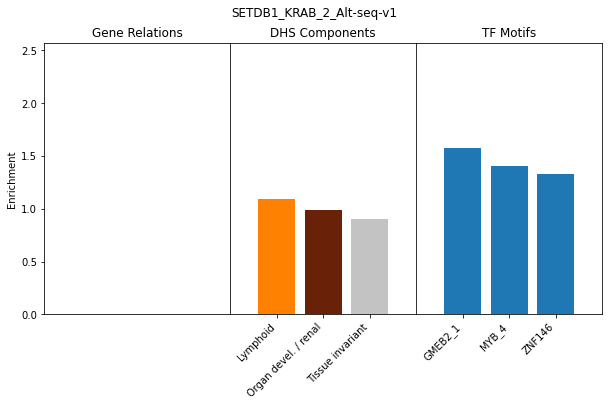

SHOC2_KRAB_2_mRNA


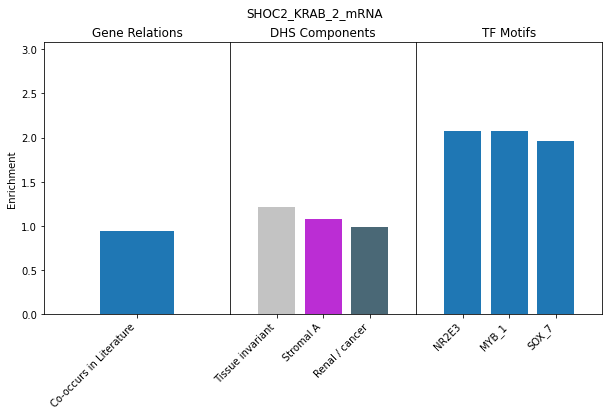

SLC39A14_VP64_2_Alt-seq-v1


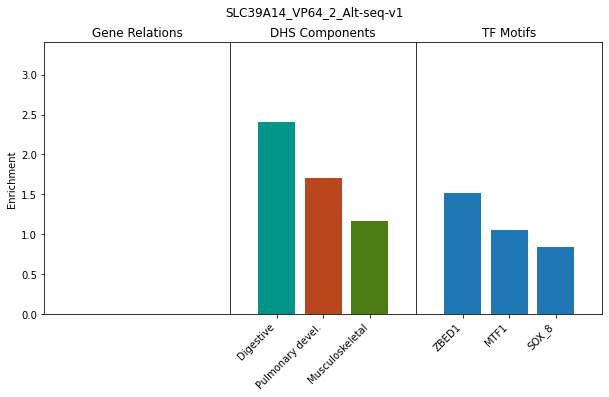

SLC9A9_KRAB_2_Alt-seq-v1


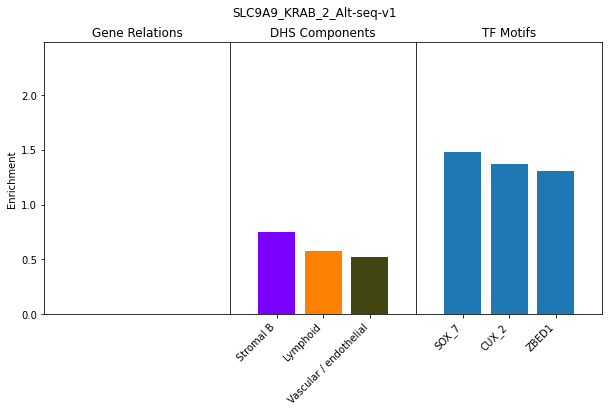

SPINT2_VP64_2_Alt-seq-v1


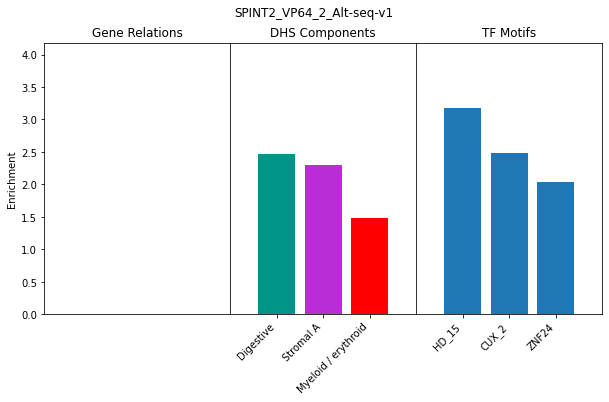

SREBF1_VP64_5_Alt-seq-v1


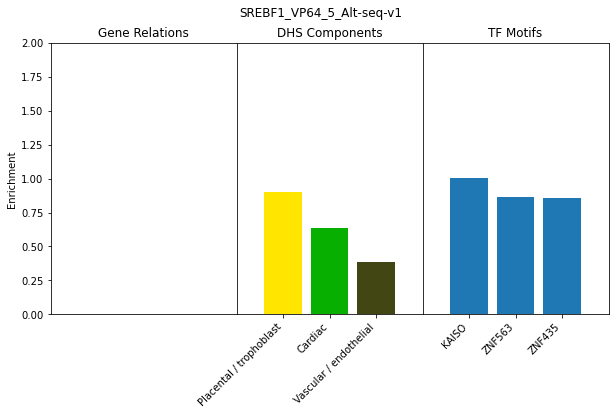

STAT6_KRAB_5_Alt-seq-v1


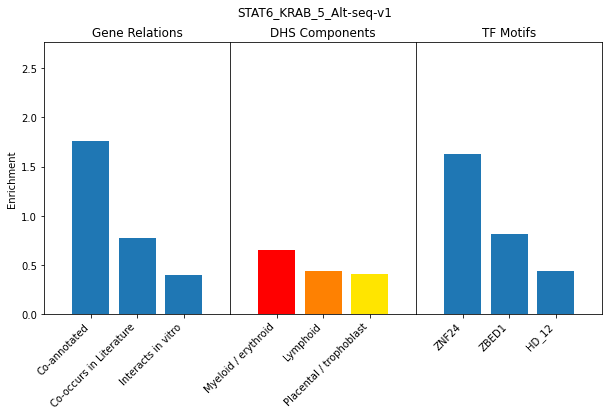

STAT6_KRAB_8_Alt-seq-v1


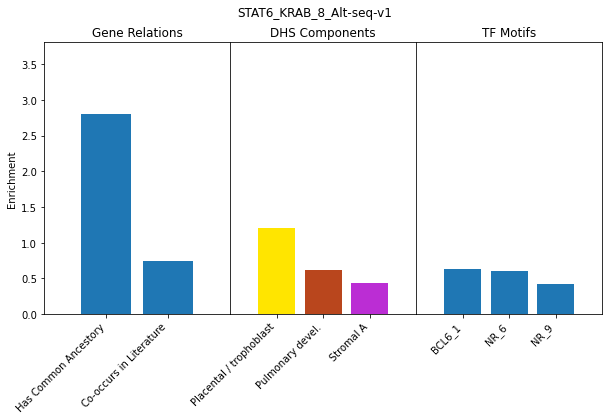

STAT6_VP64_2_Alt-seq-v1


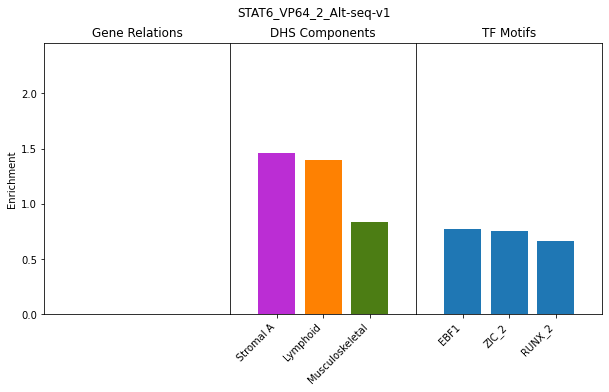

SYVN1_KRAB_5_Alt-seq-v1


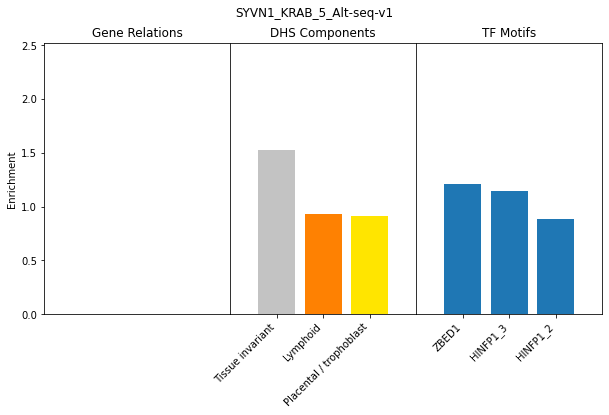

TOP2A_KRAB_2_Alt-seq-v1


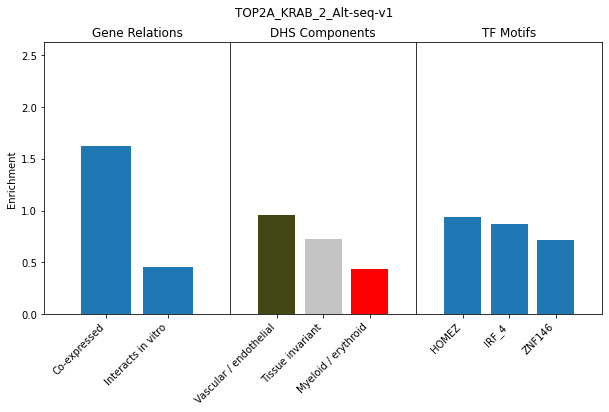

TP53_KRAB_2_mRNA


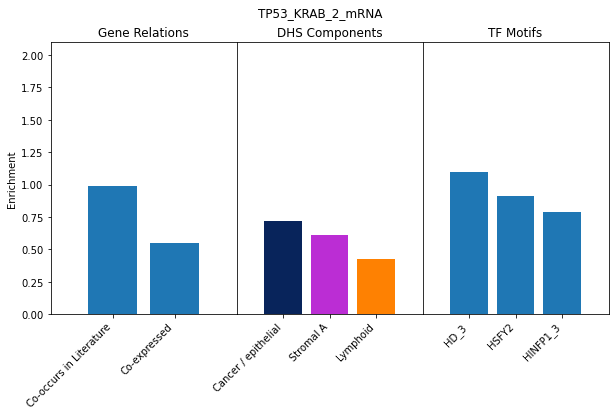

TXNIP_KRAB_2_mRNA


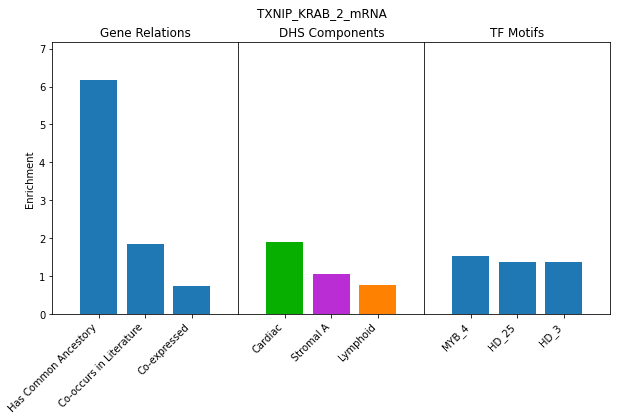

TXNIP_KRAB_5_Alt-seq-v1


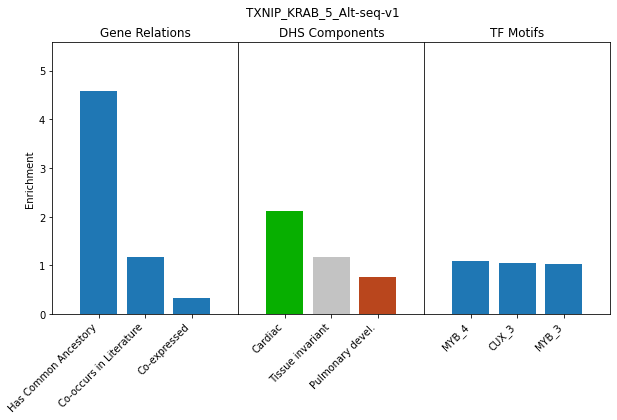

TXNIP_KRAB_5_Alt-seq-v2


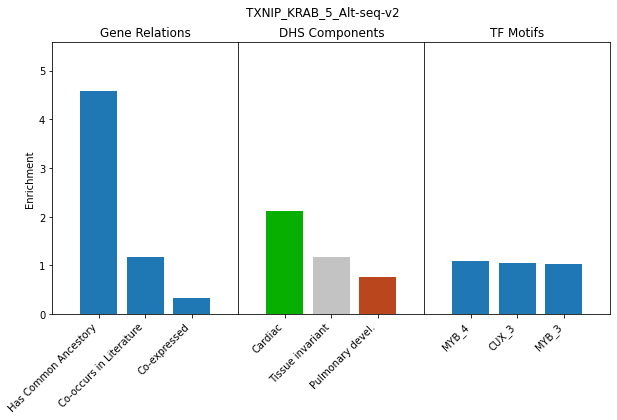

TXNIP_KRAB_5_mRNA


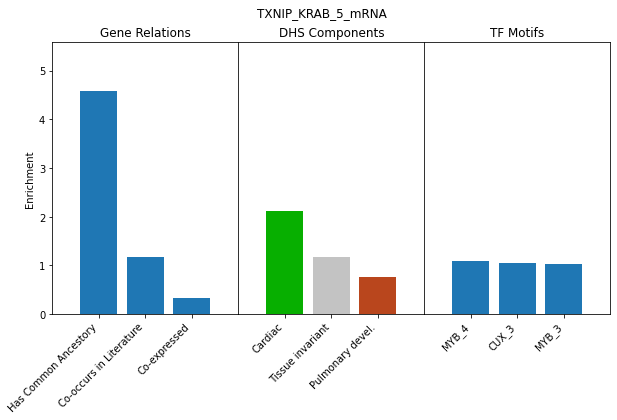

UAP1_KRAB_2_mRNA


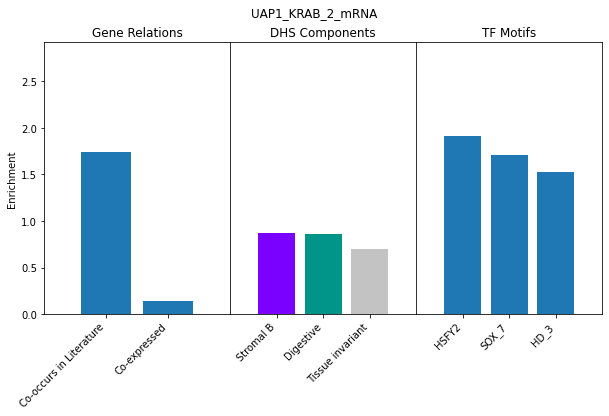

UBE2E2_KRAB_2_mRNA


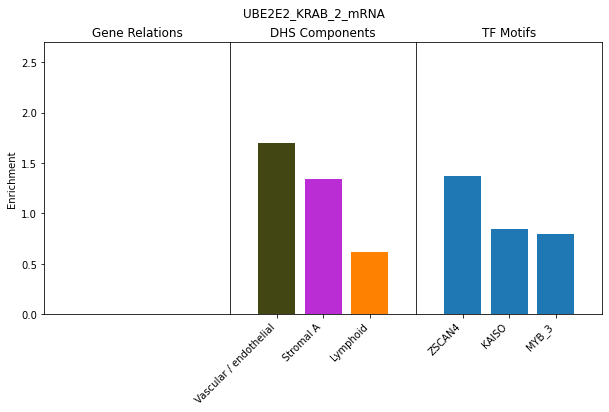

UBE2T_KRAB_2_mRNA


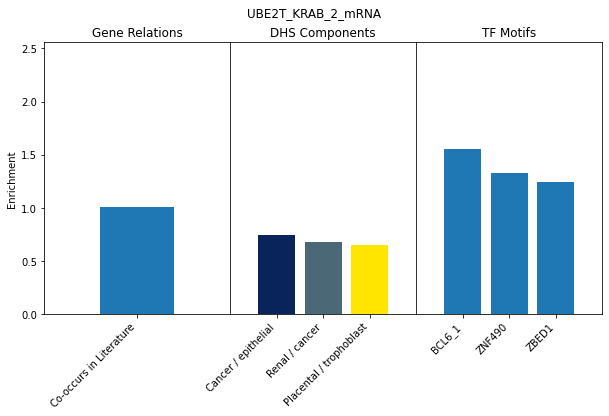

UBE2T_KRAB_5_Alt-seq-cycler


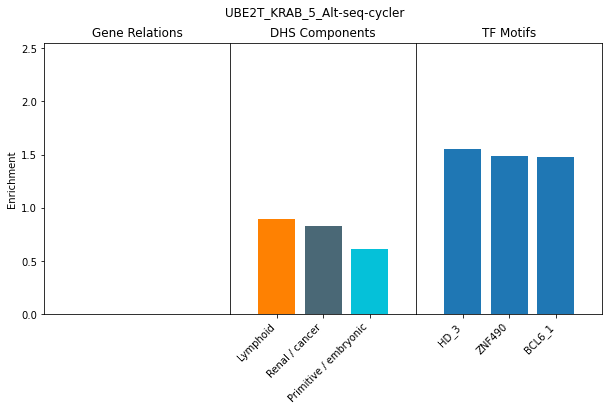

UBE2T_KRAB_5_Alt-seq-v1


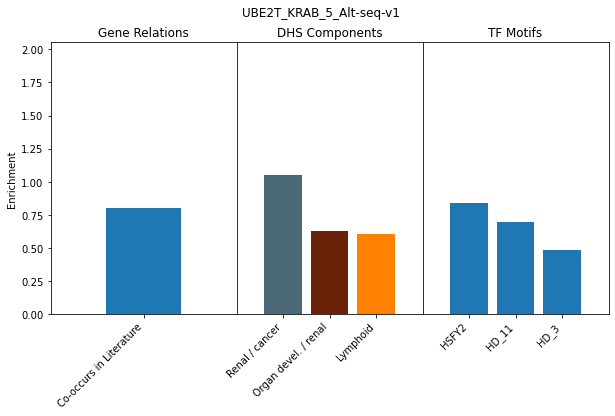

UHMK1_KRAB_2_Alt-seq-v1


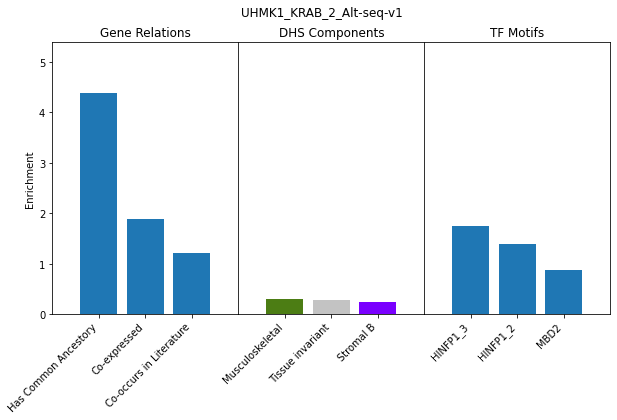

UHMK1_KRAB_5_Alt-seq-v1


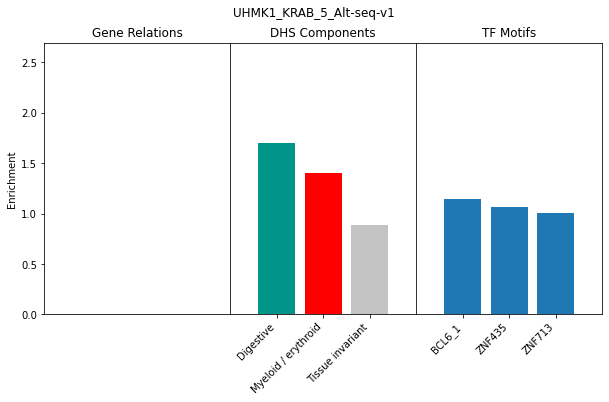

UHMK1_VP64_2_Alt-seq-v1


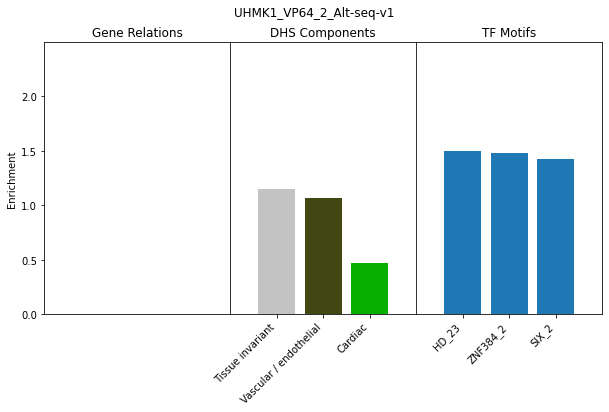

WEE1_KRAB_2_mRNA


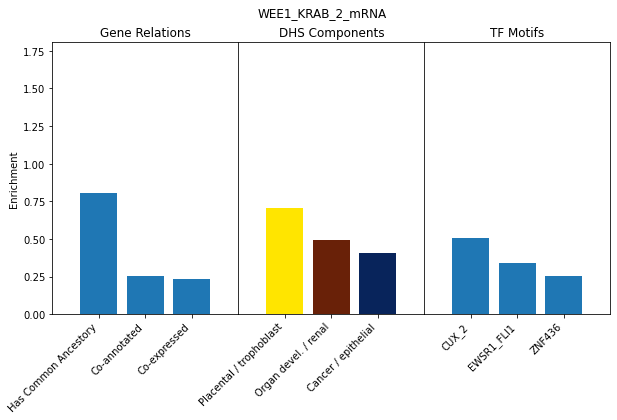

WEE1_KRAB_2_totalRNA


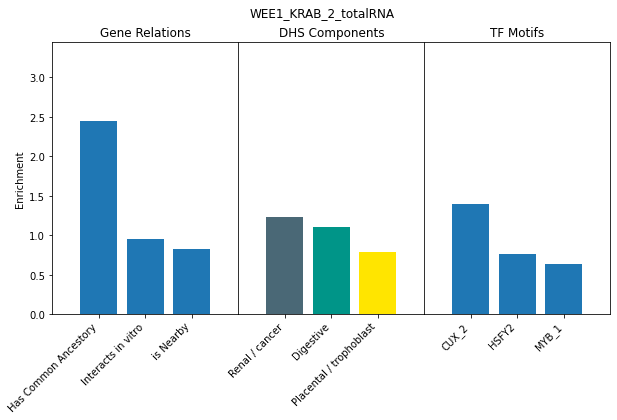

ZBTB39_VP64_2_Alt-seq-v1


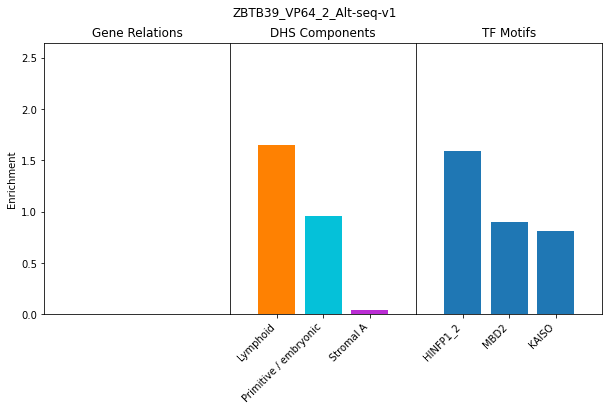

ZMPSTE24_KRAB_2_mRNA


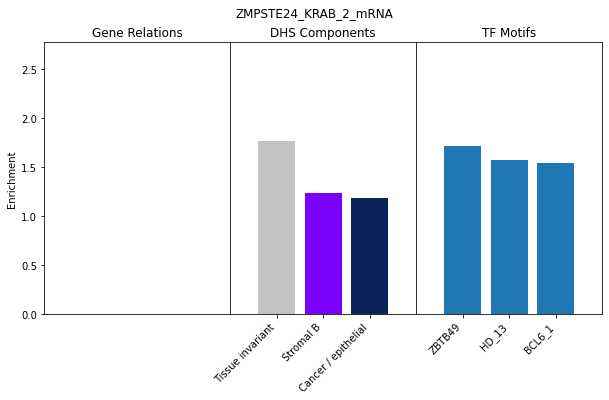

ZMPSTE24_KRAB_5_Alt-seq-v1


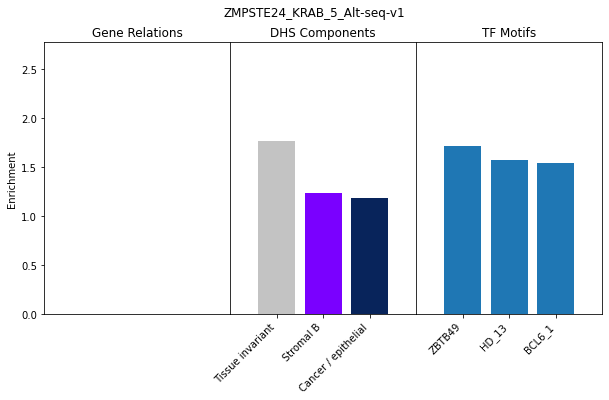

ZNF160_KRAB_8_Alt-seq-v1


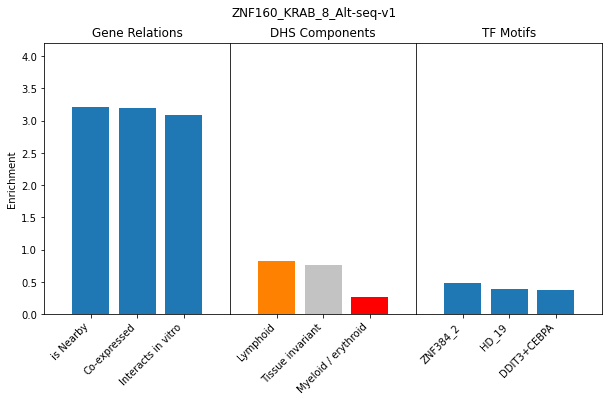

ZNF574_KRAB_2_Alt-seq-v1


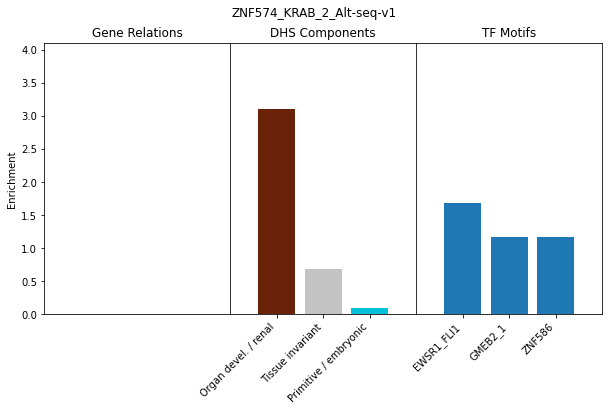

In [53]:
for row in exper_plus_genes[35:]:
    experiment = row[0]
    print(experiment)
    genes = np.array(row[1:])
    significant_gene_sets, pvals, set_string_mean = set_of_genes_analysis(genes, experiment)
    f = open('/home/ctrader/region_similarity/data/gene_enrichments_gene_set_results/significant_gene_sets.'+experiment+'_CT20220729.txt', 'w')
    for gene_set, pval in zip(significant_gene_sets, pvals):
        f.write(gene_set + '\t' + str(pval) + '\n')
    f.close()

In [16]:
exper_plus_genes

[['ACACA_KRAB_2_Alt-seq-v1', 'ACACA', 'THRB-AS1'],
 ['ACADSB_KRAB_5_Alt-seq-v1', 'IKZF5', 'ACADSB'],
 ['AK9_KRAB_2_Alt-seq-v0', 'AK9', 'FIG4'],
 ['AK9_KRAB_2_mRNA', 'AK9', 'FIG4'],
 ['AK9_KRAB_5_mRNA', 'AK9', 'FIG4'],
 ['ALDH18A1_KRAB_2_Alt-seq-v1',
  'PHGDH',
  'PSAT1',
  'ASS1',
  'ALDH18A1',
  'CHAC1',
  'EGFL6'],
 ['ALDH18A1_KRAB_2_mRNA',
  'SLC6A9',
  'CTH',
  'PHGDH',
  'S100P',
  'ANXA3',
  'SLC7A11',
  'STC2',
  'RPS6KA2',
  'PSAT1',
  'ASS1',
  'DNAJC12',
  'ALDH18A1',
  'CHAC1',
  'TM6SF1',
  'GPT2',
  'FFAR3',
  'CBS',
  'ADM2',
  'EGFL6'],
 ['ALDH18A1_KRAB_5_Alt-seq-v1',
  'PHGDH',
  'BATF3',
  'PSAT1',
  'ASS1',
  'ALDH18A1',
  'CHAC1',
  'TM6SF1',
  'CBSL',
  'CBS',
  'EGFL6'],
 ['ATR_KRAB_5_mRNA', 'ATR', 'DHRS2'],
 ['BATF_KRAB_5_Alt-seq-v1',
  'RGS1',
  'LINC01943',
  'AC017002.3',
  'CCR3',
  'CD86',
  'HES1',
  'S100P',
  'MYB',
  'TRIB1',
  'ENTPD1',
  'BATF',
  'C15orf48',
  'CCL3',
  'IL3RA'],
 ['BATF_KRAB_8_Alt-seq-v1', 'BATF', 'IL5', 'ENTPD1'],
 ['BRCA1_KRAB_2_mRN

In [ ]:
print()

ACACA_KRAB_2_Alt-seq-v1


/tmp/ipykernel_104026/1682783786.py:12: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_104026/1682783786.py:66: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


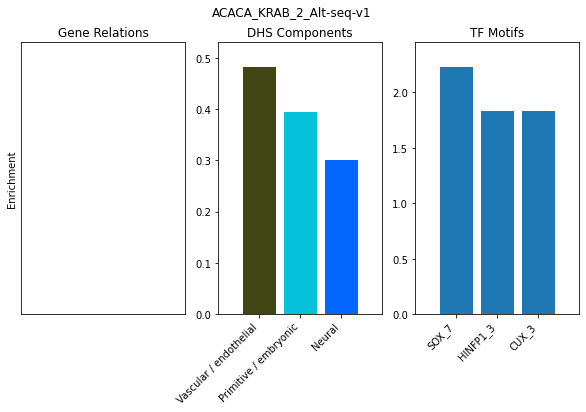

ACADSB_KRAB_5_Alt-seq-v1


/tmp/ipykernel_104026/3012217923.py:79: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_104026/1682783786.py:5: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)
/tmp/ipykernel_104026/1682783786.py:16: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


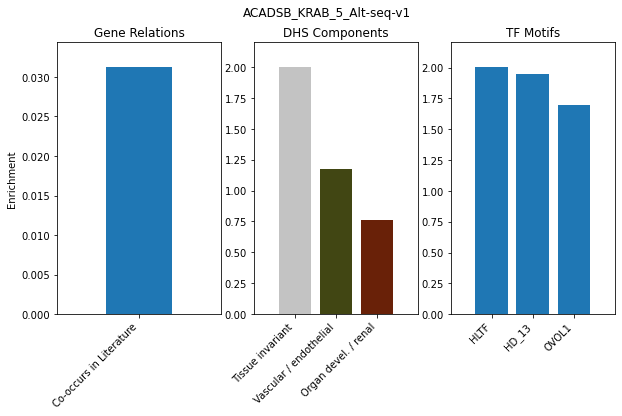

AK9_KRAB_2_Alt-seq-v0


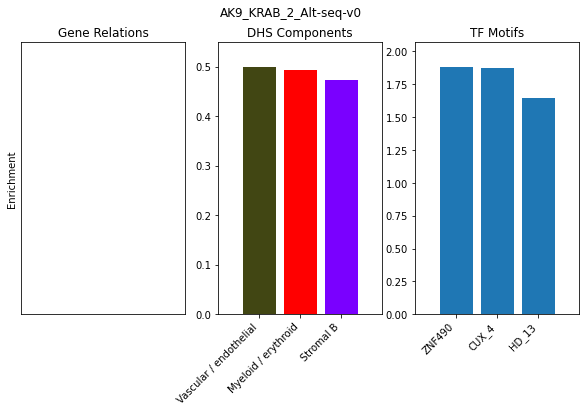

AK9_KRAB_2_mRNA


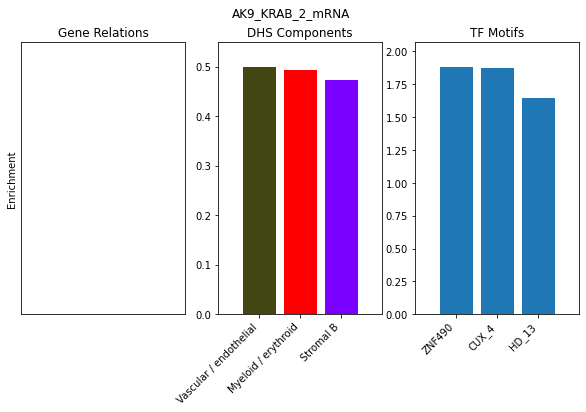

AK9_KRAB_5_mRNA


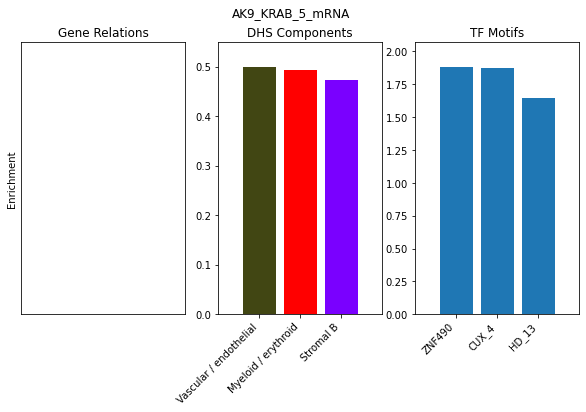

ALDH18A1_KRAB_2_Alt-seq-v1


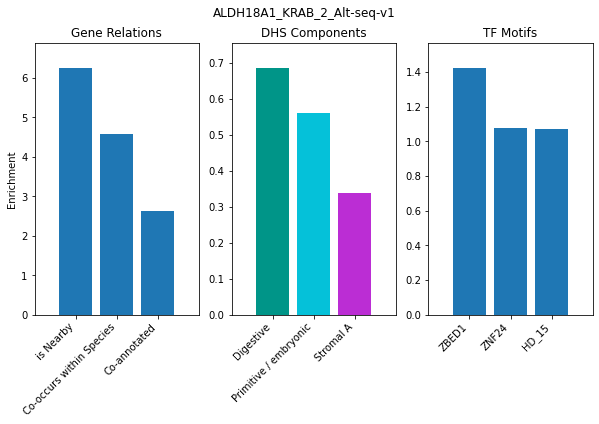

ALDH18A1_KRAB_2_mRNA


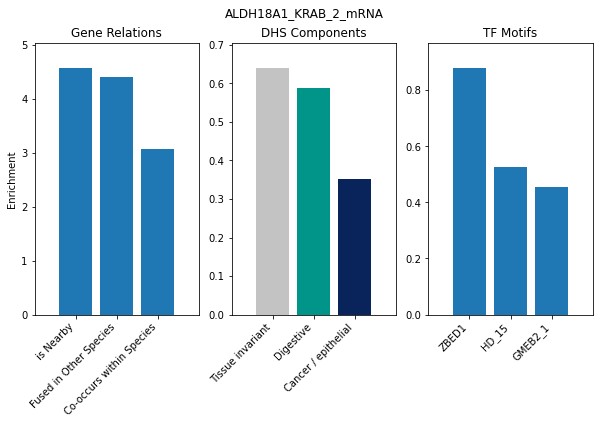

ALDH18A1_KRAB_5_Alt-seq-v1


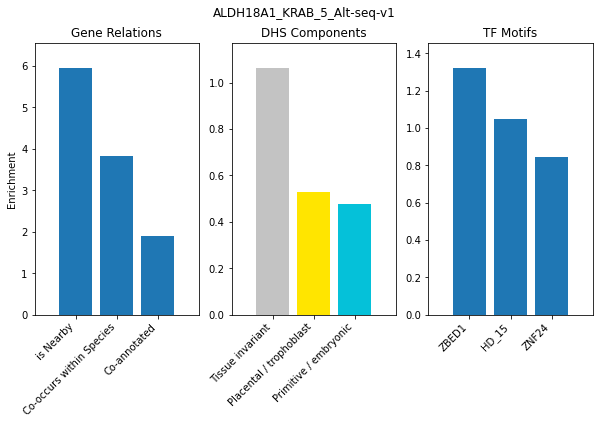

ATR_KRAB_5_mRNA


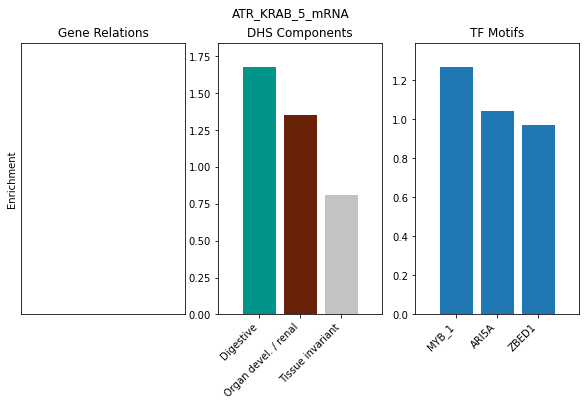

BATF_KRAB_5_Alt-seq-v1


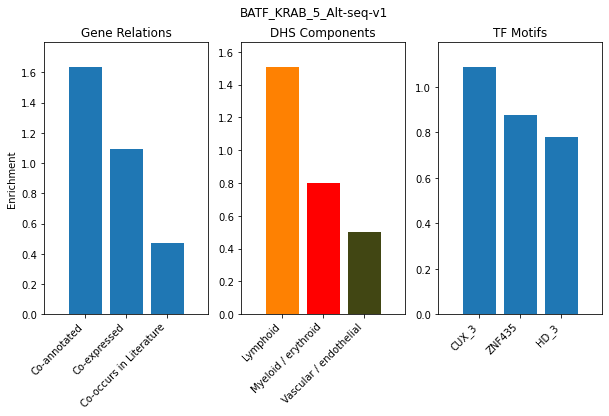

BATF_KRAB_8_Alt-seq-v1


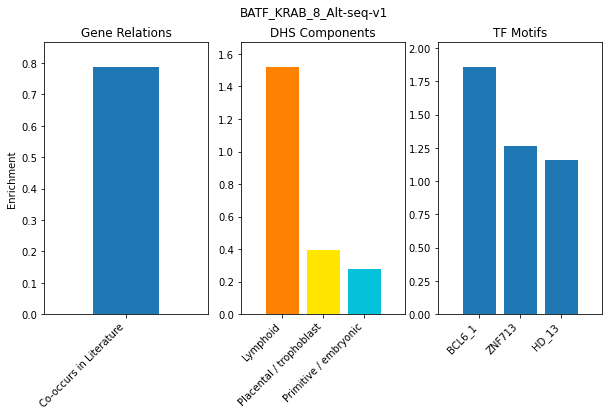

BRCA1_KRAB_2_mRNA


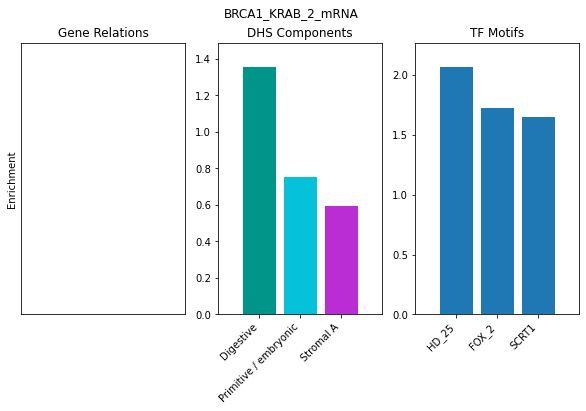

BRCA1_KRAB_5_mRNA


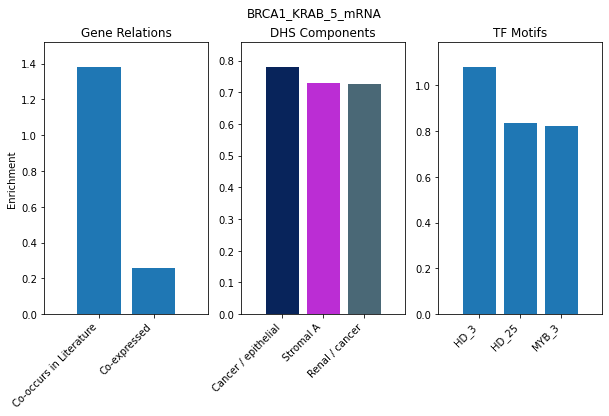

BRCA2_KRAB_2_mRNA


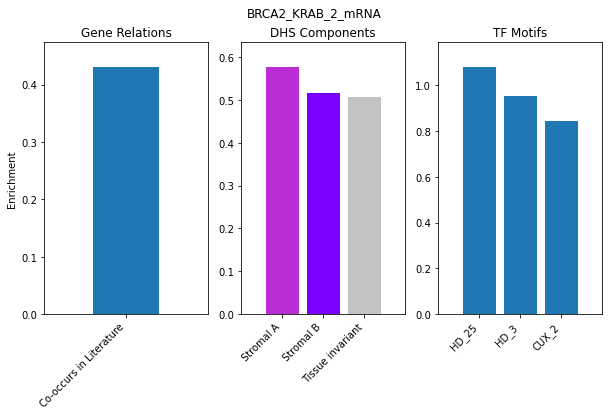

BRCA2_KRAB_5_mRNA


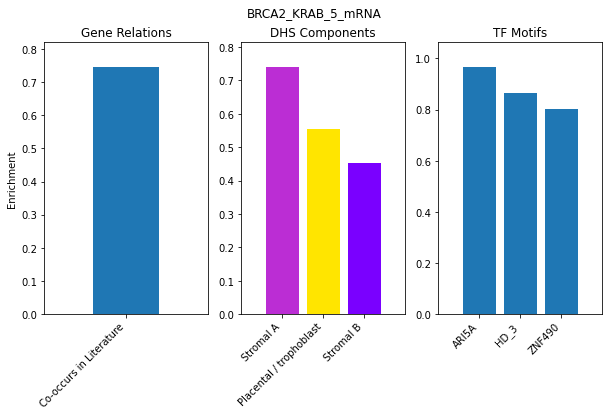

CD6_KRAB_5_Alt-seq-v1


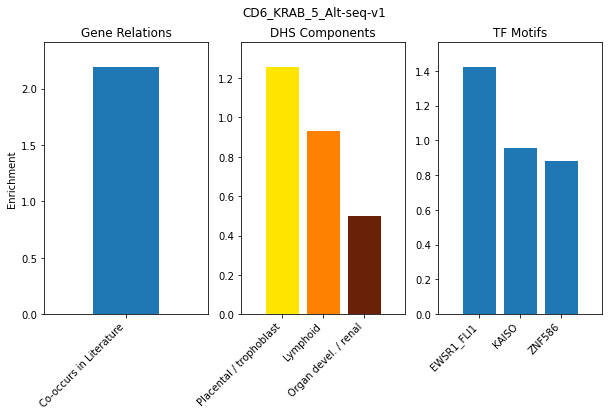

CDK2_VP64_2_Alt-seq-v1


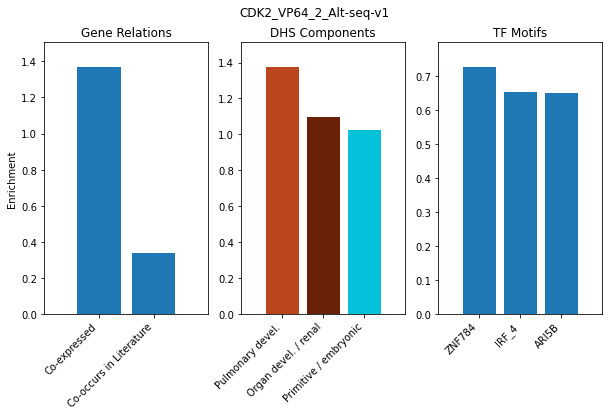

CHD4_KRAB_2_Alt-seq-v1


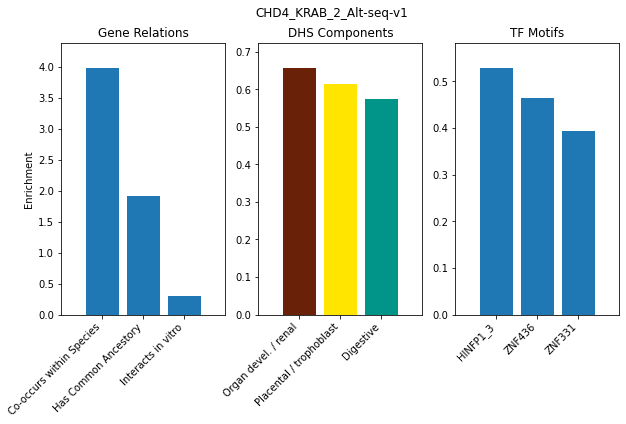

CHD4_KRAB_5_Alt-seq-v1


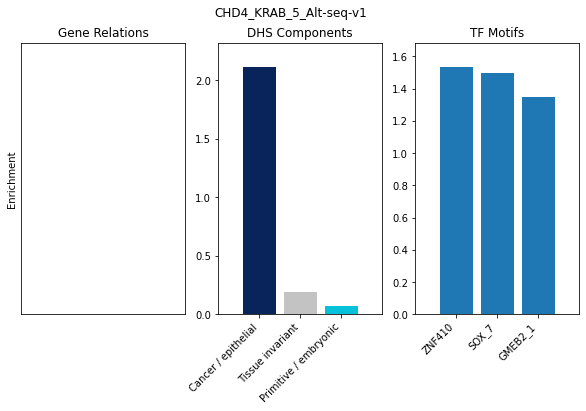

CHMP6_KRAB_5_Alt-seq-v1


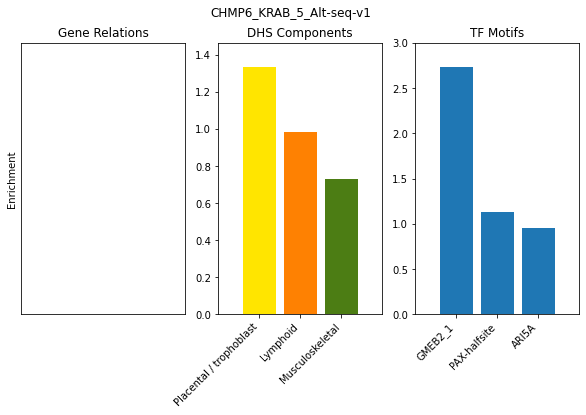

CLCN6_KRAB_2_mRNA


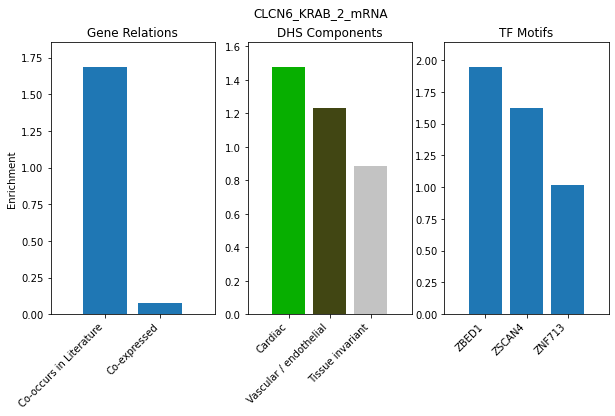

CLCN6_KRAB_5_Alt-seq-v1


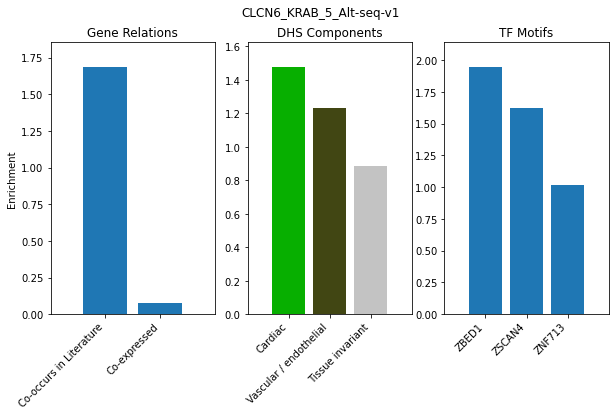

CLPB_KRAB_5_Alt-seq-v1


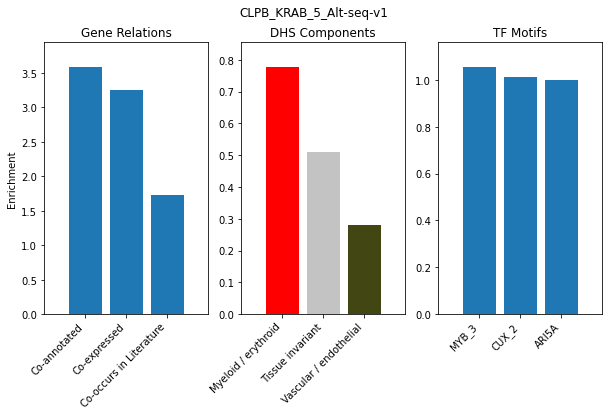

CLPB_KRAB_8_Alt-seq-v1


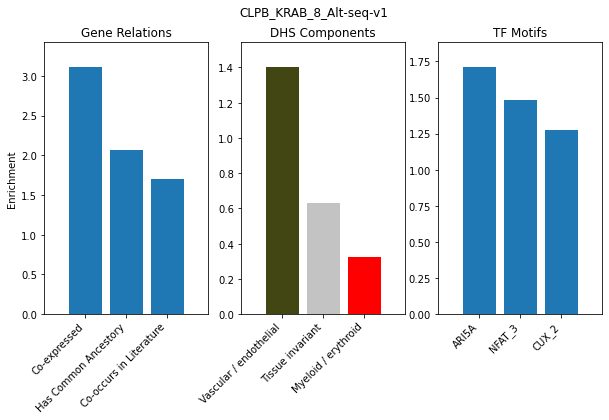

CMIP_KRAB_2_Alt-seq-v1


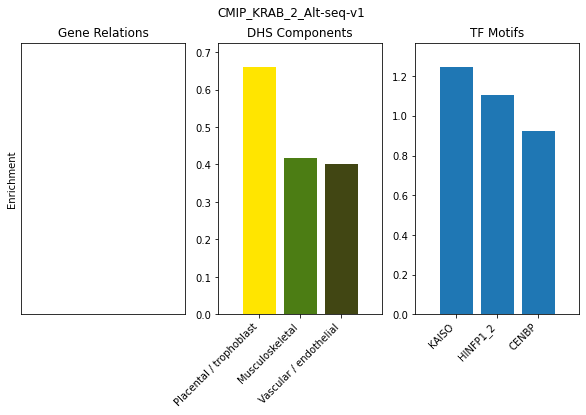

CSAD_KRAB_2_Alt-seq-v1


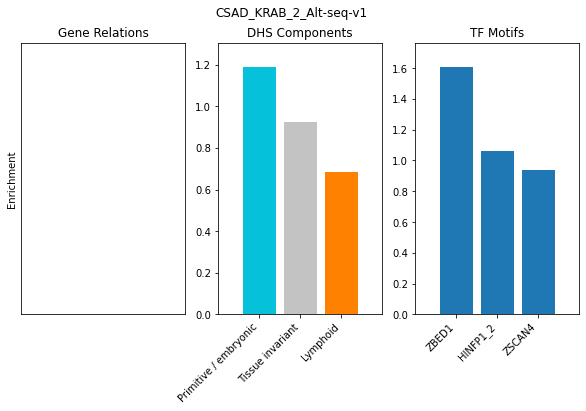

CTSL_KRAB_2_Alt-seq-v1


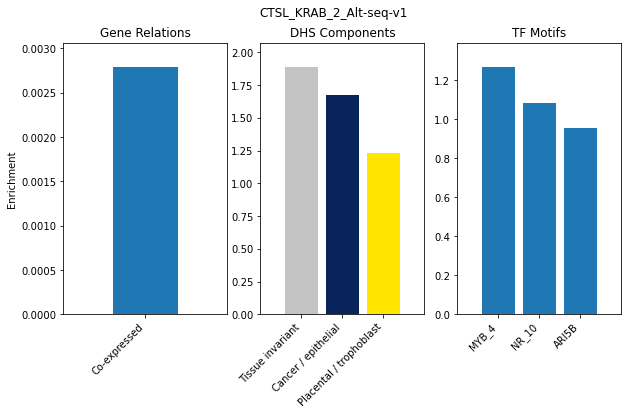

DCLRE1B_KRAB_2_Alt-seq-v0


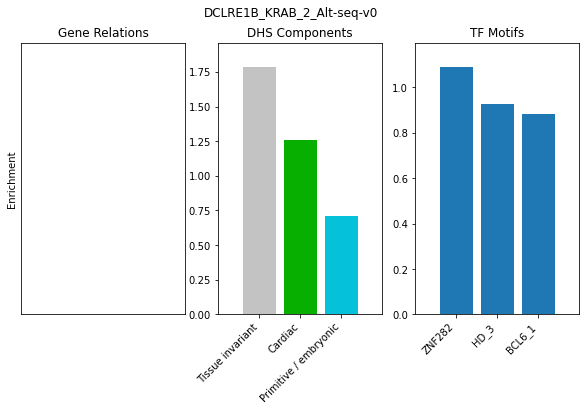

DCLRE1B_KRAB_2_Alt-seq-v1


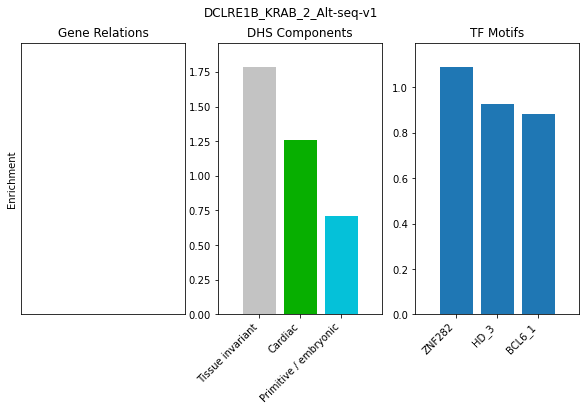

DDOST_KRAB_2_Alt-seq-v1


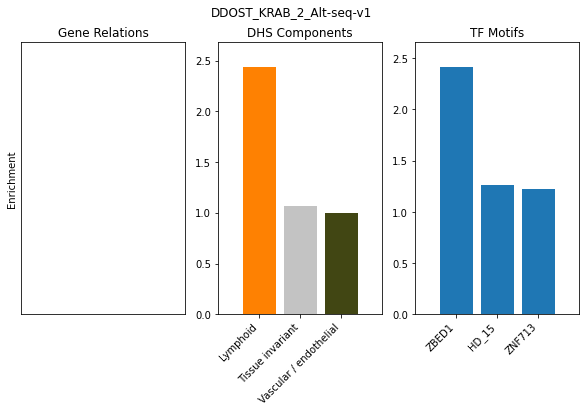

DEF6_VP64_2_Alt-seq-v2


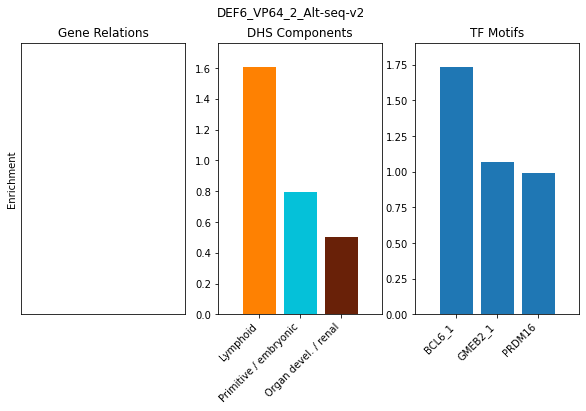

E4F1_KRAB_2_Alt-seq-v1


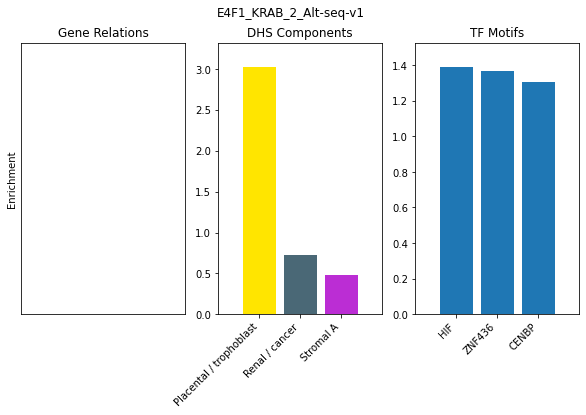

E4F1_KRAB_8_Alt-seq-v1


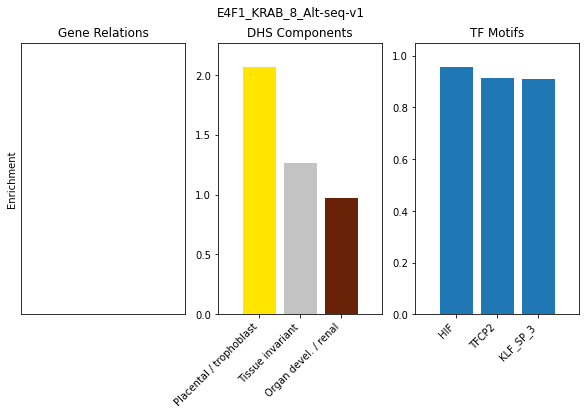

EVL_KRAB_2_Alt-seq-v1


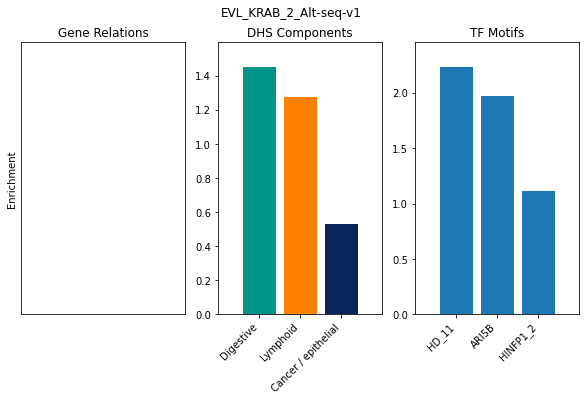

EXOC4_KRAB_8_Alt-seq-v1


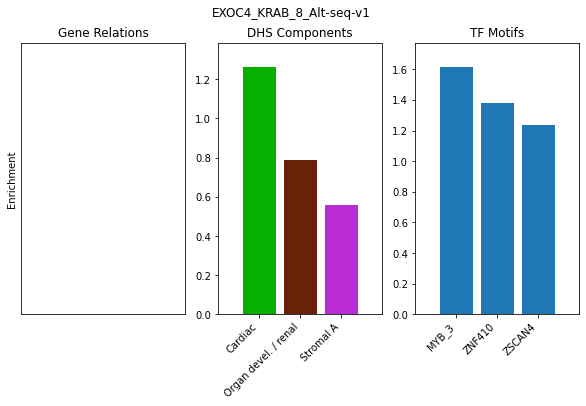

FAS_KRAB_2_Alt-seq-v0


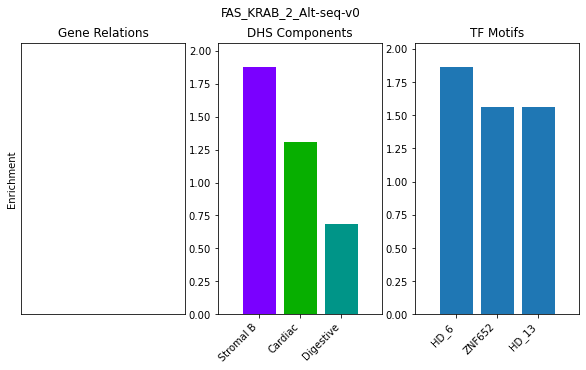

FAS_KRAB_2_mRNA


/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/numpy/core/fromnumeric.py:3440: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/numpy/core/_methods.py:181: RuntimeWarning: invalid value encountered in true_divide
  ret = um.true_divide(
/tmp/ipykernel_104026/1682783786.py:75: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[1].set_ylim([0, max_val_DHS*1.1])
/tmp/ipykernel_104026/1682783786.py:81: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[2].set_ylim([0, max_val_TF*1.1])


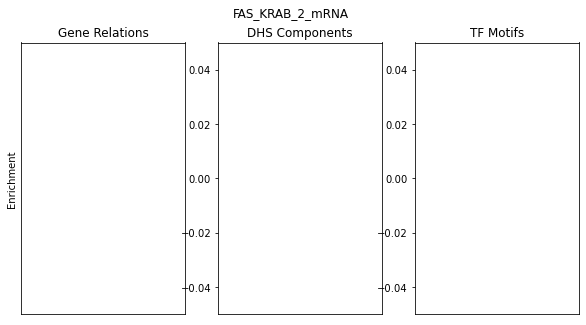

FAS_KRAB_5_mRNA


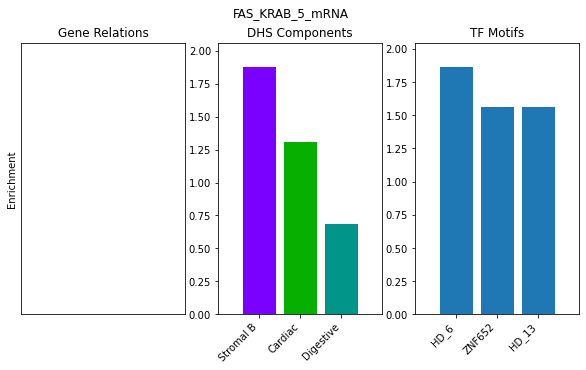

FERMT3_KRAB_5_Alt-seq-v1


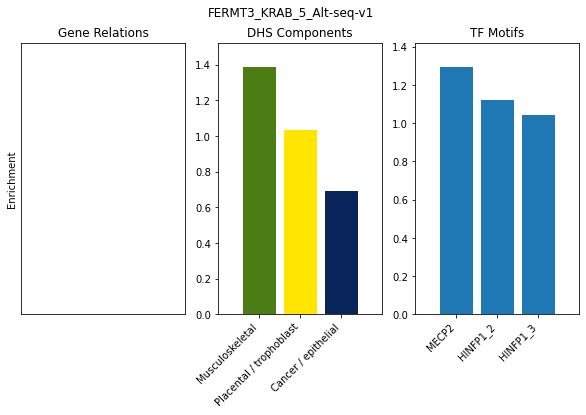

GBP4_KRAB_2_Alt-seq-v1


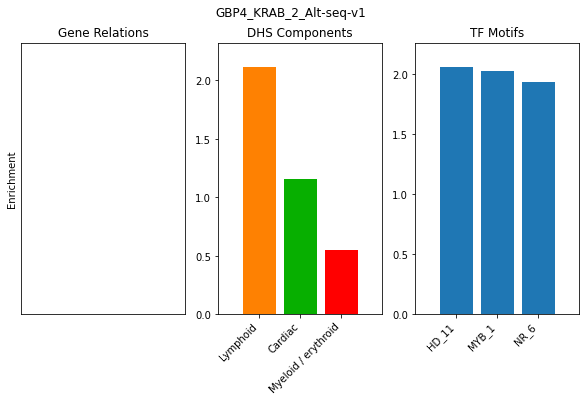

GBP4_KRAB_5_Alt-seq-v1


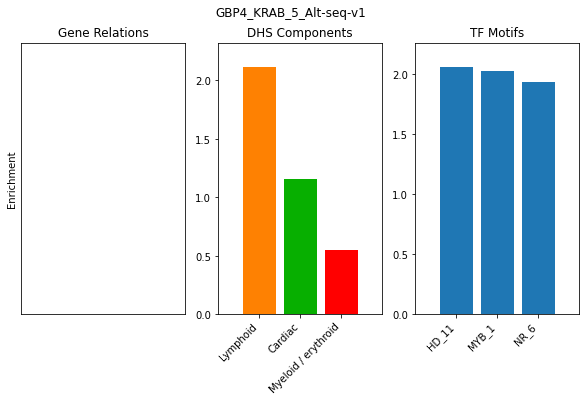

GBP4_KRAB_8_Alt-seq-v1


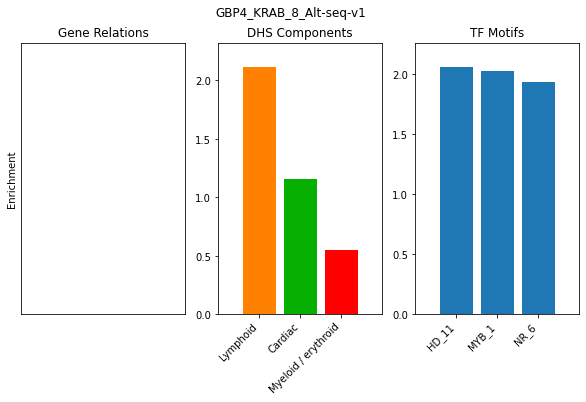

GFM1_KRAB_2_Alt-seq-v1


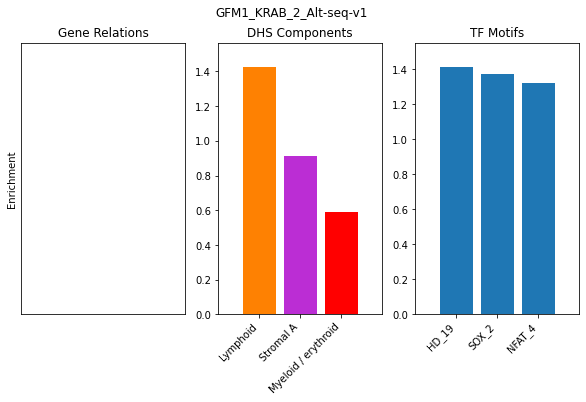

GPR65_KRAB_5_Alt-seq-v1


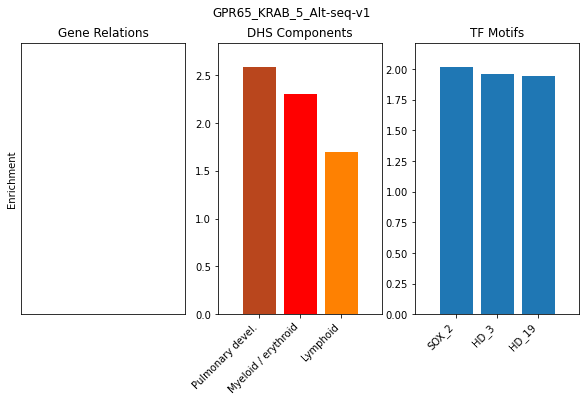

GSTM2_KRAB_2_Alt-seq-v1


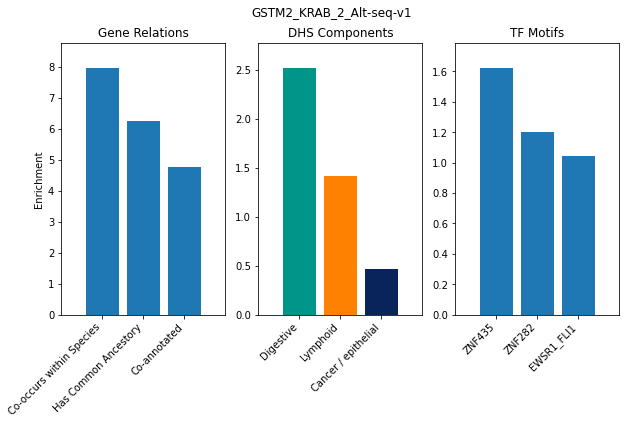

GSTM2_KRAB_5_Alt-seq-v1


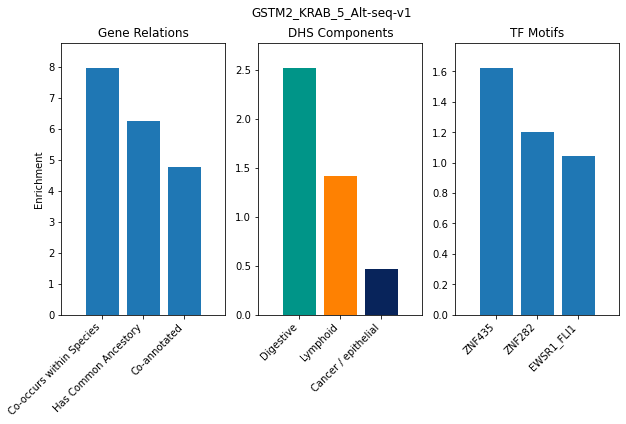

GTF2B_VP64_2_Alt-seq-v1


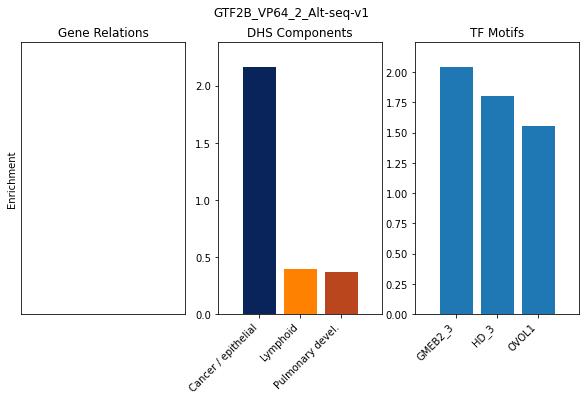

HDAC1_KRAB_2_Alt-seq-v1


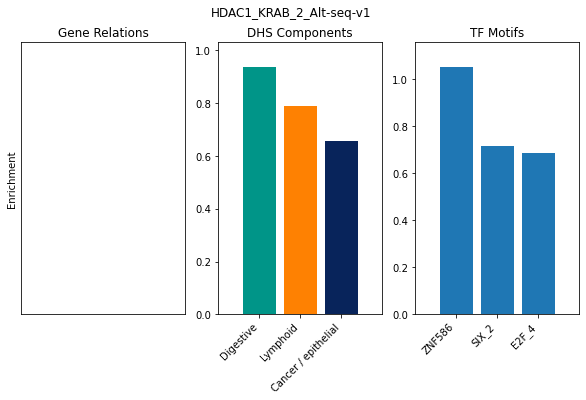

HDAC1_KRAB_5_Alt-seq-v1


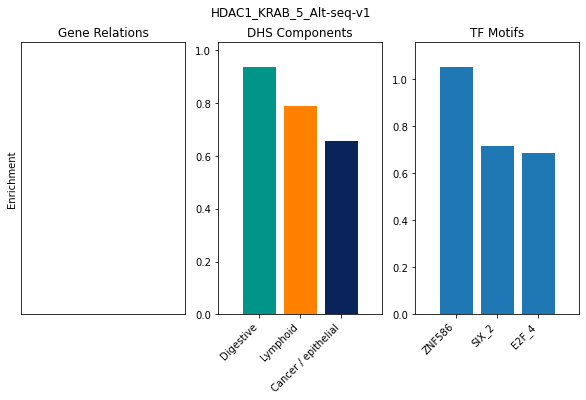

HIF1AN_KRAB_2_Alt-seq-v1


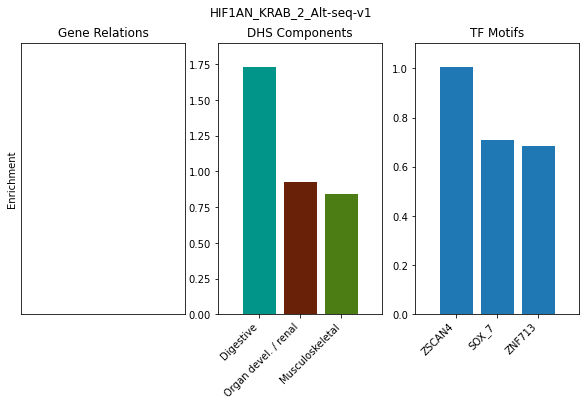

HLA-DQB1_KRAB_2_Alt-seq-v1


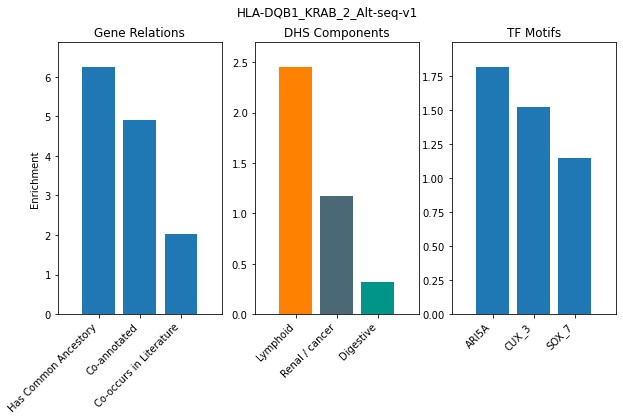

IL2RA_KRAB_5_Alt-seq-v1


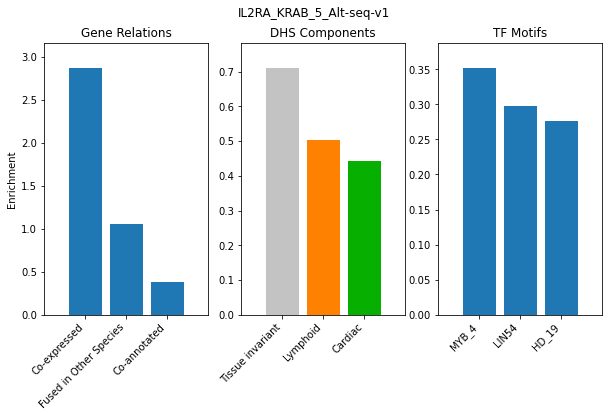

IL2RB_KRAB_2_Alt-seq-v1


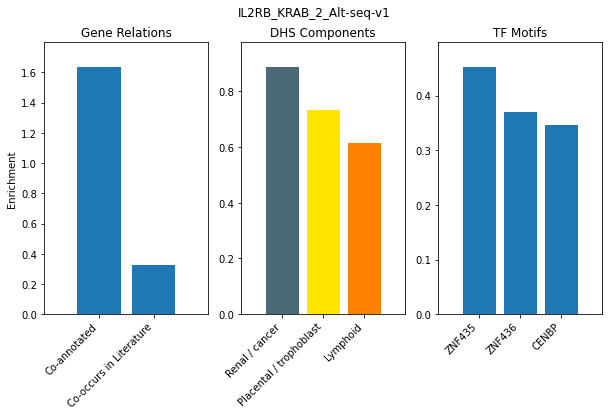

ITGB7_VP64_2_Alt-seq-v1


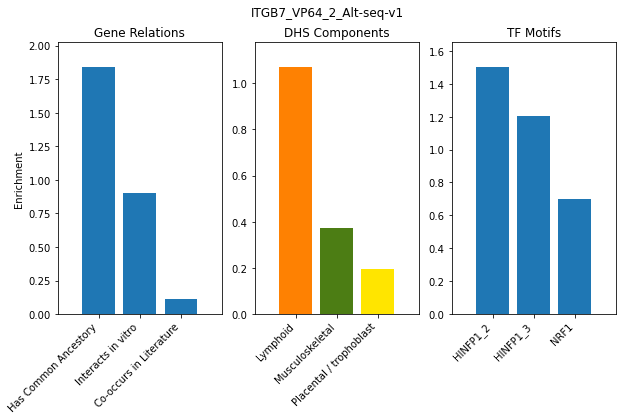

KRAS_VP64_8_Alt-seq-v1


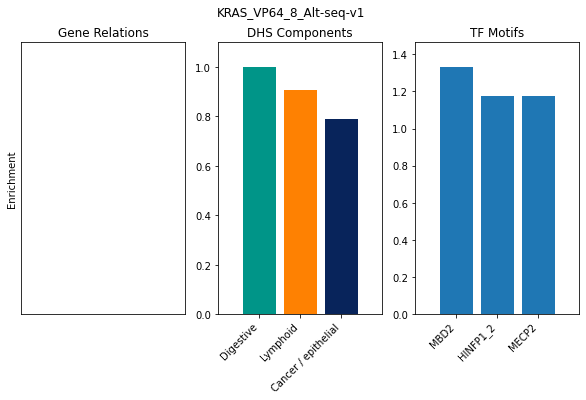

LHX4_VP64_5_Alt-seq-v1


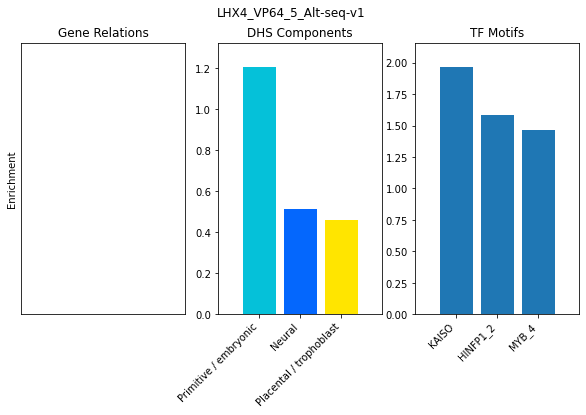

LMTK2_VP64_2_Alt-seq-v1


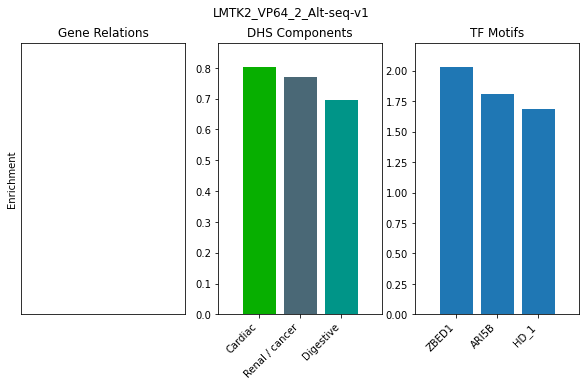

MAPK3_KRAB_2_Alt-seq-v1


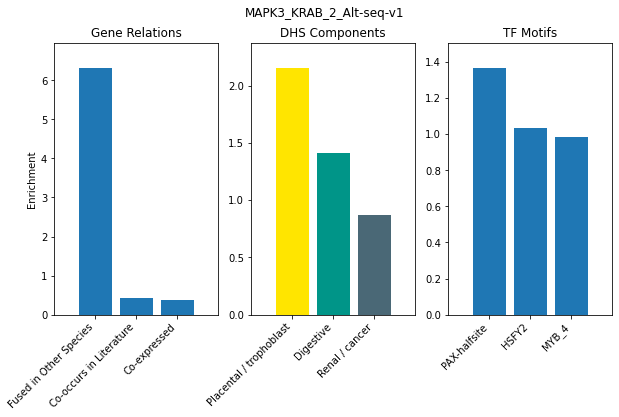

MAPK3_KRAB_2_mRNA


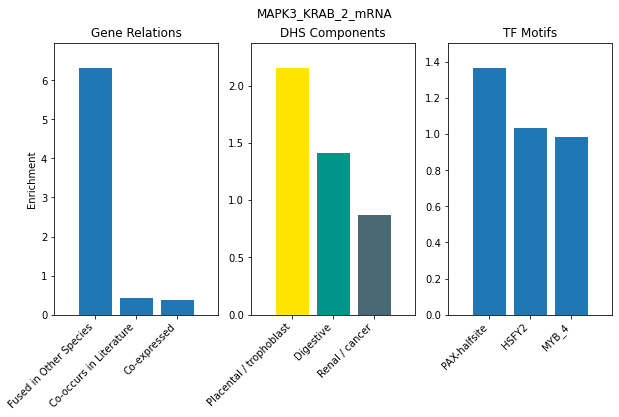

MAPK3_KRAB_5_Alt-seq-v1


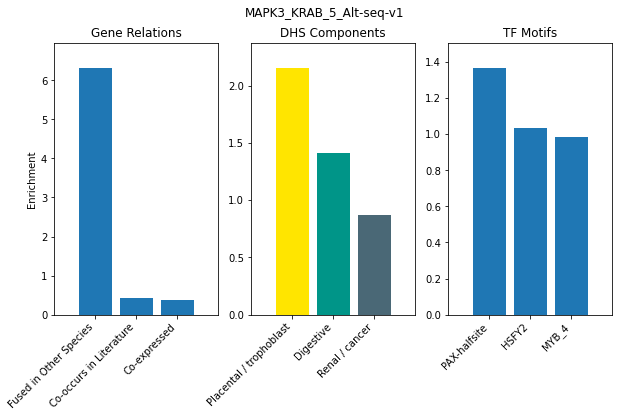

PTPN22_VP64_2_Alt-seq-v1


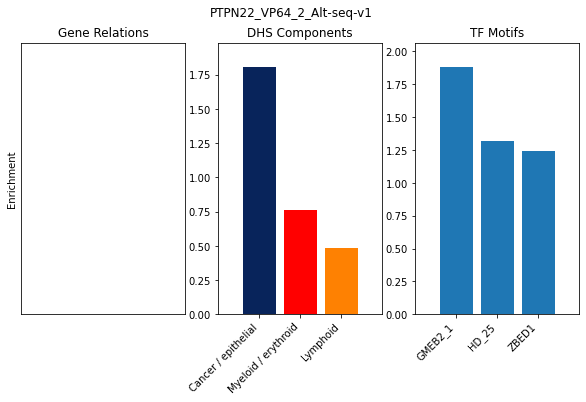

RCL1_VP64_2_Alt-seq-v1


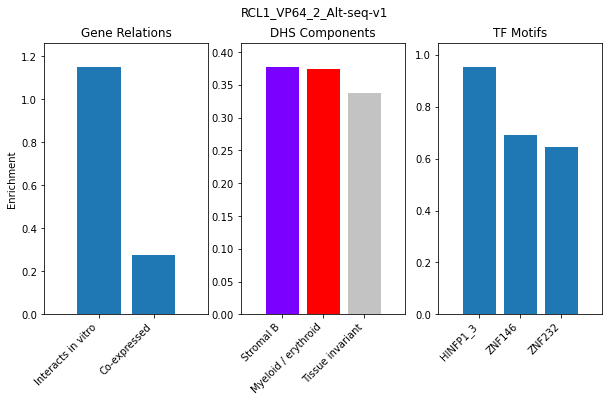

RORC_KRAB_5_Alt-seq-v1


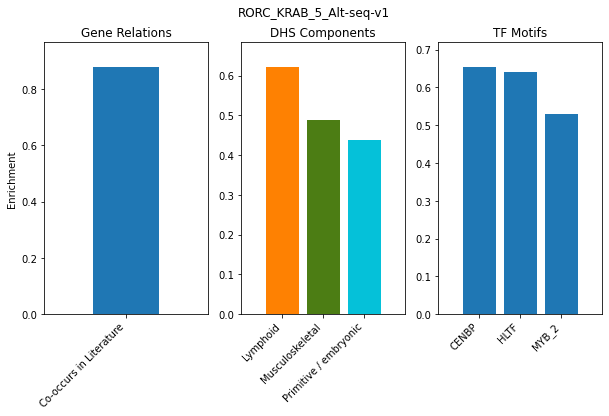

SETDB1_KRAB_2_Alt-seq-v1


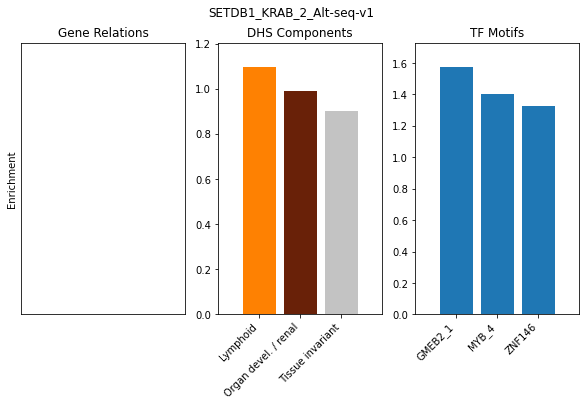

SHOC2_KRAB_2_mRNA


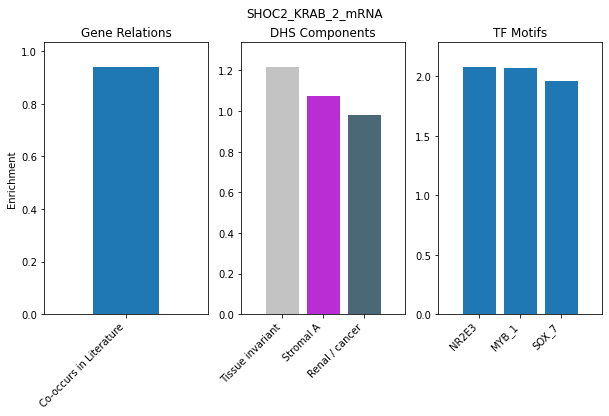

SLC39A14_VP64_2_Alt-seq-v1


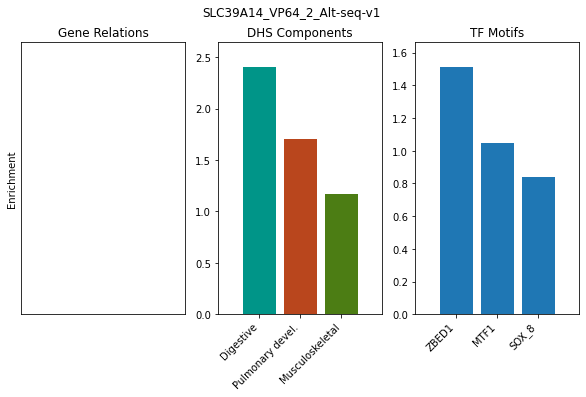

SLC9A9_KRAB_2_Alt-seq-v1


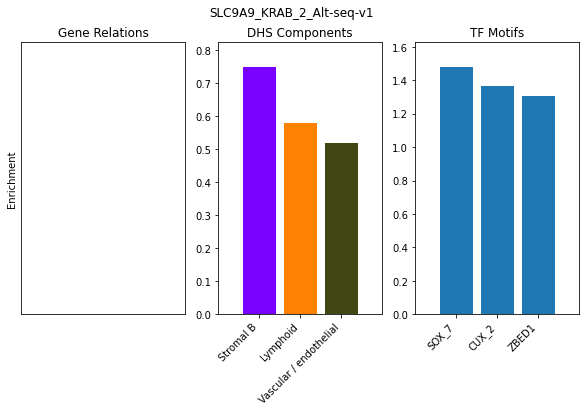

SPINT2_VP64_2_Alt-seq-v1


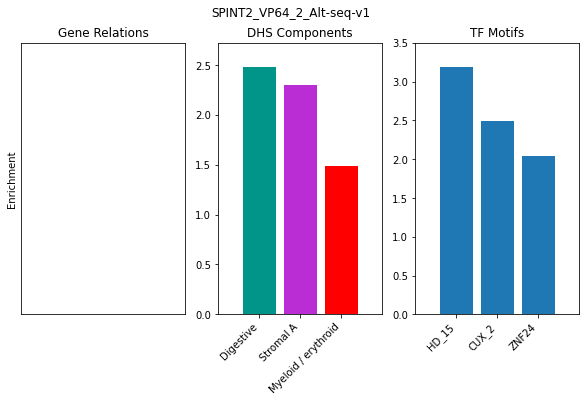

SREBF1_VP64_5_Alt-seq-v1


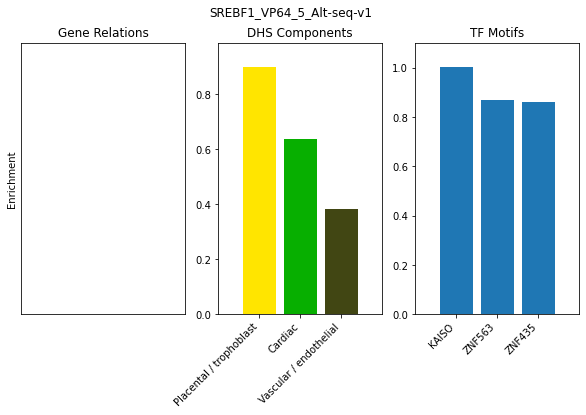

STAT6_KRAB_5_Alt-seq-v1


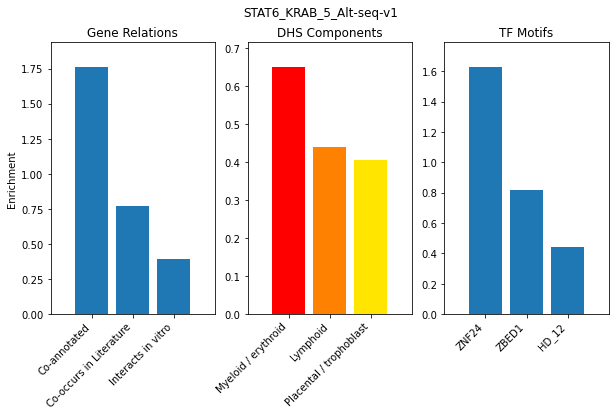

STAT6_KRAB_8_Alt-seq-v1


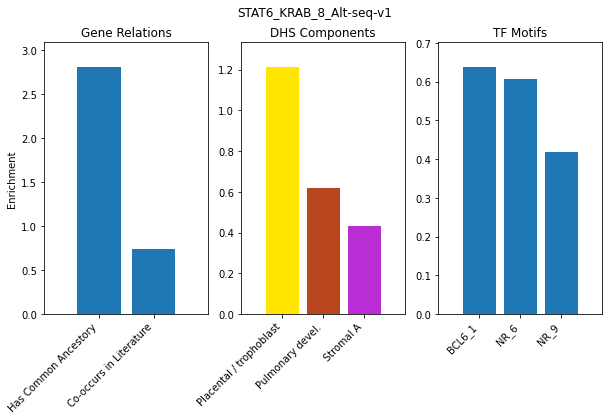

STAT6_VP64_2_Alt-seq-v1


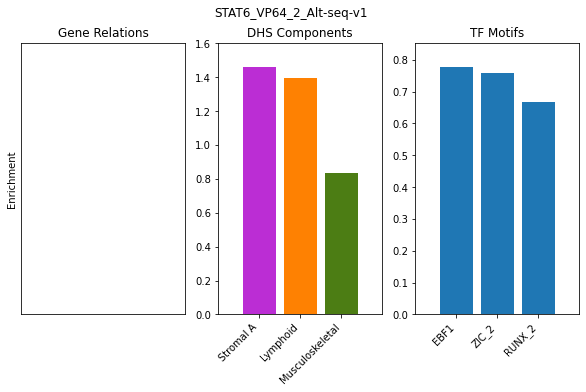

SYVN1_KRAB_5_Alt-seq-v1


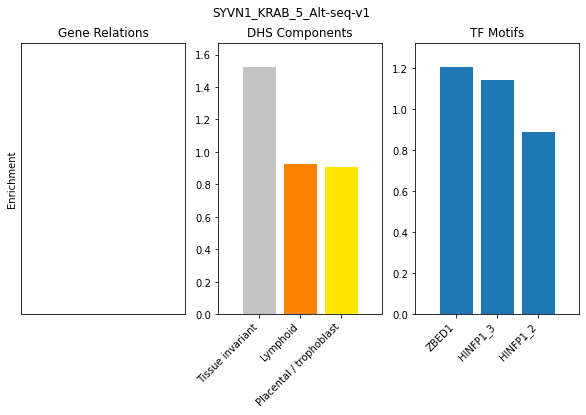

TOP2A_KRAB_2_Alt-seq-v1


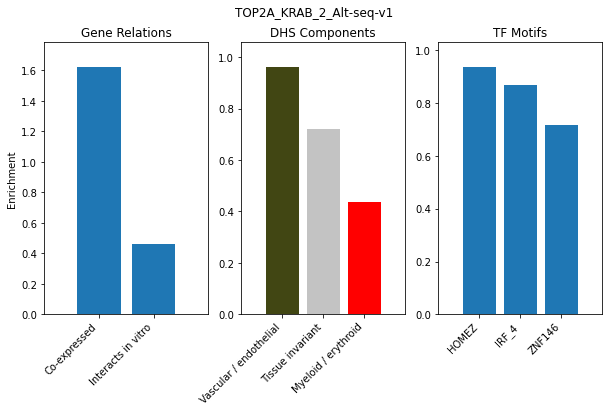

TP53_KRAB_2_mRNA


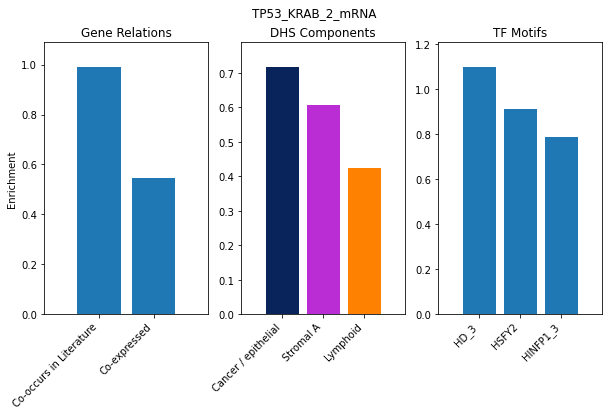

TXNIP_KRAB_2_mRNA


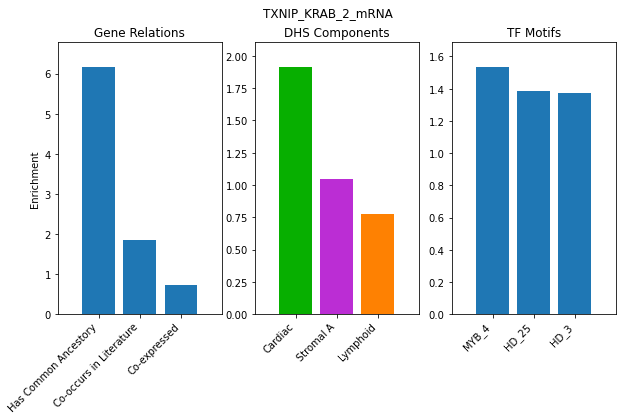

TXNIP_KRAB_5_Alt-seq-v1


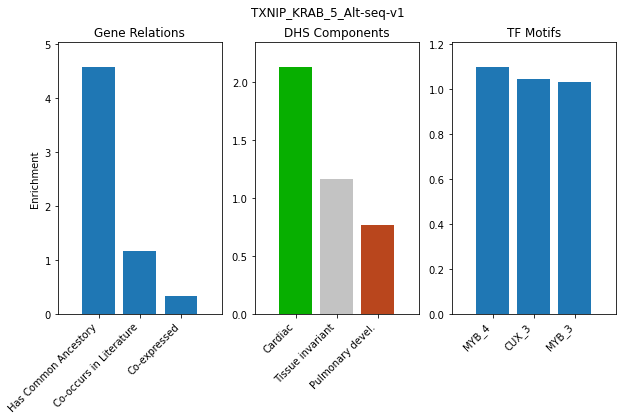

TXNIP_KRAB_5_Alt-seq-v2


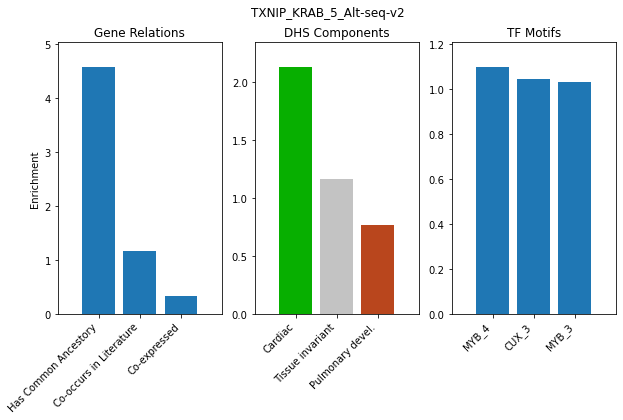

TXNIP_KRAB_5_mRNA


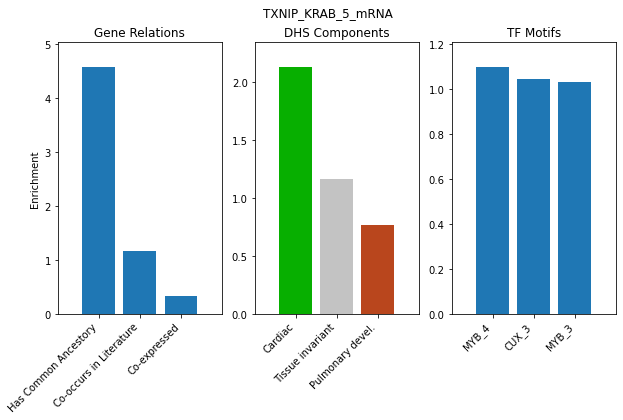

UAP1_KRAB_2_mRNA


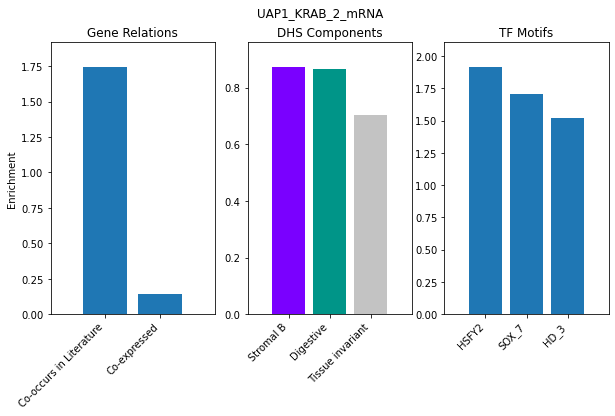

UBE2E2_KRAB_2_mRNA


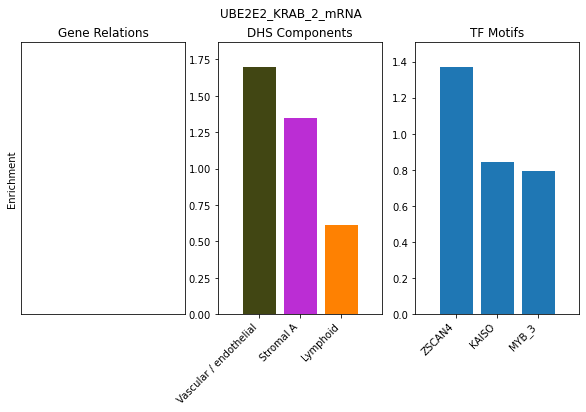

UBE2T_KRAB_2_mRNA


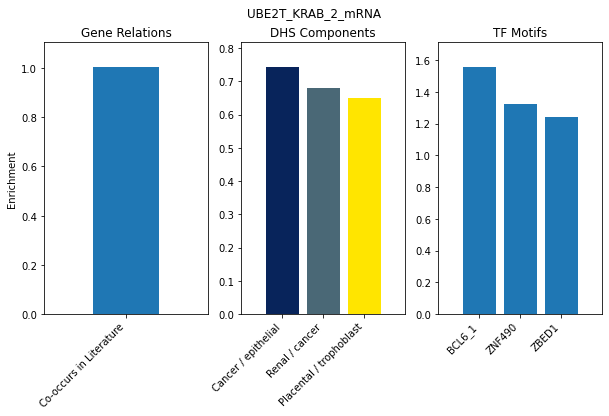

UBE2T_KRAB_5_Alt-seq-cycler


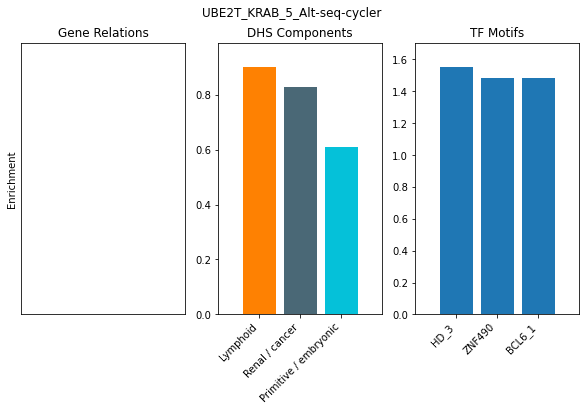

UBE2T_KRAB_5_Alt-seq-v1


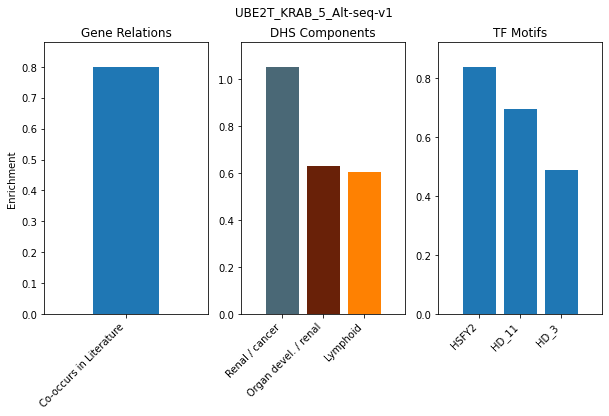

UHMK1_KRAB_2_Alt-seq-v1


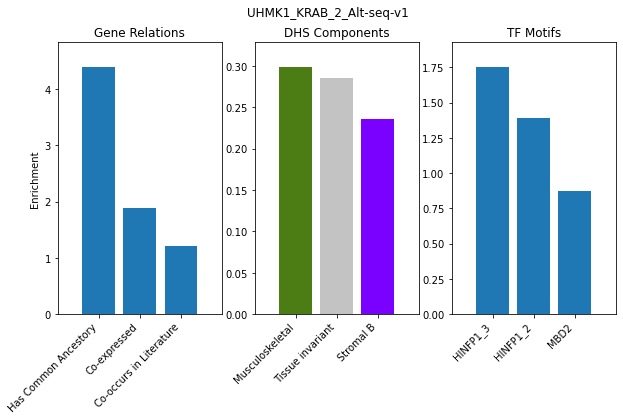

UHMK1_KRAB_5_Alt-seq-v1


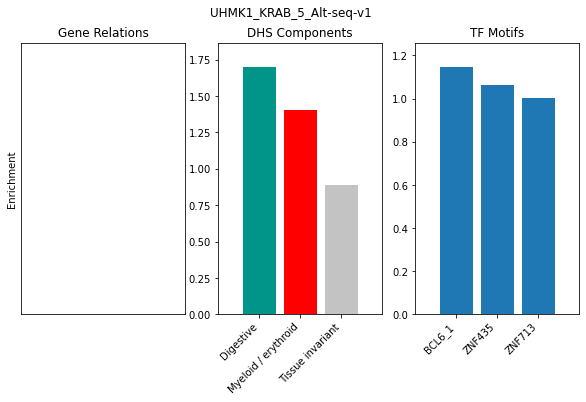

UHMK1_VP64_2_Alt-seq-v1


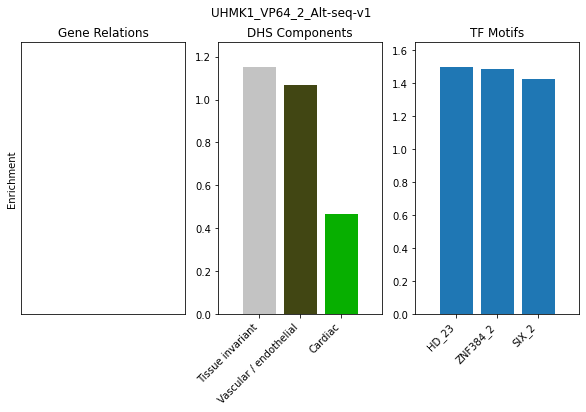

WEE1_KRAB_2_mRNA


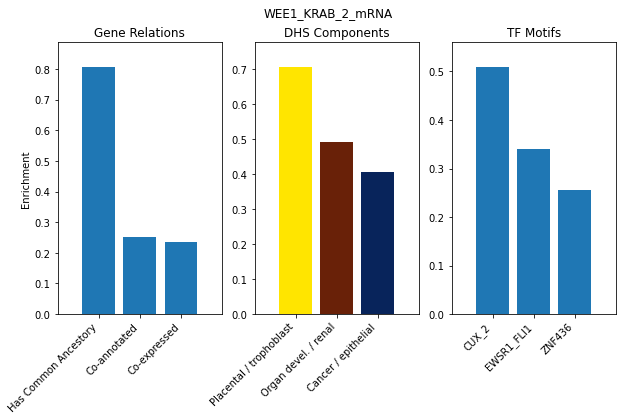

WEE1_KRAB_2_totalRNA


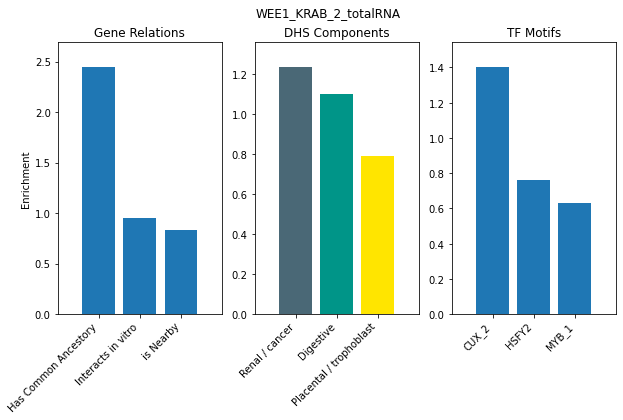

ZBTB39_VP64_2_Alt-seq-v1


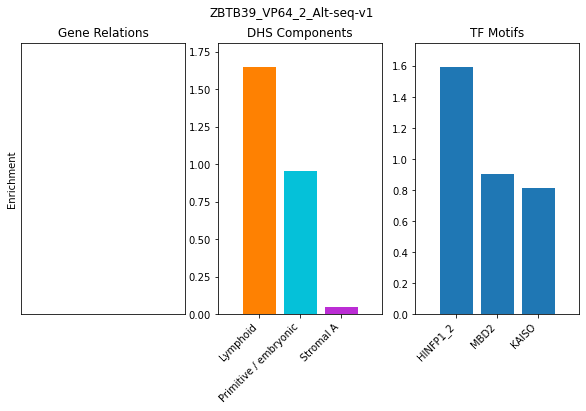

ZMPSTE24_KRAB_2_mRNA


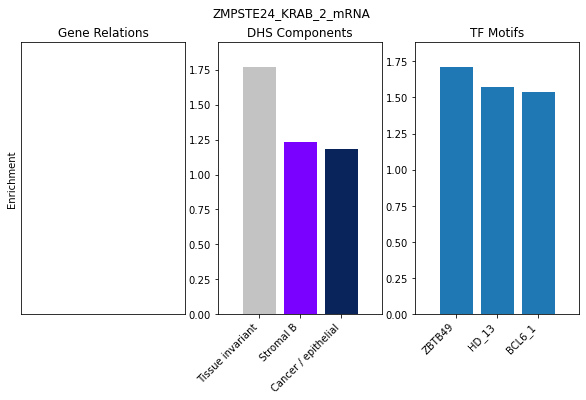

ZMPSTE24_KRAB_5_Alt-seq-v1


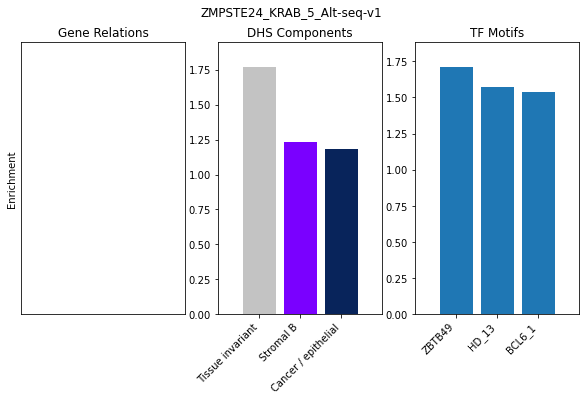

ZNF160_KRAB_8_Alt-seq-v1


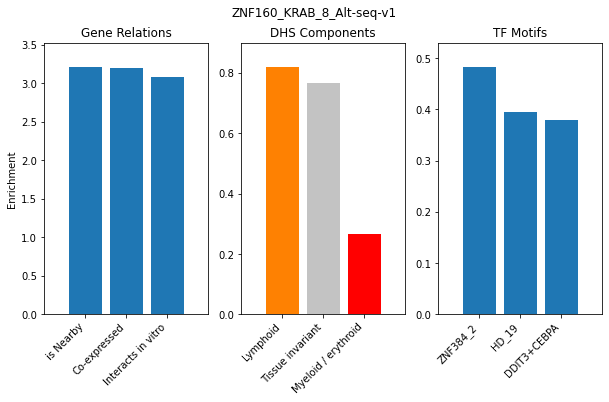

ZNF574_KRAB_2_Alt-seq-v1


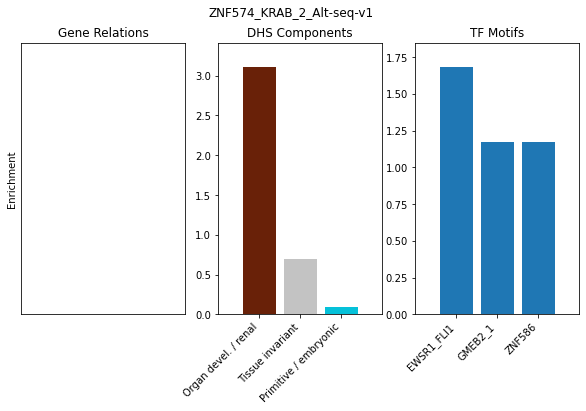

In [24]:
#b plots
for row in exper_plus_genes:
    experiment = row[0]
    print(experiment)
    genes = np.array(row[1:])
    significant_gene_sets, pvals, set_string_mean = set_of_genes_analysis(genes, experiment)
    f = open('/home/ctrader/region_similarity/data/gene_DHS_TF_enrichments/significant_gene_sets.'+experiment+'_CT20220729.txt', 'w')
    for gene_set, pval in zip(significant_gene_sets, pvals):
        f.write(gene_set + '\t' + str(pval) + '\n')
    f.close()

In [26]:
np.where(exper_only=='TXNIP_KRAB_2_mRNA')

(array([75]),)

CLPB_KRAB_5_Alt-seq-v1


<Figure size 720x720 with 0 Axes>

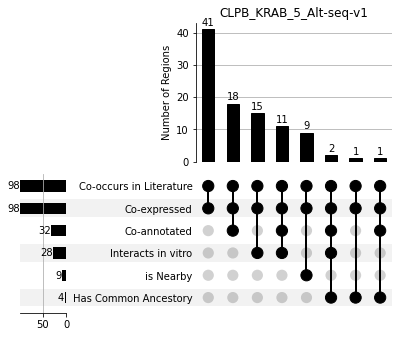

/tmp/ipykernel_11085/299427629.py:85: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_11085/3060825832.py:16: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


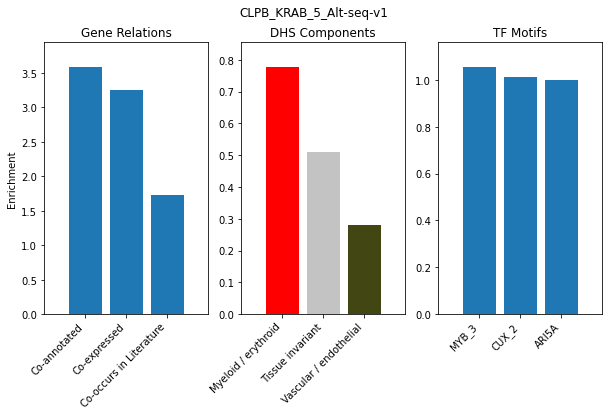

CLPB_KRAB_8_Alt-seq-v1


<Figure size 720x720 with 0 Axes>

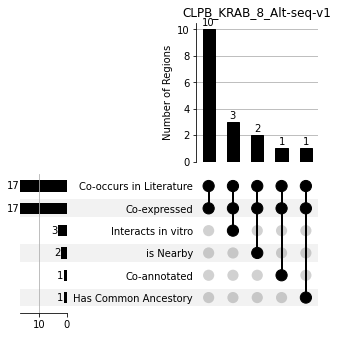

/tmp/ipykernel_11085/299427629.py:85: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_11085/3060825832.py:16: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


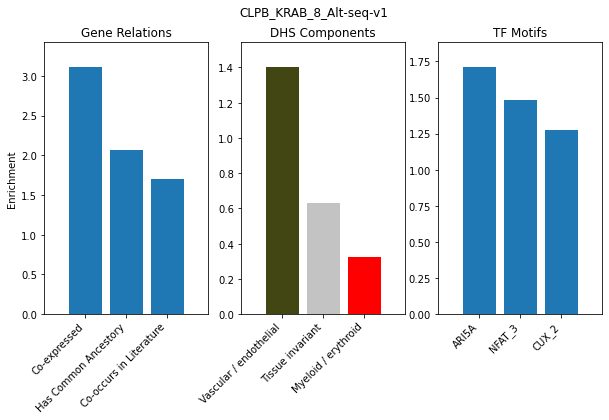

STAT6_KRAB_5_Alt-seq-v1


<Figure size 720x720 with 0 Axes>

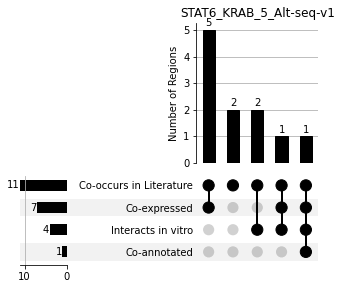

/tmp/ipykernel_11085/299427629.py:85: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_11085/3060825832.py:16: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


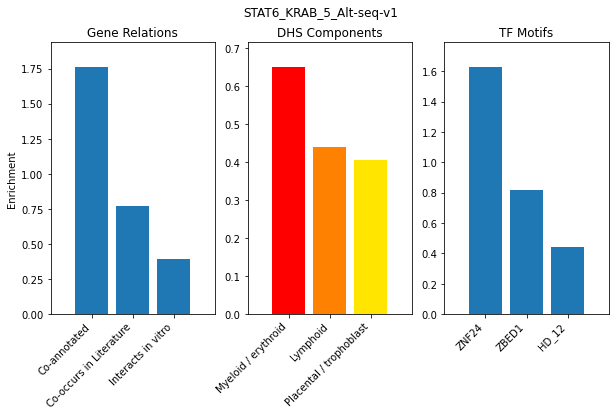

STAT6_KRAB_8_Alt-seq-v1


<Figure size 720x720 with 0 Axes>

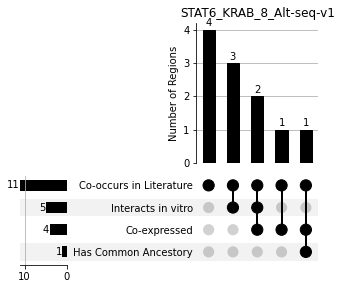

/tmp/ipykernel_11085/299427629.py:85: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_11085/3060825832.py:16: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


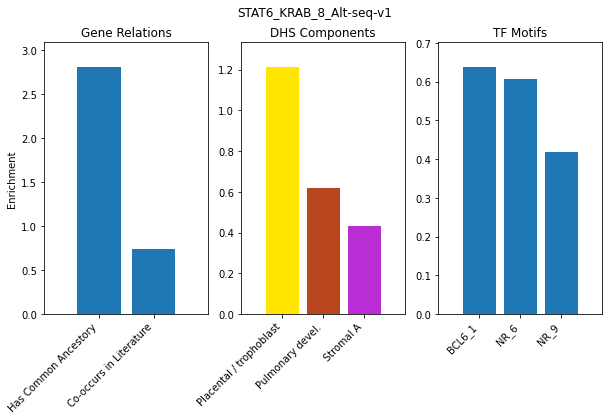

STAT6_VP64_2_Alt-seq-v1


/tmp/ipykernel_11085/3060825832.py:5: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)
/tmp/ipykernel_11085/3060825832.py:12: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_11085/3060825832.py:66: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


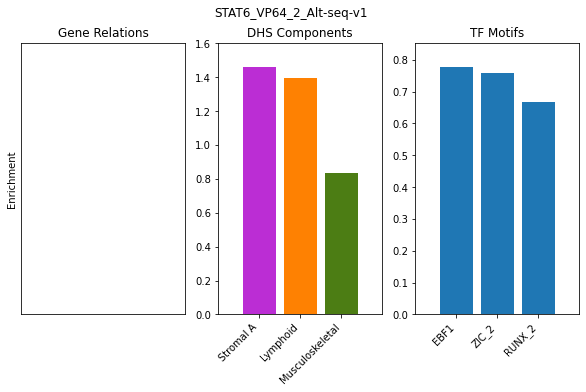

TXNIP_KRAB_2_mRNA


<Figure size 720x720 with 0 Axes>

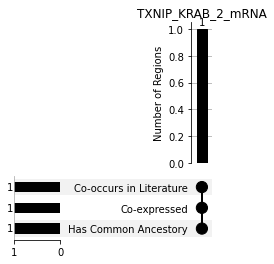

/tmp/ipykernel_11085/299427629.py:85: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_11085/3060825832.py:5: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)
/tmp/ipykernel_11085/3060825832.py:12: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_11085/3060825832.py:16: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


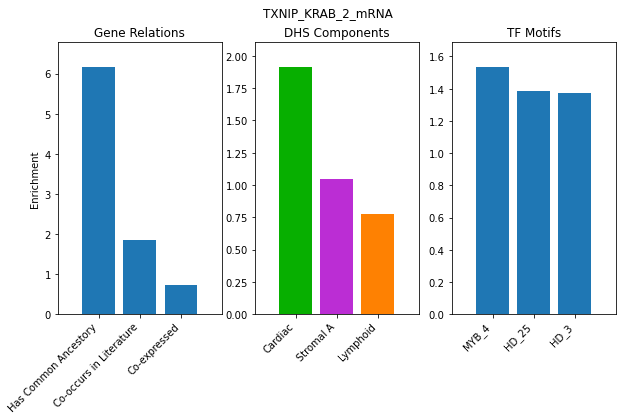

TXNIP_KRAB_5_Alt-seq-v1


<Figure size 720x720 with 0 Axes>

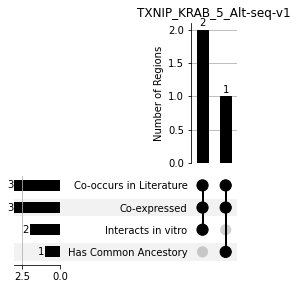

/tmp/ipykernel_11085/299427629.py:85: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_11085/3060825832.py:5: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)
/tmp/ipykernel_11085/3060825832.py:12: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_11085/3060825832.py:16: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


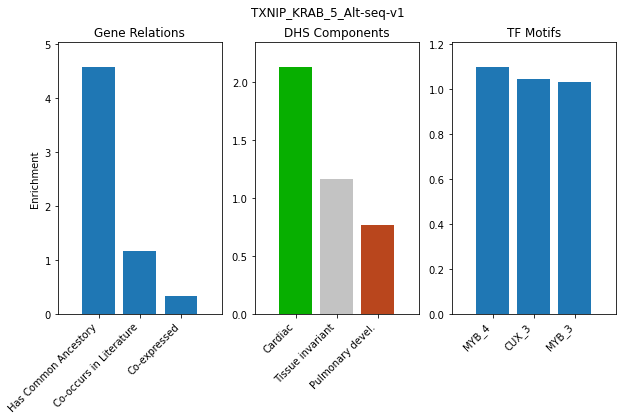

TXNIP_KRAB_5_Alt-seq-v2


<Figure size 720x720 with 0 Axes>

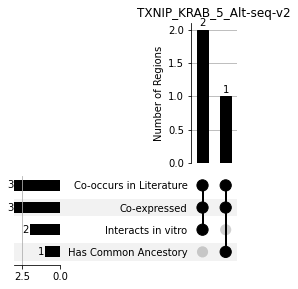

/tmp/ipykernel_11085/299427629.py:85: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_11085/3060825832.py:5: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)
/tmp/ipykernel_11085/3060825832.py:12: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_11085/3060825832.py:16: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


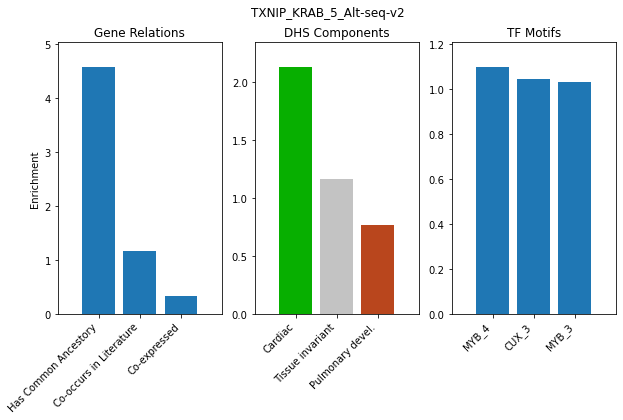

TXNIP_KRAB_5_mRNA


<Figure size 720x720 with 0 Axes>

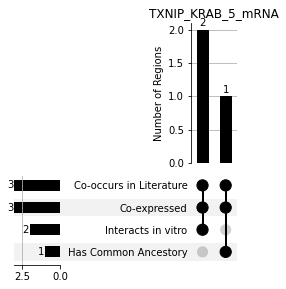

/tmp/ipykernel_11085/299427629.py:85: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_11085/3060825832.py:5: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)
/tmp/ipykernel_11085/3060825832.py:12: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_11085/3060825832.py:16: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


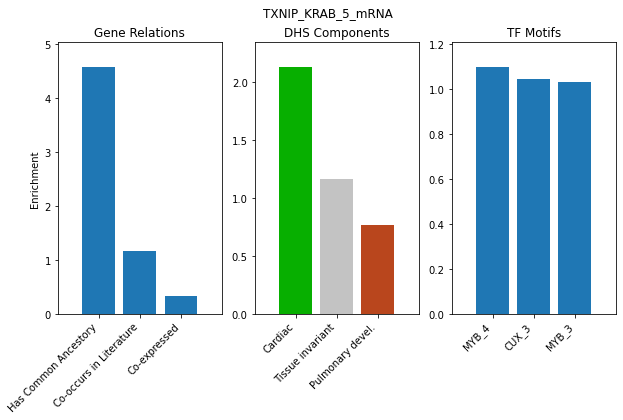

In [59]:
#b plots
for i in [22, 23, 69, 70, 71, 75, 76, 77, 78]:
    row = exper_plus_genes[i]
    experiment = row[0]
    print(experiment)
    genes = np.array(row[1:])
    significant_gene_sets, pvals, set_string_mean = set_of_genes_analysis(genes, experiment)
    f = open('/home/ctrader/region_similarity/data/gene_DHS_TF_enrichments/significant_gene_sets.'+experiment+'_CT20220802.txt', 'w')
    for gene_set, pval in zip(significant_gene_sets, pvals):
        f.write(gene_set + '\t' + str(pval) + '\n')
    f.close()

<Figure size 720x720 with 0 Axes>

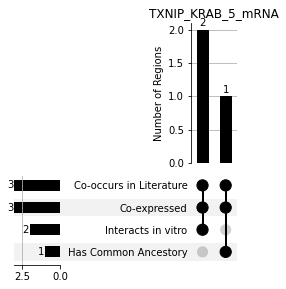

In [53]:
gene_list = genes
title=experiment

#filter oout genes that don't have gene ids 
gene_list_filtered = gene_list[np.isin(gene_list, np.array(list(gene2id.keys())))]
#filter out genes without a region
gene_list_filtered = gene_list_filtered[np.isin(gene_list_filtered, 
                                                np.array(list(gene2promoterregion.keys())))]
#filter out genes not in gene dhs df
gene_list_filtered = gene_list_filtered[np.isin(gene_list_filtered, np.array(gene_dhs_df.index))]

ids_to_test = np.array([])
for gene in gene_list_filtered:
    ids_to_test = np.append(ids_to_test, gene2id[gene])
ids_to_test_set = set(ids_to_test)

#collecting all associations from genes of interest
string_scores_for_ids = []
filename = '/home/ctrader/region_similarity/data/9606.protein.links.full.v11.5.txt'
f = open(filename, 'r')
for line in f.readlines()[1:]:
    line = line.strip().split(' ')
    if line[0].split('.')[1] in ids_to_test_set:
        line[0] = line[0].split('.')[1]
        line[1] = line[1].split('.')[1]
        string_scores_for_ids.append(line)
string_scores_for_ids = np.array(string_scores_for_ids)
f.close()


#if ids have gene associations
scores_g = []
for row in string_scores_for_ids:
    new_row = []
    if row[0] in id2gene:
        new_row.append(id2gene[row[0]])
    else:
        new_row.append(row[0])

    if row[1] in id2gene:
        new_row.append(id2gene[row[1]])
    else:
        new_row.append(row[1])

    for i in range(2, len(row)):
        new_row.append(row[i])
    scores_g.append(new_row)
scores_g = np.array(scores_g)

if len(scores_g) > 0:
    #Dataframe
    set_df = pd.DataFrame(scores_g, columns = ['Gene1', 'Gene2', 'neighborhood', 'neighborhood_transferred',
                                               'fusion', 'cooccurence', 'homology', 'coexpression',
                                               'coexpression_transferred', 'experiments', 'experiments_transferred',
                                               'database', 'database_transferred', 'textmining', 'textmining_transferred',
                                               'combined_score'])

    set_df.loc[:, set_df.columns[2:]] = set_df[set_df.columns[2:]].astype(int)

    #combine human and transferred scores
    set_df['neighborhood'] = set_df[['neighborhood_transferred', 'neighborhood']].max(axis=1).astype(int)
    set_df['coexpression'] = set_df[['coexpression_transferred', 'coexpression']].max(axis=1).astype(int)
    set_df['experiments'] = set_df[['experiments_transferred', 'experiments']].max(axis=1).astype(int)
    set_df['database'] = set_df[['database_transferred', 'database']].max(axis=1).astype(int)
    set_df['textmining'] = set_df[['textmining_transferred', 'textmining']].max(axis=1).astype(int)
    set_df = set_df[['Gene1', 'Gene2', 'neighborhood', 'fusion', 'cooccurence', 'homology', 'coexpression', 
                     'experiments', 'database', 'textmining', 'combined_score']]


    set_used_associations = set()
    for index in np.array(set_df.index):
        tup = (set_df.loc[index]['Gene1'], set_df.loc[index]['Gene2'])
        tup = tuple(np.sort(tup))
        if tup in set_used_associations:
            set_df = set_df.drop(index)
        else:
            set_used_associations.add(tup)

    set_df_inter = set_df[set_df['Gene2'].isin(gene_list_filtered)]

    if len(set_df_inter) > 0:
        data_for_upset = set_df_inter.iloc[:, 2:-1].to_numpy()
        labels_for_upset = ['is Nearby', 'Fused in Other Species', 'Co-evolved', 'Has Common Ancestory', 
                            'Co-expressed', 'Interacts in vitro', 'Co-annotated', 'Co-occurs in Literature']
#         make_upset(data_for_upset, labels_for_upset, title)


<Figure size 720x720 with 0 Axes>

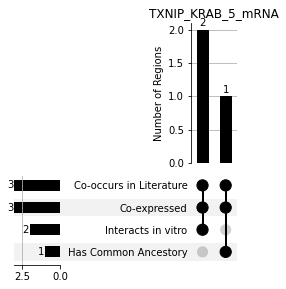

<Figure size 432x288 with 0 Axes>

In [55]:
bool_for_upset = np.where(data_for_upset>0, True, False)
indicators_for_upset = {}
for i, l in zip(range(len(labels_for_upset)), labels_for_upset):
    indicators_for_upset[l] = bool_for_upset[:, i]

upset_data = upsetplot.from_indicators(indicators_for_upset)
upset_data = upset_data.groupby(list(upset_data.index.names)).count()

#sorting upset categories
upset_factors = np.array(upset_data.index.names)
upset_factor_counts = np.array([])
for i in range(len(upset_factors)):
    upset_factor_counts = np.append(upset_factor_counts, np.sum(upset_data.unstack(level=i)[True]))
upset_factors_sorted = upset_factors[np.argsort(upset_factor_counts)]
sorted_upset_data = upset_data.reorder_levels(upset_factors_sorted)

fig = plt.figure(figsize=(10,10))

upsetplot.plot(sorted_upset_data, sort_categories_by=None, min_subset_size=1, show_counts=True, sort_by='cardinality')
#     plt.yscale('log')

plt.ylabel('Number of Regions')
plt.title(title)

plt.show()
plt.savefig('/home/ctrader/region_similarity/data/gene_DHS_TF_enrichments/' + title + '_upset_test2_CT20220802.pdf', 
            bbox_inches='tight', 
            dpi=400, 
            facecolor="#FFFFFF", 
            edgecolor="#FFFFFF", 
            transparent=False)
